# DataRetail 360 · Integración analítica confiable
## Evaluación Parcial 3 — IDY1102
**Estructuras y Visualización de Datos · Oscar Muñoz**  
**Entorno:** PostgreSQL + CSV de marketing + Excel de reportes → Python/Pandas → DWH SQL Server 2025 → 4 data marts.  
**Modalidad:** notebook técnico, ejecutable y documentado, con historial Git local.

Este trabajo integra las fuentes del caso para disponer información consistente de ventas,
clientes, productos, inventario y campañas. La empresa presenta cifras contradictorias porque
mezcla estados, impuestos, devoluciones, horarios y fuentes duplicadas. El objetivo de esta etapa
es construir la base analítica, demostrar calidad e historia temporal y publicar data marts de negocio para el consumo BI.

### Ruta de lectura y evaluación
| Criterio (20% cada uno) | Evidencia prevista |
|---|---|
| Modelo dimensional | Bus Matrix, diagrama, grano y diccionario |
| SCD | Tipos 1/2/3, justificación y pruebas temporales |
| Pipeline | Extracción, contratos, transformación, rechazos y logging |
| Almacenamiento | Bronze/Silver/Gold, DWH SQL Server y 4 data marts dependientes |
| Documentación | Decisiones, resultados, pruebas, linaje y Git |

### Ejecución
Crear el entorno con `python -m venv .venv`, instalar `requirements.txt`, seleccionar ese
intérprete en Jupyter/VS Code y completar `.env` a partir de `.env.example`.
Requiere PostgreSQL local poblado, SQL Server local con autenticación Windows y ODBC Driver 18,
y los archivos `data/raw/marketing/campanias.csv` y `data/raw/legacy/reportes_ventas.xlsx`.
La hoja Excel configurada es `legacy_reporte_ventas_xlsx_2026`. Las dependencias `openpyxl`
y Pandas ya están incluidas en `requirements.txt`.
Ejecutar las celdas en orden. La base `DataRetail360_DW` fue autorizada y creada previamente.
Los datos y logs se guardan en carpetas excluidas de Git. No se imprimen clientes ni credenciales.
El cuaderno es el entregable principal; el entorno, las bases y los archivos generados son sus dependencias.

## 1. Fuentes, alcance y decisiones
Se integran **16 conjuntos de datos mediante tres mecanismos de lectura reales**:

| Fuente física | Conjuntos | Lector | Participación |
|---|---|---|---|
| PostgreSQL `idy1102_ep2` | 14 tablas operacionales `dr360_raw` | `pd.read_sql()` | POS, CRM, e-commerce, inventario, envíos, navegación y devoluciones |
| `data/raw/marketing/campanias.csv` | Campañas comerciales (`mkt_campanias`) | `pd.read_csv()` | Alimenta `dim_campania` y las relaciones con ventas, envíos y sesiones |
| `data/raw/legacy/reportes_ventas.xlsx` | Reportes manuales (`legacy_reporte_ventas_xlsx`) | `pd.read_excel()` | Limpieza y conciliación del histórico agregado |

Los dos archivos fueron exportados por el estudiante desde la base de simulación como
preparación del laboratorio. Durante una ejecución normal **ya existen en `data/raw`**:
el pipeline los consume directamente, sin exportarlos ni consultar sus tablas equivalentes
en PostgreSQL. No se atribuye a esos archivos una procedencia empresarial independiente
que no fue demostrada. Los nombres `mkt_campanias` y `legacy_reporte_ventas_xlsx` son
alias lógicos para reutilizar las transformaciones; no indican que su lector sea SQL.

El DDL proporcionado es el punto de partida del diccionario técnico de columnas esperadas.
`CONTRACT` verifica esas columnas en los tres adaptadores; el tipado y la validación de
valores se realizan después, en Silver. Las tablas `dr360_control` describen la simulación;
solo se consultan sus tres conjuntos de metadatos, fuera del inventario de fuentes de negocio.
Las claves de persona real del generador **no se usan para resolver identidades**: hacerlo
convertiría una respuesta conocida de la simulación en una capacidad inexistente del negocio.

La extracción SQL usa una transacción de solo lectura con instantánea consistente de sus
14 fuentes. Los archivos se congelan por contenido al inicio y se conservan íntegros en Bronze,
junto con sus DataFrames decodificados. El manifiesto registra tipo de fuente, ubicación,
hoja de entrada, conteos y hashes. No existe una transacción global entre PostgreSQL y los archivos;
se necesita una política de fecha de corte compartida para operarlos en producción.
Las transformaciones ocurren en Pandas: es ETL hacia el DWH, con conservación previa de crudos.
Medallion describe las capas de calidad, no obliga a usar Spark.

### Bus Matrix y granularidad
| Proceso | Una fila representa | Fecha | Producto | Sucursal | Cliente | Canal | Campaña |
|---|---|---|---|---|---|---|---|
| Ventas | Línea de documento + sistema POS/ECOM | Sí | Sí | Sí | Sí | Sí | Sí |
| Devoluciones | Registro de devolución | Sí | Sí | Sí | Sí | Sí | No |
| Inventario | Corte semanal × sucursal × producto | Sí | Sí | Sí | No | No | No |
| Campañas | Envío a un registro CRM | Sí | No | No | Sí | No | Sí |
| Web | Sesión | Sí | Producto principal | No | Sí | No | UTM |
| Reposición | Orden de reposición | Solicitud/recepción | Sí | Sí | No | No | No |

Las tablas de hechos no se unen directamente entre sí: se agregan al mismo grano antes de
comparar. El stock es semiaditivo: se suma entre productos/sucursales, **no entre cortes**.
La tabla de envíos no identifica un producto específico; no se inventa esa relación.
Los reportes legacy tienen grano agregado y quedan en una zona independiente de conciliación.

### Dimensiones y jerarquías
`dim_fecha`: día → mes → trimestre → año. `dim_producto`: producto → subcategoría → categoría
→ línea; marca es un atributo paralelo, no un nivel superior de categoría.
`dim_sucursal` y `dim_cliente`: comuna → región → país con roles geográficos distintos.
No se inventan provincia ni coordenadas que no existen en la fuente.
Se elige una constelación de estrellas con dimensiones conformadas; un copo de nieve separaría
geografías/categorías, pero añadiría joins sin necesidad para este volumen y uso académico.
Los miembros desconocidos usan clave 0; el canal digital sin local usa un miembro explícito.

### Contrato de indicadores
- Venta neta POS: documento EMITIDA, `monto_neto` sin IVA; se distribuye a líneas sin perder pesos.
- Venta neta e-commerce: ENTREGADO; mercadería `(subtotal-descuento)/1,19`, sin despacho,
  redondeada a CLP. La tasa 19% es un **supuesto del dataset**, no asesoría tributaria.
- Devoluciones: APROBADA y trazable al documento/producto; se descuentan una sola vez
  en fecha de devolución. Se explicita la base tributaria asumida de `monto_devuelto`.
- DEVUELTO/DEVOLUCION web no se reconoce como venta ENTREGADO. Sus devoluciones no se
  restan otra vez de ventas excluidas. Se informa esta limitación del modelo de estados de la fuente.
- Ticket promedio: venta antes de devoluciones / documentos distintos reconocidos.
- Cliente activo: persona resuelta con compra reconocida en los últimos seis meses respecto
  del corte del dataset; se excluye el cliente desconocido.
- Marketing: conversión reportada y retorno atribuido son indicadores de la plataforma;
  no se presentan como causalidad ni como ingreso conciliado con ventas.
- Inventario: riesgo de reposición según stock de sistema y mínimo; las diferencias con
  stock físico y antigüedad del conteo se reportan, no se corrigen inventando existencias.

Los errores de identidad se resuelven conservadoramente con RUT válido y correo único.
Los emparejamientos ambiguos quedan separados; similitud de nombres no basta para fusionar personas.

### Resultado final: cuatro data marts dependientes
Se publican cuatro áreas analíticas dentro de `DataRetail360_DW`:

| Data mart / esquema SQL Server | Usuarios y preguntas | Procesos del modelo |
|---|---|---|
| **Comercial — `dm_comercial`** | Comercial y Finanzas: venta neta común, canal, sucursal, categorías y clientes | Ventas + devoluciones |
| **Operaciones — `dm_operaciones`** | Operaciones: stock actual, conteos, riesgo, rotación y reposición | Inventario + reposición; ventas conformadas para rotación |
| **Marketing y Digital — `dm_marketing`** | Marketing y canal digital: campañas, consentimiento, sesiones y conversiones | Envíos + navegación, contrastados con ventas y devoluciones agregadas |
| **Clientes — `dm_clientes`** | CRM y Comercial: recurrencia, actividad, recencia y medidas RFM observadas | Compras y devoluciones por identidad resuelta y mes |

La cantidad responde a cuatro dominios de decisión del caso. E-commerce se integra a la venta
omnicanal; marketing y navegación se analizan juntos por adquisición y conversión.
Clientes es un dominio transversal para estudiar comportamiento individual sin confundir versiones SCD con personas. Finanzas consume la misma definición comercial de venta neta. Así se evitan indicadores
departamentales contradictorios y un data mart separado por cada tabla de hechos.
Cada mart tiene un esquema SQL propio, una tabla resumen físicamente persistida, vistas
de hechos y dimensiones conformadas, y una vista de indicadores. Son **dependientes del DWH**:
reutilizan las mismas claves e historia dimensional. Las tablas originales permanecen en `dw`.

### Diagrama del modelo
La siguiente representación resume las relaciones. El archivo `modelo.drawio` contiene el
mismo diseño editable en diagrams.net. Cada hecho conserva su clave natural y las claves
sustitutas de las dimensiones aplicables.

```text
Fecha ─────┬── fact_ventas ───── Producto (SCD2)
Canal ─────┤       │                │
Campaña ───┤       ├── Sucursal ────┼── fact_inventario
Cliente ───┘       │                └── fact_reposicion
 (SCD2)            └── fact_devoluciones
   │
   ├── fact_marketing ── Campaña
   └── fact_web ──────── Producto / Campaña
```

SCD1 corrige atributos descriptivos; SCD2 conserva versiones de región/segmento del cliente
y categoría del producto; SCD3 mantiene zona actual/anterior de la sucursal.
La fuente solo contiene el estado actual: la primera carga **no reconstruye historia real**.
Se marca esa limitación y se demuestran cambios con casos controlados separados del negocio.

La matriz de bus anterior conserva las relaciones del DWH. La publicación final organiza
sus procesos en los cuatro data marts documentados en las secciones 1 y 6.


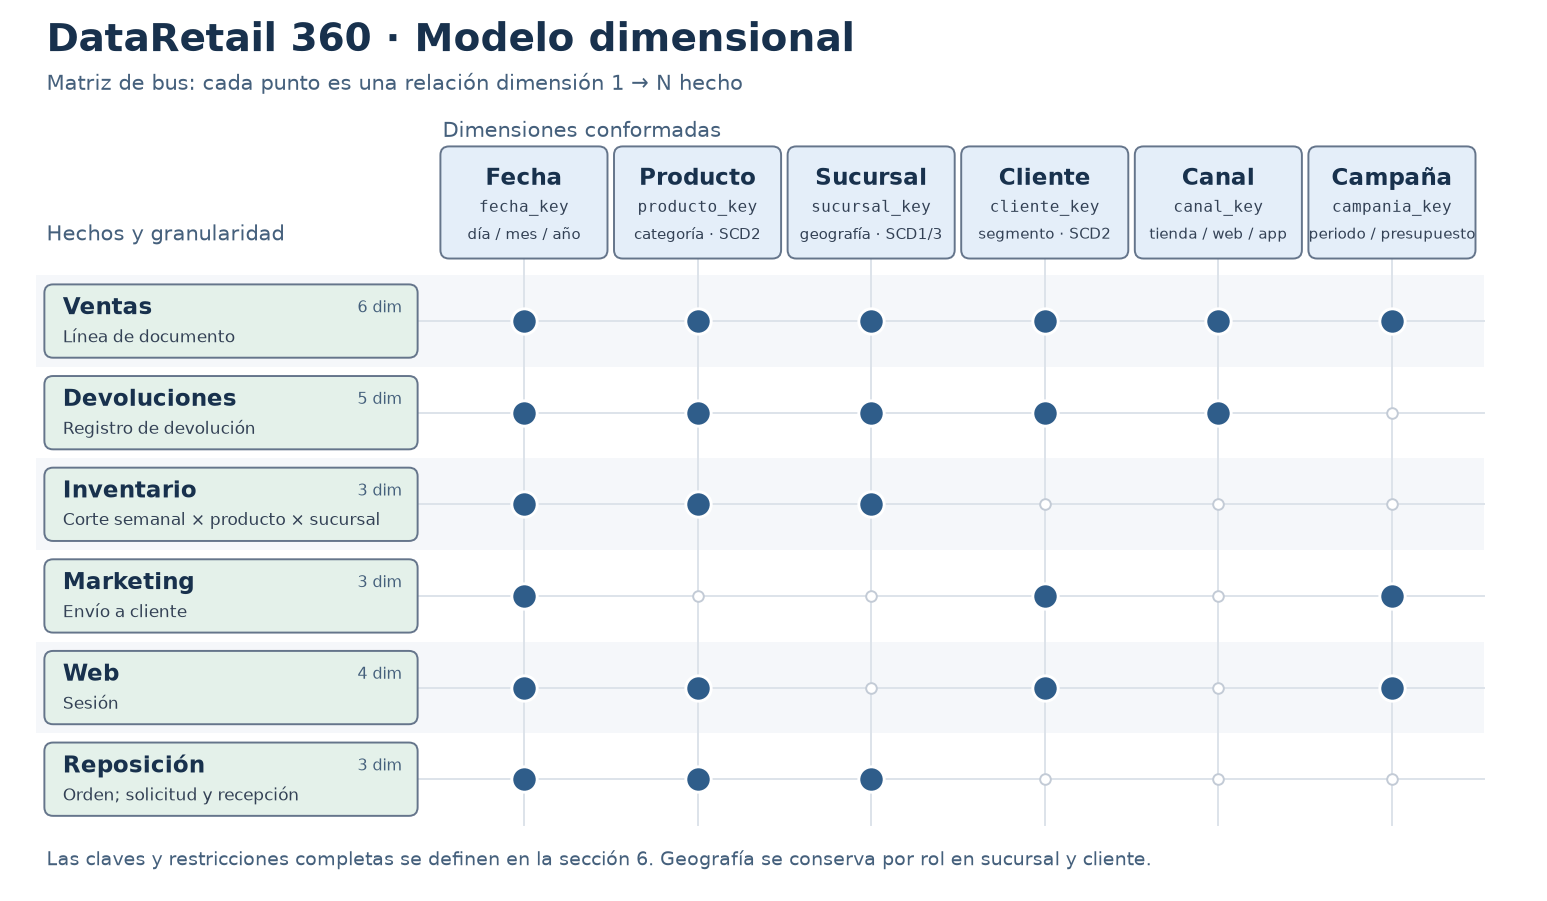

In [1]:
# Vista del modelo como matriz de bus: filas = hechos, columnas = dimensiones.
# Cada punto indica una relación dimensión 1 → N hecho.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from IPython.display import Image, display
from io import BytesIO

dims = [('Fecha',    'fecha_key',    'día / mes / año'),
        ('Producto', 'producto_key', 'categoría · SCD2'),
        ('Sucursal', 'sucursal_key', 'geografía · SCD1/3'),
        ('Cliente',  'cliente_key',  'segmento · SCD2'),
        ('Canal',    'canal_key',    'tienda / web / app'),
        ('Campaña',  'campania_key', 'periodo / presupuesto')]
facts_diagram = [('Ventas',       'Línea de documento',                  [0, 1, 2, 3, 4, 5]),
                 ('Devoluciones', 'Registro de devolución',              [0, 1, 2, 3, 4]),
                 ('Inventario',   'Corte semanal × producto × sucursal', [0, 1, 2]),
                 ('Marketing',    'Envío a cliente',                     [0, 3, 5]),
                 ('Web',          'Sesión',                              [0, 1, 3, 5]),
                 ('Reposición',   'Orden; solicitud y recepción',        [0, 1, 2])]

# Paleta
DIM_FILL, FACT_FILL, EDGE = '#e4eef9', '#e4f1ea', '#65758b'
INK, SUB, MUTED, GRID, STRIPE, DOT = '#18314d', '#334155', '#45607c', '#dde3ea', '#f5f7fa', '#2f5d8a'

# Geometría (1 unidad = 1 pulgada)
W, H = 14, 8.6
fig_h = H - 0.5
fact_x, fact_w = 0.3, 3.4
col_x = [4.7 + j * 1.6 for j in range(len(dims))]   # centros de columna
col_w = 1.5
head_y, head_h = 6.35, 1.0
row_step, row_h = 0.85, 0.64
row_y = [5.75 - i * row_step for i in range(len(facts_diagram))]   # centros de fila
x_end = col_x[-1] + col_w / 2 + 0.1

fig, ax = plt.subplots(figsize=(W, fig_h))
ax.set_xlim(0, W); ax.set_ylim(0.5, H); ax.axis('off')

# Título
ax.text(0.3, 8.35, 'DataRetail 360 · Modelo dimensional', fontsize=20, weight='bold', color=INK, va='center')
ax.text(0.3, 7.95, 'Matriz de bus: cada punto es una relación dimensión 1 → N hecho',
        fontsize=11, color=MUTED, va='center')

# Bandas alternadas por fila
for i, y in enumerate(row_y):
    if i % 2 == 0:
        ax.add_patch(Rectangle((fact_x - 0.1, y - row_step / 2), x_end - fact_x + 0.1, row_step,
                               facecolor=STRIPE, edgecolor='none', zorder=0))

# Rejilla tenue
for x in col_x:
    ax.plot([x, x], [row_y[-1] - row_step / 2, head_y], color=GRID, lw=1, zorder=1)
for y in row_y:
    ax.plot([fact_x + fact_w, x_end], [y, y], color=GRID, lw=1, zorder=1)

# Encabezados de dimensiones
ax.text(col_x[0] - col_w / 2, head_y + head_h + 0.16, 'Dimensiones conformadas',
        fontsize=11, color=MUTED, va='center')
for x, (name, key, note) in zip(col_x, dims):
    ax.add_patch(FancyBboxPatch((x - col_w / 2, head_y), col_w, head_h, boxstyle='round,pad=0.02,rounding_size=0.08',
                                facecolor=DIM_FILL, edgecolor=EDGE, zorder=2))
    ax.text(x, head_y + 0.72, name, fontsize=12, weight='bold', color=INK, ha='center', va='center', zorder=3)
    ax.text(x, head_y + 0.45, key, fontsize=8, color=SUB, ha='center', va='center', family='monospace', zorder=3)
    ax.text(x, head_y + 0.2, note, fontsize=7.6, color=SUB, ha='center', va='center', zorder=3)

# Filas de hechos
ax.text(fact_x, head_y + 0.2, 'Hechos y granularidad', fontsize=11, color=MUTED, va='center')
for y, (name, grain, links) in zip(row_y, facts_diagram):
    ax.add_patch(FancyBboxPatch((fact_x, y - row_h / 2), fact_w, row_h, boxstyle='round,pad=0.02,rounding_size=0.08',
                                facecolor=FACT_FILL, edgecolor=EDGE, zorder=2))
    ax.text(fact_x + 0.15, y + 0.12, name, fontsize=12, weight='bold', color=INK, va='center', zorder=3)
    ax.text(fact_x + 0.15, y - 0.15, grain, fontsize=8.5, color=SUB, va='center', zorder=3)
    ax.text(fact_x + fact_w - 0.12, y + 0.12, f'{len(links)} dim', fontsize=8, color=MUTED,
            ha='right', va='center', zorder=3)
    for j, x in enumerate(col_x):
        if j in links:
            ax.scatter(x, y, s=170, color=DOT, edgecolor='white', linewidth=1.5, zorder=4)
        else:
            ax.scatter(x, y, s=30, facecolor='white', edgecolor='#c3cbd6', linewidth=1, zorder=4)

# Pie
ax.text(0.3, 0.75, 'Las claves y restricciones completas se definen en la sección 6. '
        'Geografía se conserva por rol en sucursal y cliente.', fontsize=10, color=MUTED, va='center')

buffer = BytesIO(); fig.savefig(buffer, format='png', bbox_inches='tight', dpi=140)
display(Image(data=buffer.getvalue())); plt.close(fig)


## 2. Extracción heterogénea y capa Bronze

Se leen PostgreSQL, CSV y Excel mediante adaptadores explícitos, manteniendo un contrato de
columnas compartido. Los archivos originales se copian a Bronze por SHA256 sin modificar `data/raw`;
el manifiesto conserva su ruta y hoja de entrada. El hash del archivo identifica sus bytes, mientras
`hash`/`_batch` identifican la instantánea tabular decodificada. Un archivo, hoja o columna obligatoria
ausente detiene la ingestión. Solo se reintentan fallas transitorias de conexión SQL; no se sustituye
un archivo faltante por una tabla de PostgreSQL.

**Flujo:** PostgreSQL (14 conjuntos) + CSV (campañas) + Excel (reportes) → Bronze → Silver → DWH SQL Server / Gold → data marts Comercial, Operaciones, Marketing-Digital y Clientes.


In [2]:
# Contrato de columnas esperado de cada conjunto lógico, inicialmente documentado por el DDL.
# Se comprueba sobre DataFrames de SQL, CSV y Excel; no obliga a un origen SQL.
# El tipado y las reglas de negocio se aplican en Silver.
CONTRACT = {'pos_sucursales': ['id_sucursal', 'codigo_sucursal', 'nombre_sucursal', 'formato', 'direccion', 'comuna', 'region', 'zona', 'superficie_m2', 'fecha_apertura', 'fecha_cierre', 'estado', '_origen', '_fecha_carga'], 'pos_productos': ['codigo_producto', 'descripcion', 'linea_negocio', 'categoria', 'subcategoria', 'marca', 'codigo_barra', 'precio_lista', 'costo_unitario', 'estado', 'fecha_alta', 'fecha_baja', '_origen', '_fecha_carga'], 'pos_ventas_cabecera': ['id_boleta', 'tipo_documento', 'nro_documento', 'codigo_sucursal', 'nro_caja', 'fecha_hora', 'rut_cliente', 'medio_pago', 'codigo_cupon', 'monto_bruto', 'descuento_total', 'monto_neto', 'monto_iva', 'monto_total', 'estado', 'id_vendedor', '_origen', '_fecha_carga'], 'pos_ventas_detalle': ['id_boleta', 'nro_linea', 'codigo_producto', 'cantidad', 'precio_unitario', 'descuento', 'total_linea', '_origen', '_fecha_carga'], 'ecom_catalogo': ['sku_web', 'nombre_web', 'categoria_web', 'marca', 'vendedor', 'precio_web', 'codigo_pos_ref', 'ean', 'activo_web', 'fecha_publicacion', '_origen', '_fecha_carga'], 'ecom_cuentas': ['id_cuenta', 'email', 'nombre_completo', 'rut', 'telefono', 'comuna', 'fecha_creacion', 'ultimo_login', 'acepta_newsletter', '_origen', '_fecha_carga'], 'ecom_pedidos': ['id_pedido', 'id_cuenta', 'email_contacto', 'id_sesion', 'canal_venta', 'fecha_pedido_utc', 'estado_pedido', 'medio_pago', 'tipo_entrega', 'codigo_sucursal_retiro', 'comuna_despacho', 'codigo_cupon', 'subtotal', 'descuento', 'costo_despacho', 'total_pagado', 'fecha_entrega', '_origen', '_fecha_carga'], 'ecom_pedidos_detalle': ['id_pedido', 'nro_linea', 'sku_web', 'cantidad', 'precio_unitario', 'descuento', 'total_linea', '_origen', '_fecha_carga'], 'web_sesiones': ['id_sesion', 'id_cuenta', 'fecha_inicio_utc', 'dispositivo', 'fuente_trafico', 'utm_campaign', 'paginas_vistas', 'duracion_seg', 'sku_principal_visto', 'agrego_carrito', 'inicio_checkout', 'compro', '_origen', '_fecha_carga'], 'crm_clientes': ['id_cliente', 'rut', 'nombres', 'apellido_paterno', 'apellido_materno', 'email', 'telefono', 'fecha_nacimiento', 'genero', 'comuna', 'region', 'segmento_crm', 'canal_registro', 'fecha_registro', 'acepta_marketing', 'estado', '_origen', '_fecha_carga'], 'mkt_campanias': ['id_campania', 'codigo_campania', 'nombre_campania', 'tipo_campania', 'canal_objetivo', 'categoria_foco', 'segmento_objetivo', 'descuento_pct', 'fecha_inicio', 'fecha_fin', 'presupuesto_clp', 'responsable', '_origen', '_fecha_carga'], 'mkt_envios_campania': ['id_envio', 'id_campania', 'id_cliente', 'canal_envio', 'fecha_envio', 'entregado', 'abierto', 'fecha_apertura', 'click', 'convertido', 'monto_atribuido', '_origen', '_fecha_carga'], 'inv_stock_semanal': ['fecha_corte', 'codigo_sucursal', 'codigo_producto', 'stock_sistema', 'stock_fisico', 'stock_minimo', 'punto_reposicion', 'unidades_en_transito', 'fecha_ultimo_conteo', '_origen', '_fecha_carga'], 'inv_ordenes_reposicion': ['id_orden', 'codigo_sucursal', 'codigo_producto', 'fecha_solicitud', 'fecha_recepcion', 'cantidad_solicitada', 'cantidad_recibida', 'estado', '_origen', '_fecha_carga'], 'devoluciones': ['id_devolucion', 'canal_origen', 'id_documento_origen', 'codigo_producto', 'fecha_devolucion', 'cantidad', 'monto_devuelto', 'motivo', 'codigo_sucursal_recepcion', 'estado', '_origen', '_fecha_carga'], 'legacy_reporte_ventas_xlsx': ['archivo_origen', 'hoja', 'fila_excel', 'fecha', 'sucursal', 'linea', 'unidades', 'monto_venta', 'estado', 'responsable', 'observacion', '_origen', '_fecha_carga']}

In [3]:
# Configuración: credenciales fuera del notebook, rutas relativas y versiones verificables.
from pathlib import Path
from datetime import datetime, timezone
from io import BytesIO
import os, json, hashlib, logging, uuid, time, re, unicodedata, subprocess
from decimal import Decimal, ROUND_HALF_UP
from contextlib import contextmanager
import pandas as pd
import numpy as np
import sqlalchemy as sa
from sqlalchemy import text
import pyarrow.parquet as pq
from dotenv import load_dotenv
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'EP3_DataRetail360.ipynb').exists():
    raise RuntimeError('Ejecutar desde la carpeta DataRetail360_EP3.')
load_dotenv(ROOT / '.env', encoding='utf-8-sig')
if not os.getenv('PGPASSWORD'):
    from getpass import getpass
    os.environ['PGPASSWORD'] = getpass('Contraseña PostgreSQL (no se muestra): ')
DATA = ROOT / 'data'
for folder in ['bronze', 'silver', 'gold', 'control', 'rechazos']:
    (DATA / folder).mkdir(parents=True, exist_ok=True)
(ROOT / 'logs').mkdir(exist_ok=True)
RUN_ID = uuid.uuid4().hex
LOG = logging.getLogger('dr360')
LOG.setLevel(logging.INFO)
for handler in LOG.handlers[:]:
    handler.close(); LOG.removeHandler(handler)
handler = logging.FileHandler(ROOT / 'logs' / f'{RUN_ID}.log', encoding='utf-8')
handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
LOG.addHandler(handler)
LOG.info('Inicio run=%s', RUN_ID)

PG = sa.create_engine(sa.URL.create('postgresql+psycopg',
    username=os.getenv('PGUSER','postgres'), password=os.environ['PGPASSWORD'],
    host=os.getenv('PGHOST','localhost'), port=int(os.getenv('PGPORT','5432')),
    database=os.getenv('PGDATABASE','idy1102_ep2')), hide_parameters=True,
    connect_args={'connect_timeout':10}, pool_pre_ping=True)
DW = sa.create_engine(sa.URL.create('mssql+pyodbc',
    host=os.getenv('MSSQL_SERVER','localhost'), database=os.getenv('MSSQL_DATABASE','DataRetail360_DW'),
    query={'driver':'ODBC Driver 18 for SQL Server','Trusted_Connection':'yes',
           'Encrypt':'yes','TrustServerCertificate':'yes'}),
    fast_executemany=True, hide_parameters=True, pool_pre_ping=True)
# TrustServerCertificate es una decisión del laboratorio local, no de producción.
with DW.connect() as conn:
    assert conn.scalar(text('SELECT DB_NAME()')) == 'DataRetail360_DW'
print('Conexiones configuradas; SQL Server disponible. Run:', RUN_ID)

# Claves naturales de los conjuntos lógicos, independientemente del formato físico.
KEYS = {
 'pos_sucursales':['codigo_sucursal'], 'pos_productos':['codigo_producto'],
 'pos_ventas_cabecera':['id_boleta'], 'pos_ventas_detalle':['id_boleta','nro_linea'],
 'ecom_catalogo':['sku_web'], 'ecom_cuentas':['id_cuenta'],
 'ecom_pedidos':['id_pedido'], 'ecom_pedidos_detalle':['id_pedido','nro_linea'],
 'web_sesiones':['id_sesion'], 'crm_clientes':['id_cliente'],
 'mkt_campanias':['id_campania'], 'mkt_envios_campania':['id_envio'],
 'inv_stock_semanal':['fecha_corte','codigo_sucursal','codigo_producto'],
 'inv_ordenes_reposicion':['id_orden'], 'devoluciones':['id_devolucion'],
 'legacy_reporte_ventas_xlsx':['archivo_origen','hoja','fila_excel']}

# Registro de adaptadores. Una fuente tiene un único lector; no hay fallback a SQL.
FILE_SOURCES = {
 'mkt_campanias': {'tipo_fuente':'CSV', 'ubicacion':'data/raw/marketing/campanias.csv',
                  'hoja_entrada':'', 'encoding':'utf-8-sig', 'sep':','},
 'legacy_reporte_ventas_xlsx': {'tipo_fuente':'EXCEL',
                  'ubicacion':'data/raw/legacy/reportes_ventas.xlsx',
                  'hoja_entrada':'legacy_reporte_ventas_xlsx_2026'}}
SOURCES = {name: FILE_SOURCES.get(name, {'tipo_fuente':'POSTGRESQL',
           'ubicacion':'dr360_raw.'+name, 'hoja_entrada':''}) for name in KEYS}

def validate_columns(name, frame):
    """Contrato de columnas compartido por SQL, CSV y Excel; la calidad se valida en Silver."""
    if frame.columns.duplicated().any():
        raise ValueError(f'Columnas duplicadas: {name}')
    missing = set(CONTRACT[name]) - set(frame.columns)
    if missing:
        raise ValueError(f'Contrato roto: {name}; faltan columnas {sorted(missing)}')

def read_file_source(name, spec):
    """Lee bytes congelados y conserva el archivo original; no modifica data/raw."""
    source_path = ROOT / spec['ubicacion']
    if not source_path.is_file():
        raise FileNotFoundError(f'Fuente requerida ausente: {spec["ubicacion"]}')
    content = source_path.read_bytes()
    file_sha = hashlib.sha256(content).hexdigest()
    original = DATA/'bronze'/name/'originales'/f'{file_sha}{source_path.suffix.lower()}'
    original.parent.mkdir(parents=True, exist_ok=True)
    if original.exists():
        if hashlib.sha256(original.read_bytes()).hexdigest() != file_sha:
            raise ValueError(f'Copia Bronze alterada: {name}')
    else:
        temp = original.with_name(original.name+'.'+RUN_ID+'.tmp')
        temp.write_bytes(content); temp.replace(original)
    if spec['tipo_fuente'] == 'CSV':
        frame = pd.read_csv(BytesIO(content), sep=spec['sep'], encoding=spec['encoding'],
                            dtype='string', keep_default_na=False, on_bad_lines='error')
    elif spec['tipo_fuente'] == 'EXCEL':
        with pd.ExcelFile(BytesIO(content), engine='openpyxl') as book:
            if spec['hoja_entrada'] not in book.sheet_names:
                raise ValueError(f'Hoja requerida ausente en {name}: {spec["hoja_entrada"]}')
            frame = pd.read_excel(book, sheet_name=spec['hoja_entrada'],
                                  dtype='string', keep_default_na=False)
    else:
        raise ValueError(f'Adaptador de archivo desconocido: {name}')
    # Se conserva el texto leído; las conversiones de negocio se realizan en Silver.
    # El XLSX original conserva además los tipos y formatos nativos de sus celdas.
    validate_columns(name, frame)
    return frame, {'sha256_archivo':file_sha, 'bytes_archivo':len(content),
                   'original_bronze':str(original.relative_to(ROOT))}

def extract_snapshot():
    """Congela archivos y obtiene una instantánea consistente de las fuentes SQL."""
    # Un error de archivo, hoja o contrato detiene la ejecución antes de consultar datos SQL.
    file_inputs = {name:read_file_source(name, spec) for name,spec in FILE_SOURCES.items()}
    sql_names = [name for name,spec in SOURCES.items() if spec['tipo_fuente']=='POSTGRESQL']
    schema_query = text('''SELECT table_name,column_name,data_type
        FROM information_schema.columns WHERE table_schema='dr360_raw'
        AND table_name IN :names ORDER BY table_name,ordinal_position''').bindparams(
            sa.bindparam('names', expanding=True))
    for attempt in range(3):
        try:
            raw, inventory = {}, []
            with PG.connect().execution_options(isolation_level='REPEATABLE READ') as conn:
                with conn.begin():
                    conn.execute(text('SET TRANSACTION READ ONLY'))
                    schema = pd.read_sql(schema_query, conn, params={'names':sql_names})
                    schema['tipo_fuente']='POSTGRESQL'
                    for name,key in KEYS.items():
                        spec = SOURCES[name]
                        if spec['tipo_fuente']=='POSTGRESQL':
                            cols = schema.loc[schema.table_name.eq(name),'column_name'].tolist()
                            if not set(CONTRACT[name]).issubset(cols):
                                raise ValueError(f'Contrato roto en SQL: {name}')
                            # Nombres de tabla y claves de orden proceden de listas fijas.
                            frame = pd.read_sql(text(f'SELECT * FROM dr360_raw.{name} ORDER BY '+','.join(key)), conn)
                            file_meta={'sha256_archivo':'','bytes_archivo':0,'original_bronze':''}
                        else:
                            frame,file_meta = file_inputs[name]
                            frame=frame.copy()
                            schema = pd.concat([schema, pd.DataFrame({
                                'table_name':name, 'column_name':frame.columns,
                                'data_type':[str(t) for t in frame.dtypes],
                                'tipo_fuente':spec['tipo_fuente']})],ignore_index=True)
                        validate_columns(name, frame)
                        digest = hashlib.sha256(pd.util.hash_pandas_object(frame,index=False).values.tobytes()).hexdigest()
                        path = DATA/'bronze'/name/f'{digest}.parquet'
                        path.parent.mkdir(exist_ok=True)
                        if not path.exists():
                            temp = path.with_name(path.name+'.'+RUN_ID+'.tmp')
                            frame.to_parquet(temp,index=False); temp.replace(path)
                        source_columns=len(frame.columns)
                        # En archivos, 0 corresponde a la primera fila de datos, sin encabezado.
                        frame['_src_row']=np.arange(len(frame),dtype='int64')
                        frame['_batch']=digest
                        raw[name]=frame
                        inventory.append({'tabla':name,'tipo_fuente':spec['tipo_fuente'],
                            'ubicacion':spec['ubicacion'],'hoja_entrada':spec['hoja_entrada'],
                            'filas':len(frame),'columnas':source_columns,'hash':digest,
                            'archivo':str(path.relative_to(ROOT)), **file_meta})
                        LOG.info('extract fuente=%s tipo=%s filas=%d',name,spec['tipo_fuente'],len(frame))
                    controls={n:pd.read_sql(text(f'SELECT * FROM dr360_control.{n}'),conn) for n in
                              ['config_generacion','definiciones_kpi_por_area','problemas_calidad_inyectados']}
            return raw,pd.DataFrame(inventory),schema,controls
        except sa.exc.OperationalError:
            LOG.warning('Falla transitoria de extracción SQL intento=%d',attempt+1)
            if attempt==2: raise
            time.sleep(2**attempt)
        except Exception as exc:
            LOG.error('Extracción detenida tipo=%s',type(exc).__name__)
            raise

raw, inventory, source_schema, controls = extract_snapshot()
manifest={'run_id':RUN_ID, 'extracted_at_utc':datetime.now(timezone.utc).isoformat(),
          'consistencia':'Instantánea transaccional SQL y archivos congelados por SHA256; no hay transacción global entre fuentes.',
          'sources':inventory.to_dict('records')}
(DATA/'control'/f'{RUN_ID}.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
source_schema.to_parquet(DATA/'control'/'source_schema.parquet',index=False)
display(inventory[['tabla','tipo_fuente','filas','columnas','ubicacion']])
print('Filas extraídas:',int(inventory.filas.sum()))

Conexiones configuradas; SQL Server disponible. Run: 8e27a274ca3041f6ae877cc341972dc7


,tabla,tipo_fuente,filas,columnas,ubicacion
0,pos_sucursales,POSTGRESQL,46,14,dr360_raw.pos_sucursales
1,pos_productos,POSTGRESQL,2500,14,dr360_raw.pos_productos
2,pos_ventas_cabecera,POSTGRESQL,278593,18,dr360_raw.pos_ventas_cabecera
3,pos_ventas_detalle,POSTGRESQL,555230,9,dr360_raw.pos_ventas_detalle
4,ecom_catalogo,POSTGRESQL,2190,12,dr360_raw.ecom_catalogo
5,ecom_cuentas,POSTGRESQL,39184,11,dr360_raw.ecom_cuentas
6,ecom_pedidos,POSTGRESQL,57015,19,dr360_raw.ecom_pedidos
7,ecom_pedidos_detalle,POSTGRESQL,95197,9,dr360_raw.ecom_pedidos_detalle
8,web_sesiones,POSTGRESQL,500003,14,dr360_raw.web_sesiones
9,crm_clientes,POSTGRESQL,63586,18,dr360_raw.crm_clientes


Filas extraídas: 3438326


### Evidencia de los lectores de entrada
El inventario identifica el mecanismo físico de cada fuente. Las pruebas siguientes verifican
los archivos originales, sus copias Bronze y el rechazo de entradas ausentes o con esquema roto.
La columna `hoja_entrada` identifica la hoja del XLSX exportado; la columna de negocio `hoja`
permanece intacta y describe las hojas de los reportes originales simulados.

In [4]:
# Evidencia de los tres adaptadores y pruebas de fallas sin alterar archivos de entrada.
ingestion_checks=[]
assert inventory.groupby('tipo_fuente').size().to_dict()=={'CSV':1,'EXCEL':1,'POSTGRESQL':14}
assert set(inventory.tabla)==set(CONTRACT)
ingestion_checks.append({'prueba':'Tres adaptadores reales: 14 fuentes SQL, un CSV y un Excel','resultado':'OK'})
for name,spec in FILE_SOURCES.items():
    row=inventory.set_index('tabla').loc[name]
    assert row.tipo_fuente==spec['tipo_fuente']
    assert row.ubicacion==spec['ubicacion']
    assert hashlib.sha256((ROOT/row.original_bronze).read_bytes()).hexdigest()==row.sha256_archivo
    assert hashlib.sha256((ROOT/spec['ubicacion']).read_bytes()).hexdigest()==row.sha256_archivo
    assert len(raw[name])==int(row.filas)
ingestion_checks.append({'prueba':'Archivos originales intactos y copias Bronze con SHA256 verificable','resultado':'OK'})
try:
    read_file_source('mkt_campanias',{**FILE_SOURCES['mkt_campanias'],
        'ubicacion':f'data/raw/marketing/ausente_{uuid.uuid4().hex}.csv'})
except FileNotFoundError:
    ingestion_checks.append({'prueba':'Archivo ausente detiene la ingestión sin fallback a PostgreSQL','resultado':'OK'})
else:
    raise AssertionError('Se aceptó un archivo ausente')
try:
    validate_columns('mkt_campanias',raw['mkt_campanias'].drop(columns='id_campania'))
except ValueError:
    ingestion_checks.append({'prueba':'Contrato detecta una columna obligatoria ausente en CSV','resultado':'OK'})
else:
    raise AssertionError('Se aceptó un CSV sin clave requerida')
display(pd.DataFrame(ingestion_checks))
display(inventory.loc[inventory.tipo_fuente.ne('POSTGRESQL'),
                      ['tabla','tipo_fuente','hoja_entrada','sha256_archivo','original_bronze']])

,prueba,resultado
0,"Tres adaptadores reales: 14 fuentes SQL, un CS...",OK
1,Archivos originales intactos y copias Bronze c...,OK
2,Archivo ausente detiene la ingestión sin fallb...,OK
3,Contrato detecta una columna obligatoria ausen...,OK


,tabla,tipo_fuente,hoja_entrada,sha256_archivo,original_bronze
10,mkt_campanias,CSV,,6a03359ee35691aa80e17d92d650947f5ae62075d2a7a9...,data\bronze\mkt_campanias\originales\6a03359ee...
15,legacy_reporte_ventas_xlsx,EXCEL,legacy_reporte_ventas_xlsx_2026,7bcf319aa53c980c7bb43aea94724bc62933ae5f0ef17f...,data\bronze\legacy_reporte_ventas_xlsx\origina...


## 3. Calidad e integración Silver

Cada regla produce evidencia. Se separan duplicados, conflictos y rechazos; no se pierde una fila sin contabilizarla. La identidad y la homologación conservan incertidumbre cuando no hay evidencia suficiente.

In [5]:
# Funciones de normalización: reglas explícitas y reutilizables, no correcciones silenciosas.
def norm(value):
    if pd.isna(value): return ''
    return ''.join(c for c in unicodedata.normalize('NFKD',str(value).strip().upper()) if not unicodedata.combining(c))

def norm_series(s):
    lookup={v:norm(v) for v in s.dropna().unique()}
    return s.map(lookup).fillna('')

def code_series(s):
    return norm_series(s).str.replace(r'[^A-Z0-9]','',regex=True)

def rut_valid(value):
    x=re.sub(r'[^0-9K]','',norm(value))
    if len(x)<2: return None
    digits,dv=x[:-1],x[-1]
    if not digits.isdigit() or int(digits)==0: return None
    total=sum(int(n)*(2+i%6) for i,n in enumerate(reversed(digits)))
    check=11-total%11
    return digits+'-'+dv if dv==('0' if check==11 else 'K' if check==10 else str(check)) else None

def rut_series(s):
    return s.map({v:rut_valid(v) for v in s.dropna().unique()})

def region_series(s):
    r=norm_series(s)
    r=r.str.replace(r'^REGION (DE |DEL |DE LA |DE LOS )?','',regex=True)
    return r.replace({'RM':'METROPOLITANA','METROPOLITANA DE SANTIAGO':'METROPOLITANA','BIO BIO':'BIOBIO','BIO-BIO':'BIOBIO','DEL BIOBIO':'BIOBIO'})

quality=[]
reject_parts=[]
def audit_filter(df, table, rules, keys=None):
    """Una fila rechazada puede tener varios motivos; se cuenta una sola vez."""
    df=df.copy()
    reasons=pd.Series('',index=df.index,dtype='str')
    for reason,mask in rules.items():
        mask=pd.Series(mask,index=df.index).fillna(True)
        reasons.loc[mask]=reasons.loc[mask]+reason+';'
    bad=reasons.ne('')
    rejected=df.loc[bad].copy(); rejected['_motivo']=reasons[bad]
    remaining=df.loc[~bad].copy()
    duplicates=0
    if keys:
        payload=[c for c in remaining if c not in ['_src_row','_batch','_fecha_carga']]
        exact=remaining.duplicated(payload)
        dup=remaining.loc[exact].copy(); dup['_motivo']='duplicado_exacto'
        duplicates=len(dup)
        remaining=remaining.loc[~exact].copy()
        conflict=remaining.duplicated(keys,keep=False)
        conflicting=remaining.loc[conflict].copy(); conflicting['_motivo']='clave_conflictiva'
        remaining=remaining.loc[~conflict].copy()
        rejected=pd.concat([rejected,conflicting],ignore_index=True)
        if len(dup):
            dup.to_parquet(DATA/'rechazos'/f'{table}_duplicados.parquet',index=False)
    if len(rejected):
        rejected.to_parquet(DATA/'rechazos'/f'{table}.parquet',index=False)
        reject_parts.append(rejected.assign(_tabla=table)[['_tabla','_src_row','_batch','_motivo']])
    quality.append({'etapa':table,'leidas':len(df),'aceptadas':len(remaining),'rechazadas':len(rejected),'duplicadas':duplicates})
    assert len(df)==len(remaining)+len(rejected)+duplicates
    LOG.info('quality etapa=%s leidas=%d aceptadas=%d rechazadas=%d duplicadas=%d',table,len(df),len(remaining),len(rejected),duplicates)
    return remaining.reset_index(drop=True)

silver={}
for name,frame in raw.items():
    df=frame.copy()
    if name == 'mkt_campanias':
        # CSV llega como texto: códigos conservan su representación y medidas se tipan aquí.
        campaign_id=pd.to_numeric(df.id_campania,errors='coerce')
        df['id_campania']=campaign_id.where(campaign_id.gt(0) & campaign_id.mod(1).eq(0)).astype('Int64')
        df['descuento_pct']=pd.to_numeric(df.descuento_pct,errors='coerce')
        df['presupuesto_clp']=pd.to_numeric(df.presupuesto_clp,errors='coerce').astype('float64')
    for col in ['codigo_producto','codigo_sucursal','codigo_sucursal_retiro','codigo_sucursal_recepcion','codigo_pos_ref','sku_web']:
        if col in df: df[col]=code_series(df[col])
    for col in ['estado','estado_pedido','canal_origen','canal_venta','tipo_entrega','linea_negocio','categoria','subcategoria']:
        if col in df: df[col]=norm_series(df[col])
    if 'region' in df: df['region']=region_series(df.region)
    if 'comuna' in df: df['comuna']=norm_series(df.comuna)
    for col in ['codigo_cupon','codigo_campania','utm_campaign']:
        if col in df: df[col]=code_series(df[col])
    required=KEYS[name]
    invalid_key=df[required].isna().any(axis=1)
    for col in required:
        if pd.api.types.is_string_dtype(df[col]): invalid_key |= df[col].eq('')
    silver[name]=audit_filter(df,name,{'clave_nula':invalid_key},required)

In [6]:
# Maestro integrado de productos: EAN único prevalece sobre una referencia POS contradictoria.
products=silver['pos_productos'].copy()
products['ean']=products.codigo_barra.astype('string').str.strip()
ean_unique=products.loc[products.ean.notna() & ~products.ean.duplicated(keep=False)].set_index('ean').codigo_producto
catalog=silver['ecom_catalogo'].copy()
catalog['ean']=catalog.ean.astype('string').str.strip()
catalog['por_ean']=catalog.ean.map(ean_unique)
valid_ref=catalog.codigo_pos_ref.isin(products.codigo_producto)
catalog['referencia_contradictoria']=catalog.por_ean.notna() & valid_ref & catalog.por_ean.ne(catalog.codigo_pos_ref)
catalog['producto_nk']=catalog.por_ean.fillna(catalog.codigo_pos_ref.where(valid_ref))
catalog['metodo']=np.select([catalog.por_ean.notna(),valid_ref],['EAN_UNICO','REFERENCIA_POS'],default='WEB_INDEPENDIENTE')
catalog['producto_nk']=catalog.producto_nk.fillna('WEB:'+catalog.sku_web)
web_product_map=catalog.set_index('sku_web').producto_nk
products['producto_nk']=products.codigo_producto
products['producto']=products.descripcion
products['linea']=products.linea_negocio
products['subcategoria']=products.subcategoria.replace('','SIN_INFORMAR')
products['marca']=norm_series(products.marca)
extras=catalog.loc[catalog.metodo.eq('WEB_INDEPENDIENTE')].copy()
extras=extras.assign(producto=extras.nombre_web,linea='WEB_SIN_HOMOLOGAR',categoria=norm_series(extras.categoria_web),subcategoria='SIN_INFORMAR',marca=norm_series(extras.marca))
product_master=pd.concat([products[['producto_nk','producto','linea','categoria','subcategoria','marca']],extras[['producto_nk','producto','linea','categoria','subcategoria','marca']]],ignore_index=True)
assert not product_master.producto_nk.duplicated().any()
catalog[['sku_web','producto_nk','metodo','referencia_contradictoria']].to_parquet(DATA/'silver'/'mapa_productos.parquet',index=False)
display(catalog.groupby(['metodo','referencia_contradictoria']).size().rename('productos').reset_index())

# Identidades: RUT con DV válido; correo normalizado solo si no enlaza personas distintas.
crm=silver['crm_clientes'].copy(); accounts=silver['ecom_cuentas'].copy()
for df in [crm,accounts]:
    df['rut_ok']=rut_series(df.rut)
    df['email_ok']=df.email.astype('string').str.strip().str.lower()
    df['email_ok']=df.email_ok.where(df.email_ok.str.fullmatch(r'[^\s@]+@[^\s@]+\.[^\s@]+',na=False))
identities=pd.concat([crm[['rut_ok','email_ok']],accounts[['rut_ok','email_ok']]],ignore_index=True)
links=identities.dropna().drop_duplicates()
email_counts=links.groupby('email_ok').rut_ok.nunique()
email_rut=links.loc[links.email_ok.isin(email_counts[email_counts.eq(1)].index)].drop_duplicates('email_ok').set_index('email_ok').rut_ok
ambiguous_emails=set(email_counts[email_counts.gt(1)].index)
def identity(df,prefix,idcol):
    r=df.rut_ok.fillna(df.email_ok.map(email_rut))
    e=df.email_ok.where(~df.email_ok.isin(ambiguous_emails))
    k=('R:'+r).fillna('E:'+e).fillna(prefix+df[idcol].astype(str))
    # Seudonimización determinista: no equivale a anonimización irreversible.
    return k.map(lambda x:hashlib.sha256(x.encode()).hexdigest())
crm['cliente_nk']=identity(crm,'CRM:','id_cliente')
accounts['cliente_nk']=identity(accounts,'WEB:','id_cuenta')
crm_map=crm.set_index('id_cliente').cliente_nk
account_map=accounts.set_index('id_cuenta').cliente_nk
rut_map=pd.concat([crm[['rut_ok','cliente_nk']],accounts[['rut_ok','cliente_nk']]]).dropna().drop_duplicates('rut_ok').set_index('rut_ok').cliente_nk
crm['segmento']=norm_series(crm.segmento_crm)
crm['prioridad']=0
accounts=accounts.assign(region='SIN_INFORMAR',segmento='SOLO_WEB',prioridad=1,acepta_marketing=accounts.acepta_newsletter)
client_master=(pd.concat([crm,accounts],ignore_index=True).sort_values(['prioridad','cliente_nk']).drop_duplicates('cliente_nk'))
client_master=client_master[['cliente_nk','comuna','region','segmento','acepta_marketing']].fillna({'comuna':'SIN_INFORMAR','region':'SIN_INFORMAR','segmento':'SIN_INFORMAR','acepta_marketing':False})
assert not client_master.cliente_nk.duplicated().any()
print('Identidades consolidadas:',len(client_master),'Correos ambiguos:',len(ambiguous_emails))

,metodo,referencia_contradictoria,productos
0,EAN_UNICO,False,1644
1,EAN_UNICO,True,90
2,REFERENCIA_POS,False,213
3,WEB_INDEPENDIENTE,False,243


Identidades consolidadas: 74959 Correos ambiguos: 3861


In [7]:
# Fechas y reglas específicas: las fechas UTC digitales se convierten antes del corte diario.
pos=silver['pos_ventas_cabecera'].copy()
pos['estado']=pos.estado.replace({'NULA':'ANULADA','ANUL':'ANULADA'})
pos['fecha_local']=pd.to_datetime(pos.fecha_hora,errors='coerce')
pos=audit_filter(pos,'pos_cabecera_reglas',{
    'fecha_invalida':pos.fecha_local.isna(),
    'estado_desconocido':~pos.estado.isin(['EMITIDA','ANULADA']),
    'montos_invalidos':pos[['monto_neto','monto_iva','monto_total']].isna().any(axis=1) | pos[['monto_neto','monto_iva','monto_total']].lt(0).any(axis=1),
    'cuadratura_tributaria':pos.monto_neto.add(pos.monto_iva).ne(pos.monto_total)})
orders=silver['ecom_pedidos'].copy()
orders['estado_pedido']=orders.estado_pedido.replace({'DEVOLUCION':'DEVUELTO'})
orders['fecha_local']=pd.to_datetime(orders.fecha_pedido_utc,utc=True,errors='coerce').dt.tz_convert('America/Santiago').dt.tz_localize(None)
orders=audit_filter(orders,'ecom_cabecera_reglas',{
    'fecha_invalida':orders.fecha_local.isna(),
    'estado_desconocido':~orders.estado_pedido.isin(['ENTREGADO','DEVUELTO','CANCELADO','PAGO_RECHAZADO','EN_PREPARACION','EN_TRANSITO']),
    'montos_invalidos':orders[['subtotal','descuento','costo_despacho','total_pagado']].isna().any(axis=1) | orders[['subtotal','descuento','costo_despacho','total_pagado']].lt(0).any(axis=1) | orders.descuento.gt(orders.subtotal),
    'cuadratura_pedido':orders.subtotal.sub(orders.descuento).add(orders.costo_despacho).ne(orders.total_pagado)})
print('Documentos por estado (no todos son ventas reconocidas):')
display(pos.groupby('estado').size().rename('documentos').reset_index())
display(orders.groupby('estado_pedido').size().rename('documentos').reset_index())

campaigns=silver['mkt_campanias'].copy()
campaigns['fecha_inicio']=pd.to_datetime(campaigns.fecha_inicio,errors='coerce')
campaigns['fecha_fin']=pd.to_datetime(campaigns.fecha_fin,errors='coerce')
campaigns['calidad_campania']=np.where(
    campaigns.fecha_inicio.isna() | campaigns.fecha_fin.isna() |
    campaigns.fecha_fin.lt(campaigns.fecha_inicio) | campaigns.presupuesto_clp.isna() |
    campaigns.presupuesto_clp.le(0) | campaigns.descuento_pct.isna() |
    ~campaigns.descuento_pct.between(0,100), 'REVISAR','OK')
# Se conserva la campaña para integridad; las tasas de retorno no usan presupuestos inválidos.
campaign_map=campaigns.set_index('codigo_campania').id_campania

# Legacy: no se adivinan fechas ambiguas DD/MM vs MM/DD.
def legacy_date(value):
    if pd.isna(value): return pd.NaT
    # El XLSX contiene fechas nativas, texto y seriales de Excel. El lector textual
    # representa las fechas nativas como ISO con hora; ese formato no es ambiguo.
    if isinstance(value,(datetime,pd.Timestamp,np.datetime64)):
        return pd.Timestamp(value).normalize()
    s=str(value).strip().lower()
    if re.fullmatch(r'\d{4}-\d{2}-\d{2}(?:[ t]\d{2}:\d{2}:\d{2}(?:\.\d+)?)?',s):
        parsed=pd.to_datetime(s,errors='coerce')
        return parsed.normalize() if pd.notna(parsed) else pd.NaT
    if re.fullmatch(r'\d{5}(?:\.0+)?',s):
        return pd.Timestamp('1899-12-30')+pd.Timedelta(days=int(float(s)))
    months={'ene':'jan','abr':'apr','ago':'aug','dic':'dec'}
    for es,en in months.items(): s=s.replace(es,en)
    if re.fullmatch(r'\d{1,2}/\d{1,2}/\d{4}',s):
        a,b,_=map(int,s.split('/'))
        if a<=12 and b<=12 and a!=b: return pd.NaT
        return pd.to_datetime(s,format='%d/%m/%Y' if a>12 or a==b else '%m/%d/%Y',errors='coerce')
    for fmt in ['%Y-%m-%d','%d-%m-%y','%d-%b-%Y']:
        try: return pd.Timestamp(datetime.strptime(s,fmt))
        except ValueError: pass
    return pd.NaT
legacy=silver['legacy_reporte_ventas_xlsx'].copy()
legacy['fecha_limpia']=legacy.fecha.map({x:legacy_date(x) for x in legacy.fecha.unique()})
amount=legacy.monto_venta.astype('string').str.replace(r'[$\s.]','',regex=True).str.replace(',','.',regex=False)
legacy['monto_limpio']=pd.to_numeric(amount,errors='coerce')
legacy=audit_filter(legacy,'legacy_formatos',{'fecha_ambigua_o_invalida':legacy.fecha_limpia.isna(),'monto_invalido':legacy.monto_limpio.isna() | legacy.monto_limpio.lt(0)})
# La deduplicación entre archivos usa dimensiones y medidas, manteniendo el reporte separado.
legacy['sucursal_norm']=norm_series(legacy.sucursal); legacy['linea_norm']=norm_series(legacy.linea)
legacy=audit_filter(legacy,'legacy_grano',{},['fecha_limpia','sucursal_norm','linea_norm'])
legacy.to_parquet(DATA/'silver'/'legacy_conciliacion.parquet',index=False)

for name,frame in silver.items():
    frame.to_parquet(DATA/'silver'/f'{name}.parquet',index=False)
pd.DataFrame(quality).to_parquet(DATA/'control'/'calidad.parquet',index=False)
display(pd.DataFrame(quality))

Documentos por estado (no todos son ventas reconocidas):


,estado,documentos
0,ANULADA,6984
1,EMITIDA,270785


,estado_pedido,documentos
0,CANCELADO,2559
1,DEVUELTO,1655
2,ENTREGADO,50920
3,EN_PREPARACION,223
4,EN_TRANSITO,217
5,PAGO_RECHAZADO,1441


,etapa,leidas,aceptadas,rechazadas,duplicadas
0,pos_sucursales,46,46,0,0
1,pos_productos,2500,2500,0,0
2,pos_ventas_cabecera,278593,277769,0,824
3,pos_ventas_detalle,555230,555230,0,0
4,ecom_catalogo,2190,2190,0,0
5,ecom_cuentas,39184,39184,0,0
6,ecom_pedidos,57015,57015,0,0
7,ecom_pedidos_detalle,95197,95197,0,0
8,web_sesiones,500003,489279,10724,0
9,crm_clientes,63586,63586,0,0


## 4. Dimensiones e historia temporal

Las claves sustitutas pertenecen al DWH. Los cambios tipo 2 cierran intervalos e insertan versiones; tipo 1 corrige y tipo 3 conserva el valor anterior. Las pruebas controladas están separadas de las dimensiones reales.

In [8]:
# Política temporal: la primera observación es una línea base, no historia reconstruida.
# Desde futuras ejecuciones, cambios de atributos generan intervalos [desde, hasta).
OBSERVED_AT=pd.Timestamp.now(tz='America/Santiago').tz_localize(None).floor('s')
BASELINE=pd.Timestamp('1900-01-01')
END=pd.Timestamp('2100-01-01')

def read_previous(name):
    if sa.inspect(DW).has_table(name,schema='dw'):
        with DW.connect() as conn: return pd.read_sql(text(f'SELECT * FROM dw.{name}'),conn)
    return pd.DataFrame()

def scd_merge(incoming, previous, nk, sk, type2=(), type1=(), type3=(), now=OBSERVED_AT):
    """Conserva claves y tipos 1/2/3. No crea versiones si los atributos no cambian."""
    inc=incoming.copy().reset_index(drop=True)
    if inc[nk].duplicated().any() or inc[nk].isna().any(): raise ValueError('Clave natural no única')
    old=previous.copy()
    attrs=list(inc.columns.drop(nk))
    if old.empty:
        result=inc.sort_values(nk).reset_index(drop=True)
        result.insert(0,sk,np.arange(1,len(result)+1,dtype='int64'))
        for col in type3: result[col+'_anterior']='SIN_HISTORIA'
        result['valido_desde']=BASELINE; result['valido_hasta']=END
        result['es_actual']=True; result['historia_observada']=False
        return result
    for col in ['valido_desde','valido_hasta']: old[col]=pd.to_datetime(old[col])
    current=old.loc[old.es_actual.astype(bool)]
    if current[nk].duplicated().any(): raise ValueError('Más de una versión vigente')
    merged=inc.merge(current,on=nk,how='left',suffixes=('','_old'),validate='one_to_one')
    new=merged[sk].isna()
    changed=pd.Series(False,index=merged.index)
    for col in type2: changed |= merged[col].fillna('').astype(str).ne(merged[col+'_old'].fillna('').astype(str))
    changed &= ~new
    for col in type1:
        updates=inc.set_index(nk)[col]
        mask=old[nk].isin(updates.index)
        old.loc[mask,col]=old.loc[mask,nk].map(updates)
    for col in type3:
        updates=inc.set_index(nk)[col]
        mask=old.es_actual.astype(bool) & old[nk].isin(updates.index)
        delta=mask & old[col].astype(str).ne(old[nk].map(updates).astype(str))
        old.loc[delta,col+'_anterior']=old.loc[delta,col]
        old.loc[delta,col]=old.loc[delta,nk].map(updates)
    changed_keys=merged.loc[changed,sk].astype(int)
    closing=old[sk].isin(changed_keys)
    if closing.any() and old.loc[closing,'valido_desde'].ge(now).any():
        raise ValueError('Cambio SCD sin avance temporal')
    old.loc[closing,'valido_hasta']=now
    old.loc[closing,'es_actual']=False
    added=merged.loc[new | changed,[nk]+attrs].copy()
    added[sk]=np.arange(int(old[sk].max())+1,int(old[sk].max())+1+len(added))
    added['valido_desde']=now; added['valido_hasta']=END
    added['es_actual']=True; added['historia_observada']=True
    for col in type3: added[col+'_anterior']=merged.loc[new | changed,col+'_old'].fillna('SIN_HISTORIA').to_numpy()
    return pd.concat([old,added],ignore_index=True)[old.columns]

def add_unknown(frame,nk,sk):
    if frame[sk].eq(0).any(): return frame
    row={c:('DESCONOCIDO' if pd.api.types.is_string_dtype(frame[c]) else 0) for c in frame}
    row.update({nk:'DESCONOCIDO',sk:0,'valido_desde':BASELINE,'valido_hasta':END,'es_actual':True,'historia_observada':False})
    if 'acepta_marketing' in frame: row['acepta_marketing']=False
    return pd.concat([pd.DataFrame([row]),frame],ignore_index=True)

dimensions={}
dimensions['dim_producto']=add_unknown(scd_merge(product_master,read_previous('dim_producto'),'producto_nk','producto_key',
    type2=['linea','categoria','subcategoria'],type1=['producto','marca']),'producto_nk','producto_key')
dimensions['dim_cliente']=add_unknown(scd_merge(client_master,read_previous('dim_cliente'),'cliente_nk','cliente_key',
    type2=['comuna','region','segmento'],type1=['acepta_marketing']),'cliente_nk','cliente_key')
stores=silver['pos_sucursales'].copy()
stores=stores.rename(columns={'codigo_sucursal':'sucursal_nk','nombre_sucursal':'sucursal'})
stores['zona']=norm_series(stores.zona); stores['pais']='CHILE'
store_master=stores[['sucursal_nk','sucursal','comuna','region','pais','zona']]
store_master=pd.concat([store_master,pd.DataFrame([{'sucursal_nk':'DIGITAL','sucursal':'Digital sin local','comuna':'NO_APLICA','region':'NO_APLICA','pais':'CHILE','zona':'NO_APLICA'}])],ignore_index=True)
dimensions['dim_sucursal']=add_unknown(scd_merge(store_master,read_previous('dim_sucursal'),'sucursal_nk','sucursal_key',
    type1=['sucursal','comuna','region','pais'],type3=['zona']),'sucursal_nk','sucursal_key')

# Dimensiones estáticas: calendario y canales con claves estables.
calendar=pd.DataFrame({'fecha':pd.date_range('2023-01-01','2027-12-31')})
calendar['fecha_key']=calendar.fecha.dt.strftime('%Y%m%d').astype('int64')
calendar['anio']=calendar.fecha.dt.year; calendar['mes']=calendar.fecha.dt.month
calendar['trimestre']=calendar.fecha.dt.quarter; calendar['dia']=calendar.fecha.dt.day
calendar['semana_iso']=calendar.fecha.dt.isocalendar().week.astype('int64')
calendar['anio_iso']=calendar.fecha.dt.isocalendar().year.astype('int64')
calendar=pd.concat([pd.DataFrame([{'fecha':BASELINE,'fecha_key':0,'anio':0,'mes':0,'trimestre':0,'dia':0,'semana_iso':0,'anio_iso':0}]),calendar],ignore_index=True)
dimensions['dim_fecha']=calendar
dimensions['dim_canal']=pd.DataFrame({'canal_key':[0,1,2,3,4],'canal':['DESCONOCIDO','TIENDA','WEB','APP','MARKETPLACE']})
campaign_dim=campaigns[['id_campania','codigo_campania','nombre_campania','tipo_campania','fecha_inicio','fecha_fin','presupuesto_clp','calidad_campania']].copy()
campaign_dim=campaign_dim.rename(columns={'id_campania':'campania_key'})
campaign_dim=pd.concat([pd.DataFrame([{'campania_key':0,'codigo_campania':'SIN_CAMPANIA','nombre_campania':'Sin campaña o no homologada','tipo_campania':'NO_APLICA','fecha_inicio':BASELINE,'fecha_fin':BASELINE,'presupuesto_clp':0,'calidad_campania':'NO_APLICA'}]),campaign_dim],ignore_index=True)
dimensions['dim_campania']=campaign_dim

def temporal_lookup(frame, nk_values, dates, dim, nk, sk):
    """Asigna la versión vigente en fecha del hecho, sin usar siempre el cliente actual."""
    left=pd.DataFrame({'_order':np.arange(len(frame)),nk:nk_values.fillna('DESCONOCIDO').astype(str).to_numpy(),
                       '_event':pd.to_datetime(dates).to_numpy()})
    if left._event.isna().any(): raise ValueError('Fecha inválida antes del lookup temporal')
    right=dim[[nk,sk,'valido_desde','valido_hasta']].copy()
    right[nk]=right[nk].astype(str)
    left['_event']=left['_event'].astype('datetime64[ns]')
    right['valido_desde']=pd.to_datetime(right.valido_desde).astype('datetime64[ns]')
    right['valido_hasta']=pd.to_datetime(right.valido_hasta).astype('datetime64[ns]')
    matched=pd.merge_asof(left.sort_values('_event'),right.sort_values('valido_desde'),
                          left_on='_event',right_on='valido_desde',by=nk,direction='backward')
    valid=matched._event.lt(matched.valido_hasta)
    matched[sk]=matched[sk].where(valid,0).fillna(0).astype('int64')
    return matched.sort_values('_order')[sk].to_numpy()

def validate_scd(dim,nk,sk):
    assert dim[sk].is_unique
    assert dim.loc[dim.es_actual.astype(bool),nk].is_unique
    assert dim.valido_desde.lt(dim.valido_hasta).all()
    ordered=dim.sort_values([nk,'valido_desde'])
    next_start=ordered.groupby(nk).valido_desde.shift(-1)
    assert (next_start.isna() | ordered.valido_hasta.le(next_start)).all()
for name,nk,sk in [('dim_cliente','cliente_nk','cliente_key'),('dim_producto','producto_nk','producto_key'),('dim_sucursal','sucursal_nk','sucursal_key')]:
    validate_scd(dimensions[name],nk,sk)
print('Dimensiones preparadas:',{n:len(d) for n,d in dimensions.items()})

Dimensiones preparadas: {'dim_producto': 2744, 'dim_cliente': 74960, 'dim_sucursal': 48, 'dim_fecha': 1827, 'dim_canal': 5, 'dim_campania': 93}


In [9]:
# Prueba aislada: corrección SCD1, historia SCD2 y anterior/actual SCD3.
# Ningún cambio ficticio se escribe en las tablas del negocio.
demo=pd.DataFrame([{'nk':'CASO_PRUEBA','nombre':'Texto con error','region':'METROPOLITANA','zona':'CENTRO'}])
d1=scd_merge(demo,pd.DataFrame(),'nk','sk',type2=['region'],type1=['nombre'],type3=['zona'])
demo2=demo.assign(nombre='Texto corregido',region='BIOBIO',zona='SUR')
d2=scd_merge(demo2,d1,'nk','sk',type2=['region'],type1=['nombre'],type3=['zona'],now=pd.Timestamp('2026-06-01'))
assert len(d2)==2 and d2.nombre.eq('Texto corregido').all()
assert d2.loc[d2.sk.eq(1),'region'].iloc[0]=='METROPOLITANA'
assert d2.loc[d2.sk.eq(1),'zona_anterior'].iloc[0]=='CENTRO'
d3=scd_merge(demo2,d2,'nk','sk',type2=['region'],type1=['nombre'],type3=['zona'],now=pd.Timestamp('2026-06-02'))
assert len(d3)==2
lookup_demo=pd.DataFrame({'nk':['CASO_PRUEBA','CASO_PRUEBA'],'fecha':pd.to_datetime(['2026-05-31','2026-06-01'])})
assert list(temporal_lookup(lookup_demo,lookup_demo.nk,lookup_demo.fecha,d2,'nk','sk'))==[1,2]
validate_scd(d2,'nk','sk')
display(d2)
print('Pruebas SCD: historia, límite temporal, corrección y reejecución OK.')

,sk,nk,nombre,region,zona,zona_anterior,valido_desde,valido_hasta,es_actual,historia_observada
0,1,CASO_PRUEBA,Texto corregido,METROPOLITANA,SUR,CENTRO,1900-01-01,2026-06-01,False,False
1,2,CASO_PRUEBA,Texto corregido,BIOBIO,SUR,CENTRO,2026-06-01,2100-01-01,True,True


Pruebas SCD: historia, límite temporal, corrección y reejecución OK.


## 5. Hechos y reglas del negocio

Se resuelven claves después de preparar dimensiones. Los documentos reconocidos se reparten entre sus líneas con conciliación exacta; las devoluciones y el inventario conservan sus propios granos.

In [10]:
# Construcción de ventas: conservar identificadores del origen y validar documentos completos.
def date_key(dates):
    return pd.to_datetime(dates).dt.strftime('%Y%m%d').astype('int64')
def money_round(values):
    return np.floor(pd.to_numeric(values)*100/119+0.5).astype('int64')

def allocate_integer(frame,group,weight,target):
    """Método del mayor resto: reparte pesos enteros sin perder la cuadratura."""
    den=frame.groupby(group)[weight].transform('sum').astype('int64')
    if den.le(0).any(): raise ValueError('Documento sin base positiva')
    numer=frame[weight].astype('int64')*frame[target].astype('int64')
    base=numer//den
    fractions=numer%den
    missing=frame[target]-base.groupby(frame[group]).transform('sum')
    rank=fractions.groupby(frame[group]).rank(method='first',ascending=False)
    return (base+rank.le(missing).astype('int64')).astype('int64')

def build_sales(detail,header,source,idcol,statuscol,validstatus):
    d=detail.copy(); h=header.copy()
    d=audit_filter(d,source+'_detalle_reglas',{
        'cantidad_invalida':d.cantidad.isna() | d.cantidad.le(0),
        'importe_invalido':d[['precio_unitario','descuento','total_linea']].isna().any(axis=1) | d[['precio_unitario','descuento','total_linea']].lt(0).any(axis=1),
        'cuadratura_linea':d.cantidad.mul(d.precio_unitario).sub(d.descuento).ne(d.total_linea)})
    sums=d.groupby(idcol).total_linea.sum()
    h['suma_detalle']=h[idcol].map(sums)
    expected=h.monto_total if source=='POS' else h.subtotal-h.descuento
    h=audit_filter(h,source+'_documento_completo',{
        'cabecera_detalle_no_cuadra':h.suma_detalle.isna() | h.suma_detalle.ne(expected),
        'importe_cero':expected.le(0)})
    h=h.loc[h[statuscol].eq(validstatus)].copy()
    if source=='POS':
        h['objetivo_neto']=h.monto_neto.astype('int64')
        h['cliente_nk']=rut_series(h.rut_cliente).map(rut_map)
        h['sucursal_nk']=h.codigo_sucursal
        h['canal']='TIENDA'
    else:
        h['objetivo_neto']=money_round(h.subtotal-h.descuento)
        h['cliente_nk']=h.id_cuenta.map(account_map)
        h['sucursal_nk']=h.codigo_sucursal_retiro.where(h.tipo_entrega.eq('RETIRO_TIENDA'),'DIGITAL')
        h['canal']=h.canal_venta
    h['campania_key']=h.codigo_cupon.map(campaign_map).fillna(0).astype('int64')
    selected=[idcol,'fecha_local','objetivo_neto','cliente_nk','sucursal_nk','canal','campania_key','_src_row','_batch']
    h=h[selected].rename(columns={'_src_row':'cabecera_row','_batch':'cabecera_batch'})
    d=audit_filter(d,source+'_detalle_reconocido',{'documento_no_reconocido_o_invalido':~d[idcol].isin(h[idcol])})
    joined=d.merge(h,on=idcol,how='left',validate='many_to_one')
    joined['documento_nk']=source+':'+joined[idcol].astype(str)
    joined['venta_nk']=joined.documento_nk+':'+joined.nro_linea.astype(str)
    joined['producto_nk']=joined.codigo_producto if source=='POS' else joined.sku_web.map(web_product_map)
    joined['monto_neto']=allocate_integer(joined,'documento_nk','total_linea','objetivo_neto')
    assert joined.groupby('documento_nk').monto_neto.sum().eq(joined.groupby('documento_nk').objetivo_neto.first()).all()
    joined['sistema']=source
    return joined

sales=pd.concat([build_sales(silver['pos_ventas_detalle'],pos,'POS','id_boleta','estado','EMITIDA'),
                 build_sales(silver['ecom_pedidos_detalle'],orders,'ECOM','id_pedido','estado_pedido','ENTREGADO')],ignore_index=True)
canal_map=dimensions['dim_canal'].set_index('canal').canal_key
store_map=dimensions['dim_sucursal'].query('es_actual == True').set_index('sucursal_nk').sucursal_key
def dimension_keys(frame,product=True,client=True,store=True):
    result=frame.copy()
    result['fecha_key']=date_key(result.fecha_local)
    if product:
        result['producto_key']=temporal_lookup(result,result.producto_nk,result.fecha_local,dimensions['dim_producto'],'producto_nk','producto_key')
    if client:
        result['cliente_key']=temporal_lookup(result,result.cliente_nk,result.fecha_local,dimensions['dim_cliente'],'cliente_nk','cliente_key')
    if store: result['sucursal_key']=result.sucursal_nk.map(store_map).fillna(0).astype('int64')
    return result
sales=dimension_keys(sales)
sales['canal_key']=sales.canal.map(canal_map).fillna(0).astype('int64')
sales['monto_con_iva']=sales.total_linea.astype('int64')
sales['fuente']='ventas_'+sales.sistema
facts={}
facts['fact_ventas']=sales[['venta_nk','documento_nk','fecha_key','producto_key','sucursal_key','cliente_key','canal_key','campania_key','cantidad','monto_neto','monto_con_iva','fuente','_src_row','_batch','cabecera_row','cabecera_batch']].copy()
assert facts['fact_ventas'].venta_nk.is_unique
print('Ventas reconocidas:',len(sales),'líneas;',sales.documento_nk.nunique(),'documentos')

Ventas reconocidas: 626285 líneas; 321705 documentos


In [11]:
# Devoluciones: registro separado; solo descuentos trazables a ventas reconocidas.
returns=silver['devoluciones'].copy()
returns['fecha_local']=pd.to_datetime(returns.fecha_devolucion,errors='coerce')
returns['documento_nk']=np.where(returns.canal_origen.eq('TIENDA'),'POS:','ECOM:')+returns.id_documento_origen.astype(str)
returns['producto_nk']=returns.codigo_producto.where(returns.codigo_producto.isin(product_master.producto_nk),returns.codigo_producto.map(web_product_map))
origin=(sales.groupby(['documento_nk','producto_nk'],dropna=False)
        .agg(unidades_origen=('cantidad','sum'),bruto_origen=('monto_con_iva','sum'),neto_origen=('monto_neto','sum'),
             cliente_nk=('cliente_nk','first'),sucursal_venta=('sucursal_nk','first'),canal_key=('canal_key','first'),fecha_venta=('fecha_local','min')).reset_index())
returns=returns.merge(origin,on=['documento_nk','producto_nk'],how='left',validate='many_to_one')
returns=returns.sort_values(['fecha_local','id_devolucion']).reset_index(drop=True)
returns=audit_filter(returns,'devoluciones_validas',{
    'no_aprobada':returns.estado.ne('APROBADA'),
    'origen_no_reconocido':returns.unidades_origen.isna(),
    'fecha_invalida':returns.fecha_local.isna() | returns.fecha_local.lt(returns.fecha_venta.dt.normalize()),
    'importe_o_cantidad_invalida':returns.cantidad.isna() | returns.cantidad.le(0) | returns.monto_devuelto.isna() | returns.monto_devuelto.le(0),
    'canal_invalido':~returns.canal_origen.isin(['TIENDA','ECOMMERCE'])})
group=returns.groupby(['documento_nk','producto_nk'])
returns=audit_filter(returns,'devoluciones_limites',{
    'excede_unidades_o_importe':group.cantidad.transform('sum').gt(returns.unidades_origen) | group.monto_devuelto.transform('sum').gt(returns.bruto_origen)})
# Supuesto verificable: monto_devuelto está expresado con IVA, como el total de línea.
# Se convierte usando la relación neto/bruto de la venta para respetar redondeos originales.
returns['monto_neto_devuelto']=np.floor(returns.monto_devuelto*returns.neto_origen/returns.bruto_origen+0.5).astype('int64')
returns['sucursal_nk']=returns.sucursal_venta
returns=dimension_keys(returns)
returns['canal_key']=returns.canal_key.astype('int64')
facts['fact_devoluciones']=returns[['id_devolucion','documento_nk','fecha_key','producto_key','cliente_key','sucursal_key','canal_key','cantidad','monto_neto_devuelto','_src_row','_batch']].rename(columns={'id_devolucion':'devolucion_nk'})

# Inventario semanal: no se imputa un conteo físico ausente ni se suma stock entre semanas.
stock=silver['inv_stock_semanal'].copy()
stock['fecha_local']=pd.to_datetime(stock.fecha_corte,errors='coerce')
stock['producto_nk']=stock.codigo_producto; stock['sucursal_nk']=stock.codigo_sucursal
stock=audit_filter(stock,'inventario_reglas',{
    'fecha_invalida':stock.fecha_local.isna(),
    'stock_sistema_invalido':stock.stock_sistema.isna() | stock.stock_sistema.lt(0),
    'maestro_desconocido':~stock.producto_nk.isin(product_master.producto_nk) | ~stock.sucursal_nk.isin(store_map.index)})
stock['sin_conteo']=stock.stock_fisico.isna()
stock['conteo_antiguo']=(stock.fecha_local-pd.to_datetime(stock.fecha_ultimo_conteo)).dt.days.gt(30) | stock.fecha_ultimo_conteo.isna()
stock['diferencia_stock']=stock.stock_fisico-stock.stock_sistema
stock['riesgo_reposicion']=stock.stock_sistema.le(stock.stock_minimo)
stock=dimension_keys(stock,client=False)
facts['fact_inventario']=stock[['fecha_key','producto_key','sucursal_key','stock_sistema','stock_fisico','stock_minimo','punto_reposicion','unidades_en_transito','sin_conteo','conteo_antiguo','diferencia_stock','riesgo_reposicion','_src_row','_batch']].copy()

In [12]:
# Marketing: conservar indicadores reportados y marcar problemas de consentimiento.
marketing=silver['mkt_envios_campania'].copy()
marketing['fecha_local']=pd.to_datetime(marketing.fecha_envio,errors='coerce')
marketing['cliente_nk']=marketing.id_cliente.map(crm_map)
marketing['campania_key']=marketing.id_campania.where(marketing.id_campania.isin(campaigns.id_campania),0).astype('int64')
consent=crm.set_index('id_cliente').acepta_marketing
marketing['sin_consentimiento']=~marketing.id_cliente.map(consent).fillna(False).astype(bool)
marketing['embudo_inconsistente']=(marketing.abierto | marketing.click | marketing.convertido) & ~marketing.entregado
marketing=audit_filter(marketing,'marketing_reglas',{'fecha_invalida':marketing.fecha_local.isna(),'monto_negativo':marketing.monto_atribuido.lt(0)})
marketing=dimension_keys(marketing,product=False,store=False)
facts['fact_marketing']=marketing[['id_envio','fecha_key','cliente_key','campania_key','entregado','abierto','click','convertido','monto_atribuido','sin_consentimiento','embudo_inconsistente','_src_row','_batch']].rename(columns={'id_envio':'envio_nk'})

# Navegación: una sesión es un hecho; no se replica una sesión por cada línea del pedido.
web=silver['web_sesiones'].copy()
web['fecha_local']=pd.to_datetime(web.fecha_inicio_utc,utc=True,errors='coerce').dt.tz_convert('America/Santiago').dt.tz_localize(None)
web['cliente_nk']=web.id_cuenta.map(account_map)
web['producto_nk']=code_series(web.sku_principal_visto).map(web_product_map)
web['campania_key']=web.utm_campaign.map(campaign_map).fillna(0).astype('int64')
web=audit_filter(web,'web_reglas',{'fecha_invalida':web.fecha_local.isna(),'metricas_invalidas':web.paginas_vistas.lt(0) | web.duracion_seg.lt(0)})
web=dimension_keys(web,store=False)
facts['fact_web']=web[['id_sesion','fecha_key','cliente_key','producto_key','campania_key','dispositivo','fuente_trafico','paginas_vistas','duracion_seg','agrego_carrito','inicio_checkout','compro','_src_row','_batch']].rename(columns={'id_sesion':'sesion_nk'})

# Reposición: foto acumulada del ciclo de una orden, con fecha de recepción opcional.
replen=silver['inv_ordenes_reposicion'].copy()
replen['fecha_local']=pd.to_datetime(replen.fecha_solicitud,errors='coerce')
replen['producto_nk']=replen.codigo_producto; replen['sucursal_nk']=replen.codigo_sucursal
replen=audit_filter(replen,'reposicion_reglas',{'fecha_invalida':replen.fecha_local.isna(),
    'cantidad_invalida':replen.cantidad_solicitada.le(0) | replen.cantidad_recibida.lt(0),
    'recepcion_antes_solicitud':pd.to_datetime(replen.fecha_recepcion).lt(replen.fecha_local)})
replen=dimension_keys(replen,client=False)
replen['fecha_recepcion_key']=pd.to_datetime(replen.fecha_recepcion).dt.strftime('%Y%m%d').fillna('0').astype('int64')
facts['fact_reposicion']=replen[['id_orden','fecha_key','fecha_recepcion_key','producto_key','sucursal_key','cantidad_solicitada','cantidad_recibida','estado','_src_row','_batch']].rename(columns={'id_orden':'orden_nk'})

# Evidencia final de calidad: cuadre por etapa, sin mezclar granos ni contar motivos como filas.
quality_df=pd.DataFrame(quality)
assert quality_df.leidas.eq(quality_df.aceptadas+quality_df.rechazadas+quality_df.duplicadas).all()
quality_df.to_parquet(DATA/'control'/'calidad.parquet',index=False)
rejections=pd.concat(reject_parts,ignore_index=True) if reject_parts else pd.DataFrame(columns=['_tabla','_src_row','_batch','_motivo'])
rejections.to_parquet(DATA/'control'/'rechazos_linaje.parquet',index=False)
display(quality_df)
display(pd.DataFrame([{'hecho':n,'filas':len(f)} for n,f in facts.items()]))

,etapa,leidas,aceptadas,rechazadas,duplicadas
0,pos_sucursales,46,46,0,0
1,pos_productos,2500,2500,0,0
2,pos_ventas_cabecera,278593,277769,0,824
3,pos_ventas_detalle,555230,555230,0,0
4,ecom_catalogo,2190,2190,0,0
5,ecom_cuentas,39184,39184,0,0
6,ecom_pedidos,57015,57015,0,0
7,ecom_pedidos_detalle,95197,95197,0,0
8,web_sesiones,500003,489279,10724,0
9,crm_clientes,63586,63586,0,0


,hecho,filas
0,fact_ventas,626285
1,fact_devoluciones,15650
2,fact_inventario,1109570
3,fact_marketing,588855
4,fact_web,489279
5,fact_reposicion,24244


### Incorporación de dbt por etapas

El notebook continúa siendo la presentación principal y el punto de ejecución del pipeline.
El proyecto `dbt/` contiene las transformaciones SQL versionadas que utiliza esta presentación.

| Etapa con commit propio | Resultado verificable |
|---|---|
| 1. Entorno y conexión | dbt aislado del kernel, versiones fijadas y conexión Windows a SQL Server |
| 2. Piloto Comercial | Modelo declarativo y pruebas de grano, claves e importes contra el mart existente |
| 3. Cuatro marts | Modelos, dependencias, pruebas de negocio y documentación del conjunto |
| 4. Integración y evidencia | El notebook construye, valida y publica los resultados; pruebas y salidas ejecutadas |

**Responsabilidades.** Python extrae PostgreSQL, CSV y Excel, conserva Bronze, normaliza Silver y
resuelve dimensiones SCD 1/2/3 y hechos. dbt transforma una instantánea candidata del DWH en
los cuatro resúmenes analíticos y ejecuta sus pruebas. Python conserva las restricciones físicas
y publica conjuntamente DWH y marts validados. Los marts comparten dimensiones conformadas.

**Por qué usar candidatos.** `dbt build` confirma cada modelo por separado; no garantiza una
transacción global entre los cuatro. Cada corrida utiliza esquemas candidatos propios. Solo
después de superar los controles se promueven todos los resultados mediante la transacción
existente. Una falla de dbt conserva la publicación anterior. Los candidatos no son nuevos
data marts para usuarios: el producto final sigue siendo los cuatro esquemas `dm_*`.

**Reproducibilidad.** Se mantiene `requirements.txt` para el notebook. El entorno `.venv-dbt`
se instala con `requirements-dbt-lock.txt`; su perfil `dbt/profiles.yml` usa autenticación de
Windows, sin contraseña. El certificado de servidor se acepta solo para este laboratorio local.
Los artefactos JSON y HTML se generan por corrida y no se versionan como datos del proyecto.

Referencias: [adaptador SQL Server](https://github.com/dbt-msft/dbt-sqlserver),
[ejecución de build](https://docs.getdbt.com/reference/commands/build).

**Validación del piloto Comercial (etapa 2).** dbt build construyó 3.034 filas
en dbt_dev.ventas_mensuales y aprobó cuatro pruebas (grano, dos relaciones
y conciliación financiera/documentos). Una comparación EXCEPT en ambas
direcciones contra dm_comercial.ventas_mensuales, con todas sus columnas,
no encontró diferencias. Los esquemas publicados no fueron reemplazados por el piloto.

**Validación de los cuatro marts (etapa 3).** dbt construyó cuatro tablas y una vista
intermedia, con 33 pruebas de datos aprobadas. La vista de documentos por campaña
alimenta Marketing mediante `ref()`; las doce tablas del DWH son dependencias `source()`.
Los cuatro resúmenes coincidieron completamente con los marts previos (todas sus
filas/columnas, `EXCEPT` en ambas direcciones). Se generó también el catálogo dbt.


## 6. Publicación del DWH y creación de data marts

Write–Audit–Publish: primero se validan los hechos; luego una transacción publica el DWH,
sus agregados y **cuatro data marts dependientes**. Un fallo antes del commit conserva la
versión anterior de todo el conjunto. Las dimensiones mantienen historia y claves compartidas.

### Diseño físico y granularidad de los data marts
| Esquema | Tabla persistente final | Granularidad | Acceso al detalle |
|---|---|---|---|
| `dm_comercial` | `ventas_mensuales` | Año × mes × sucursal × canal | Vistas de ventas, devoluciones y sus 6 dimensiones |
| `dm_operaciones` | `inventario_actual` | Último corte global × producto × sucursal | Vistas de inventario histórico, reposición y 3 dimensiones |
| `dm_marketing` | `campanias_resumen` | Una campaña, incluida 0 sin atribución | Vistas de envíos, sesiones y 4 dimensiones |
| `dm_clientes` | `clientes_mensuales` | Identidad estable × año × mes, desde primera actividad observada | Vistas de ventas, devoluciones, 4 dimensiones y estado/RFM al corte |

Las tablas resumen se cargan realmente en SQL Server y se exportan a `data/gold/datamarts`.
Las vistas de detalle consultan el DWH y no son copias materiales de los seis hechos.
`ventas_mensuales` conserva ventas y devoluciones separadas y calcula el neto; meses con solo
devoluciones pueden ser negativos. El ticket se recalcula como suma de ventas / suma de documentos.
`inventario_actual` utiliza un único corte común; la historia semanal queda accesible para rotación.
`campanias_resumen` agrega cada proceso antes de unirlo, conservando una fila por campaña.
No se suman presupuestos por envío ni se multiplican ventas por sesiones. El retorno reportado
de plataforma y las ventas asociadas a cupón se distinguen; no prueban causalidad.
La clave 0 significa sin atribución; no se presenta como una campaña efectiva.

### Reglas del data mart Clientes
`cliente_nk` consolida las versiones SCD en una sola identidad mensual. Se genera una serie
continua desde la primera actividad identificable hasta la fecha de cobertura fiable de compras
del contrato del dataset (`fecha_fin`). Los meses sin actividad tienen medidas de flujo en cero; una devolución sin
compra del mes puede producir venta neta negativa. No se incluyen clientes registrados sin
actividad observada ni se interpreta la compra anónima como una persona.

Cada mes se evalúa al fin de mes; el último mes parcial se corta en `fecha_fin`,
sin usar la fecha del sistema. Los reembolsos posteriores quedan en `v_cobertura_identidad`
con `dentro_cobertura_compras=0` y permanecen en los marts financieros. Así se evita convertir
un periodo sin alimentación de ventas en un mes de compras cero. `cliente_key_corte` apunta a la versión SCD válida al cierre de ese
día; si no existe historia observada, usa 0 y `sin_version_al_corte=1`, conservando la identidad
y los importes. La historia anterior a la primera observación mantiene la limitación del modelo base.

Una compra es un documento distinto. La recencia usa la última compra observada hasta el corte,
la frecuencia cuenta documentos y el monetario suma venta neta en hasta 12 meses calendario,
incluidos meses sin compras. `meses_observados_12m` identifica ventanas incompletas.
Activo significa compra en los seis meses calendario previos al corte, inclusive; recurrencia
observada significa al menos dos documentos acumulados. El canal principal mensual se elige por
número de documentos, luego importe y luego menor clave; sin compras queda en 0.

Las medidas mensuales son aditivas donde corresponde; acumulados y ventanas RFM se comparan
en un solo corte. Clientes únicos requieren `COUNT DISTINCT cliente_nk` entre meses.
`v_cobertura_identidad` concilia ventas identificadas y anónimas con el total financiero.
Las medidas son observadas: no se generan predicciones de abandono ni valor de vida.


In [13]:
# Cuatro data marts dependientes: el DWH integrado publica productos por área de negocio.
# Los objetos de este registro son identificadores fijos del proyecto, nunca entrada del usuario.
MARTS = {
 'dm_comercial': {
    'nombre':'Comercial', 'tabla':'ventas_mensuales',
    'grano':'Año × mes × sucursal × canal',
    'hechos':['fact_ventas','fact_devoluciones'],
    'dimensiones':['dim_fecha','dim_producto','dim_sucursal','dim_cliente','dim_canal','dim_campania'],
    'uso':'Venta neta común, ticket promedio, productos y recurrencia de clientes'},
 'dm_operaciones': {
    'nombre':'Operaciones', 'tabla':'inventario_actual',
    'grano':'Último corte global × producto × sucursal',
    'hechos':['fact_inventario','fact_reposicion'],
    'dimensiones':['dim_fecha','dim_producto','dim_sucursal'],
    'uso':'Stock actual, conteos, reposición y rotación con historia semanal'},
 'dm_marketing': {
    'nombre':'Marketing y Digital', 'tabla':'campanias_resumen',
    'grano':'Una campaña, incluida la clave 0 sin atribución',
    'hechos':['fact_marketing','fact_web'],
    'dimensiones':['dim_fecha','dim_producto','dim_cliente','dim_campania'],
    'uso':'Envíos, consentimiento, embudo web y contraste con ventas asociadas a cupón'}}

MART_DDL = {
 'dm_comercial': '''CREATE TABLE dm_comercial.ventas_mensuales(
    anio bigint NOT NULL, mes bigint NOT NULL,
    sucursal_key bigint NOT NULL REFERENCES dw.dim_sucursal(sucursal_key),
    canal_key bigint NOT NULL REFERENCES dw.dim_canal(canal_key),
    venta_sin_devoluciones_clp bigint NOT NULL, devoluciones_clp bigint NOT NULL,
    venta_neta_clp bigint NOT NULL, unidades_vendidas bigint NOT NULL,
    unidades_devueltas bigint NOT NULL, documentos bigint NOT NULL,
    CONSTRAINT pk_dm_comercial PRIMARY KEY(anio,mes,sucursal_key,canal_key),
    CONSTRAINT ck_dm_comercial_mes CHECK(mes BETWEEN 1 AND 12),
    CONSTRAINT ck_dm_comercial_neto CHECK(venta_neta_clp=venta_sin_devoluciones_clp-devoluciones_clp))''',
 'dm_operaciones': '''CREATE TABLE dm_operaciones.inventario_actual(
    fecha_key bigint NOT NULL REFERENCES dw.dim_fecha(fecha_key),
    producto_key bigint NOT NULL REFERENCES dw.dim_producto(producto_key),
    sucursal_key bigint NOT NULL REFERENCES dw.dim_sucursal(sucursal_key),
    stock_sistema bigint NOT NULL, stock_fisico float NULL,
    stock_minimo bigint NULL, punto_reposicion bigint NULL, unidades_en_transito bigint NULL,
    sin_conteo bit NOT NULL, conteo_antiguo bit NOT NULL,
    diferencia_stock float NULL, riesgo_reposicion bit NOT NULL,
    CONSTRAINT pk_dm_operaciones PRIMARY KEY(fecha_key,producto_key,sucursal_key),
    CONSTRAINT ck_dm_operaciones_stock CHECK(stock_sistema>=0))''',
 'dm_marketing': '''CREATE TABLE dm_marketing.campanias_resumen(
    campania_key bigint NOT NULL REFERENCES dw.dim_campania(campania_key),
    envios bigint NOT NULL, entregados bigint NOT NULL, abiertos bigint NOT NULL,
    clicks bigint NOT NULL, conversiones_entregadas bigint NOT NULL,
    sin_consentimiento bigint NOT NULL, monto_atribuido bigint NOT NULL,
    sesiones bigint NOT NULL, con_carrito bigint NOT NULL, con_checkout bigint NOT NULL,
    compra_reportada bigint NOT NULL, documentos_asociados bigint NOT NULL,
    venta_reconocida_clp bigint NOT NULL, devoluciones_clp bigint NOT NULL,
    venta_neta_asociada_clp bigint NOT NULL,
    CONSTRAINT pk_dm_marketing PRIMARY KEY(campania_key),
    CONSTRAINT ck_dm_marketing_conversion CHECK(conversiones_entregadas<=entregados),
    CONSTRAINT ck_dm_marketing_neto CHECK(venta_neta_asociada_clp=venta_reconocida_clp-devoluciones_clp))'''}

MART_REFRESH = {
 'dm_comercial': '''WITH movimientos AS (
    SELECT f.fecha_key,f.sucursal_key,f.canal_key,
        SUM(f.monto_neto) venta,CAST(0 AS bigint) devoluciones,
        SUM(CAST(f.cantidad AS bigint)) unidades,CAST(0 AS bigint) unidades_devueltas,
        COUNT_BIG(DISTINCT f.documento_nk) documentos
    FROM dw.fact_ventas f GROUP BY f.fecha_key,f.sucursal_key,f.canal_key
    UNION ALL
    SELECT f.fecha_key,f.sucursal_key,f.canal_key,0,SUM(f.monto_neto_devuelto),0,
        SUM(CAST(f.cantidad AS bigint)),0
    FROM dw.fact_devoluciones f GROUP BY f.fecha_key,f.sucursal_key,f.canal_key)
    INSERT INTO dm_comercial.ventas_mensuales
    SELECT d.anio,d.mes,m.sucursal_key,m.canal_key,SUM(m.venta),SUM(m.devoluciones),
        SUM(m.venta)-SUM(m.devoluciones),SUM(m.unidades),SUM(m.unidades_devueltas),SUM(m.documentos)
    FROM movimientos m JOIN dw.dim_fecha d ON m.fecha_key=d.fecha_key
    GROUP BY d.anio,d.mes,m.sucursal_key,m.canal_key''',
 'dm_operaciones': '''INSERT INTO dm_operaciones.inventario_actual
    SELECT fecha_key,producto_key,sucursal_key,stock_sistema,stock_fisico,
        stock_minimo,punto_reposicion,unidades_en_transito,sin_conteo,conteo_antiguo,
        diferencia_stock,riesgo_reposicion
    FROM dw.fact_inventario
    WHERE fecha_key=(SELECT MAX(fecha_key) FROM dw.fact_inventario)''',
 'dm_marketing': '''WITH envios AS (
    SELECT campania_key,COUNT_BIG(*) envios,
        SUM(CAST(entregado AS bigint)) entregados,SUM(CAST(abierto AS bigint)) abiertos,
        SUM(CAST(click AS bigint)) clicks,
        SUM(CASE WHEN entregado=1 AND convertido=1 THEN CAST(1 AS bigint) ELSE 0 END) conversiones,
        SUM(CAST(sin_consentimiento AS bigint)) sin_consentimiento,SUM(monto_atribuido) monto
    FROM dw.fact_marketing GROUP BY campania_key), sesiones AS (
    SELECT campania_key,COUNT_BIG(*) sesiones,
        SUM(CAST(agrego_carrito AS bigint)) carrito,SUM(CAST(inicio_checkout AS bigint)) checkout,
        SUM(CAST(compro AS bigint)) compra FROM dw.fact_web GROUP BY campania_key), ventas AS (
    SELECT campania_key,COUNT_BIG(DISTINCT documento_nk) documentos,SUM(monto_neto) venta
    FROM dw.fact_ventas GROUP BY campania_key), documentos AS (
    SELECT documento_nk,MAX(campania_key) campania_key FROM dw.fact_ventas GROUP BY documento_nk),
    devoluciones AS (
    SELECT d.campania_key,SUM(f.monto_neto_devuelto) devolucion
    FROM dw.fact_devoluciones f JOIN documentos d ON f.documento_nk=d.documento_nk
    GROUP BY d.campania_key)
    INSERT INTO dm_marketing.campanias_resumen
    SELECT c.campania_key,COALESCE(e.envios,0),COALESCE(e.entregados,0),COALESCE(e.abiertos,0),
        COALESCE(e.clicks,0),COALESCE(e.conversiones,0),COALESCE(e.sin_consentimiento,0),COALESCE(e.monto,0),
        COALESCE(s.sesiones,0),COALESCE(s.carrito,0),COALESCE(s.checkout,0),COALESCE(s.compra,0),
        COALESCE(v.documentos,0),COALESCE(v.venta,0),COALESCE(d.devolucion,0),
        COALESCE(v.venta,0)-COALESCE(d.devolucion,0)
    FROM dw.dim_campania c LEFT JOIN envios e ON c.campania_key=e.campania_key
    LEFT JOIN sesiones s ON c.campania_key=s.campania_key
    LEFT JOIN ventas v ON c.campania_key=v.campania_key
    LEFT JOIN devoluciones d ON c.campania_key=d.campania_key'''}

# Clientes: identidad estable × mes, con periodos sin compra y atributos SCD al corte.
# La fecha_fin del contrato del dataset delimita la disponibilidad fiable de compras.
# Los reembolsos posteriores se conservan en cobertura financiera, sin inferir compras cero.
CUSTOMER_CUTOFF_KEY=int(pd.Timestamp(controls['config_generacion'].set_index('parametro').loc['fecha_fin','valor']).strftime('%Y%m%d'))
MARTS['dm_clientes']={
    'nombre':'Clientes','tabla':'clientes_mensuales',
    'grano':'Cliente identificado (NK estable) × año × mes',
    'hechos':['fact_ventas','fact_devoluciones'],
    'dimensiones':['dim_fecha','dim_cliente','dim_canal','dim_producto'],
    'uso':'Recurrencia, clientes activos, recencia y medidas RFM observadas por corte mensual'}
MART_DDL['dm_clientes']='''CREATE TABLE dm_clientes.clientes_mensuales(
    cliente_nk nvarchar(64) NOT NULL, anio bigint NOT NULL, mes bigint NOT NULL,
    fecha_corte_key bigint NOT NULL REFERENCES dw.dim_fecha(fecha_key),
    cliente_key_corte bigint NOT NULL REFERENCES dw.dim_cliente(cliente_key),
    sin_version_al_corte bit NOT NULL,
    compras bigint NOT NULL, devoluciones bigint NOT NULL,
    unidades_compradas bigint NOT NULL, unidades_devueltas bigint NOT NULL,
    venta_sin_devoluciones_clp bigint NOT NULL, devoluciones_clp bigint NOT NULL,
    venta_neta_clp bigint NOT NULL,
    primera_compra_mes_key bigint NULL REFERENCES dw.dim_fecha(fecha_key),
    ultima_compra_mes_key bigint NULL REFERENCES dw.dim_fecha(fecha_key),
    ultima_compra_hasta_corte_key bigint NULL REFERENCES dw.dim_fecha(fecha_key),
    canal_principal_mes_key bigint NOT NULL REFERENCES dw.dim_canal(canal_key),
    compras_acumuladas bigint NOT NULL, venta_neta_acumulada_clp bigint NOT NULL,
    frecuencia_12m bigint NOT NULL, monetario_12m_clp bigint NOT NULL,
    meses_observados_12m bigint NOT NULL, recencia_dias bigint NULL, activo_6m bit NOT NULL,
    CONSTRAINT pk_dm_clientes PRIMARY KEY(cliente_nk,anio,mes),
    CONSTRAINT ck_dm_clientes_mes CHECK(mes BETWEEN 1 AND 12),
    CONSTRAINT ck_dm_clientes_compras CHECK(compras>=0 AND devoluciones>=0),
    CONSTRAINT ck_dm_clientes_neto CHECK(venta_neta_clp=venta_sin_devoluciones_clp-devoluciones_clp),
    CONSTRAINT ck_dm_clientes_ventana CHECK(meses_observados_12m BETWEEN 1 AND 12),
    CONSTRAINT ck_dm_clientes_recencia CHECK(recencia_dias IS NULL OR recencia_dias>=0))'''

# Se agregan documentos antes de contar compras; las versiones SCD se consolidan por cliente_nk.
MART_REFRESH['dm_clientes']='''WITH documentos AS (
    SELECT c.cliente_nk,f.documento_nk,f.fecha_key,f.canal_key,
        SUM(CAST(f.cantidad AS bigint)) unidades,SUM(f.monto_neto) venta
    FROM dw.fact_ventas f JOIN dw.dim_cliente c ON f.cliente_key=c.cliente_key
    WHERE f.cliente_key<>0 AND f.fecha_key<=:customer_cutoff_key
    GROUP BY c.cliente_nk,f.documento_nk,f.fecha_key,f.canal_key),
    reembolsos AS (
    SELECT c.cliente_nk,f.fecha_key,CAST(f.cantidad AS bigint) unidades,f.monto_neto_devuelto importe
    FROM dw.fact_devoluciones f JOIN dw.dim_cliente c ON f.cliente_key=c.cliente_key
    WHERE f.cliente_key<>0 AND f.fecha_key<=:customer_cutoff_key),
    eventos AS (
    SELECT cliente_nk,fecha_key FROM documentos UNION ALL
    SELECT cliente_nk,fecha_key FROM reembolsos),
    inicios AS (
    SELECT cliente_nk,MIN(fecha_key) primera_actividad_key FROM eventos GROUP BY cliente_nk),
    limite AS (
    SELECT CAST(:customer_cutoff_key AS bigint) corte),
    periodos AS (
    SELECT d.anio,d.mes,MAX(d.fecha_key) fecha_corte_key,MAX(d.fecha) fecha_corte
    FROM dw.dim_fecha d CROSS JOIN limite l
    WHERE d.fecha_key>0 AND d.fecha_key<=l.corte
      AND d.fecha_key>=(SELECT MIN(primera_actividad_key) FROM inicios)
    GROUP BY d.anio,d.mes),
    compras_mes AS (
    SELECT v.cliente_nk,d.anio,d.mes,COUNT_BIG(*) compras,SUM(v.unidades) unidades,
        SUM(v.venta) venta,MIN(v.fecha_key) primera_compra,MAX(v.fecha_key) ultima_compra
    FROM documentos v JOIN dw.dim_fecha d ON v.fecha_key=d.fecha_key
    GROUP BY v.cliente_nk,d.anio,d.mes),
    devoluciones_mes AS (
    SELECT r.cliente_nk,d.anio,d.mes,COUNT_BIG(*) devoluciones,
        SUM(r.unidades) unidades,SUM(r.importe) importe
    FROM reembolsos r JOIN dw.dim_fecha d ON r.fecha_key=d.fecha_key
    GROUP BY r.cliente_nk,d.anio,d.mes),
    canales AS (
    SELECT v.cliente_nk,d.anio,d.mes,v.canal_key,COUNT_BIG(*) compras,SUM(v.venta) venta
    FROM documentos v JOIN dw.dim_fecha d ON v.fecha_key=d.fecha_key
    GROUP BY v.cliente_nk,d.anio,d.mes,v.canal_key),
    canal_ordenado AS (
    SELECT *,ROW_NUMBER() OVER(PARTITION BY cliente_nk,anio,mes
        ORDER BY compras DESC,venta DESC,canal_key ASC) orden FROM canales),
    base AS (
    SELECT i.cliente_nk,p.anio,p.mes,p.fecha_corte_key,p.fecha_corte,
        COALESCE(v.compras,0) compras,COALESCE(r.devoluciones,0) devoluciones,
        COALESCE(v.unidades,0) unidades_compradas,COALESCE(r.unidades,0) unidades_devueltas,
        COALESCE(v.venta,0) venta,COALESCE(r.importe,0) reembolso,
        COALESCE(v.venta,0)-COALESCE(r.importe,0) neto,
        v.primera_compra,v.ultima_compra,COALESCE(c.canal_key,0) canal_principal
    FROM inicios i JOIN periodos p ON p.fecha_corte_key>=i.primera_actividad_key
    LEFT JOIN compras_mes v ON i.cliente_nk=v.cliente_nk AND p.anio=v.anio AND p.mes=v.mes
    LEFT JOIN devoluciones_mes r ON i.cliente_nk=r.cliente_nk AND p.anio=r.anio AND p.mes=r.mes
    LEFT JOIN canal_ordenado c ON i.cliente_nk=c.cliente_nk AND p.anio=c.anio AND p.mes=c.mes AND c.orden=1),
    ventanas AS (
    SELECT *,
        SUM(compras) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS UNBOUNDED PRECEDING) compras_acumuladas,
        SUM(neto) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS UNBOUNDED PRECEDING) neto_acumulado,
        MAX(ultima_compra) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS UNBOUNDED PRECEDING) ultima_hasta_corte,
        SUM(compras) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS BETWEEN 11 PRECEDING AND CURRENT ROW) frecuencia_12m,
        SUM(neto) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS BETWEEN 11 PRECEDING AND CURRENT ROW) monetario_12m,
        COUNT_BIG(*) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS BETWEEN 11 PRECEDING AND CURRENT ROW) meses_observados
    FROM base)
    INSERT INTO dm_clientes.clientes_mensuales
    SELECT v.cliente_nk,v.anio,v.mes,v.fecha_corte_key,COALESCE(c.cliente_key,0),
        CAST(CASE WHEN c.cliente_key IS NULL THEN 1 ELSE 0 END AS bit),
        v.compras,v.devoluciones,v.unidades_compradas,v.unidades_devueltas,
        v.venta,v.reembolso,v.neto,v.primera_compra,v.ultima_compra,v.ultima_hasta_corte,
        v.canal_principal,v.compras_acumuladas,v.neto_acumulado,v.frecuencia_12m,v.monetario_12m,v.meses_observados,
        DATEDIFF(day,u.fecha,v.fecha_corte),
        CAST(CASE WHEN u.fecha>=DATEADD(month,-6,v.fecha_corte) THEN 1 ELSE 0 END AS bit)
    FROM ventanas v LEFT JOIN dw.dim_fecha u ON v.ultima_hasta_corte=u.fecha_key
    LEFT JOIN dw.dim_cliente c ON c.cliente_nk=v.cliente_nk
        AND c.valido_desde<DATEADD(day,1,v.fecha_corte)
        AND c.valido_hasta>=DATEADD(day,1,v.fecha_corte)'''

def ensure_customer_views(conn):
    # Atributos del cliente a la fecha de cada corte, sin unir todas sus versiones SCD.
    conn.execute(text('''CREATE OR ALTER VIEW dm_clientes.v_clientes_mensuales AS
        SELECT m.*,d.segmento,d.region,d.comuna,CASE WHEN m.compras=0 THEN 'SIN_COMPRAS_MES' ELSE c.canal END canal_principal_mes,
        CAST(1.0*m.venta_sin_devoluciones_clp/NULLIF(m.compras,0) AS decimal(28,2)) ticket_promedio_mes_clp,
        CAST(CASE WHEN m.compras_acumuladas>=2 THEN 1 ELSE 0 END AS bit) es_recurrente_observado
        FROM dm_clientes.clientes_mensuales m JOIN dw.dim_cliente d ON m.cliente_key_corte=d.cliente_key
        JOIN dw.dim_canal c ON m.canal_principal_mes_key=c.canal_key'''))
    conn.execute(text('''CREATE OR ALTER VIEW dm_clientes.v_estado_clientes AS
        SELECT * FROM dm_clientes.v_clientes_mensuales
        WHERE fecha_corte_key=(SELECT MAX(fecha_corte_key) FROM dm_clientes.clientes_mensuales)'''))
    conn.execute(text('''CREATE OR ALTER VIEW dm_clientes.v_rfm AS
        SELECT cliente_nk,fecha_corte_key,recencia_dias,frecuencia_12m,
        monetario_12m_clp,meses_observados_12m,activo_6m
        FROM dm_clientes.v_estado_clientes'''))
    # Se mide cobertura financiera; las compras anónimas nunca se cuentan como una persona.
    conn.execute(text(f'''CREATE OR ALTER VIEW dm_clientes.v_cobertura_identidad AS
        WITH movimientos AS (
        SELECT f.fecha_key,CASE WHEN f.cliente_key=0 THEN 0 ELSE 1 END identificado,
            SUM(f.monto_neto) venta,CAST(0 AS bigint) devoluciones,
            COUNT_BIG(DISTINCT f.documento_nk) compras
        FROM dw.fact_ventas f GROUP BY f.fecha_key,CASE WHEN f.cliente_key=0 THEN 0 ELSE 1 END
        UNION ALL SELECT f.fecha_key,CASE WHEN f.cliente_key=0 THEN 0 ELSE 1 END,0,
            SUM(f.monto_neto_devuelto),0
        FROM dw.fact_devoluciones f GROUP BY f.fecha_key,CASE WHEN f.cliente_key=0 THEN 0 ELSE 1 END)
        SELECT d.anio,d.mes,m.identificado,
            CASE WHEN m.fecha_key<={CUSTOMER_CUTOFF_KEY} THEN 1 ELSE 0 END dentro_cobertura_compras,
            SUM(m.compras) compras,
            SUM(m.venta) venta_sin_devoluciones_clp,SUM(m.devoluciones) devoluciones_clp,
            SUM(m.venta)-SUM(m.devoluciones) venta_neta_clp
        FROM movimientos m JOIN dw.dim_fecha d ON m.fecha_key=d.fecha_key
        GROUP BY d.anio,d.mes,m.identificado,CASE WHEN m.fecha_key<={CUSTOMER_CUTOFF_KEY} THEN 1 ELSE 0 END'''))

def validate_customer_mart(conn):
    checks=[
      ('''SELECT (SELECT SUM(compras) FROM dm_clientes.clientes_mensuales)
        -(SELECT COUNT_BIG(DISTINCT documento_nk) FROM dw.fact_ventas WHERE cliente_key<>0 AND fecha_key<=:customer_cutoff_key)''','compras identificadas'),
      ('''SELECT (SELECT SUM(venta_sin_devoluciones_clp) FROM dm_clientes.clientes_mensuales)
        -(SELECT SUM(monto_neto) FROM dw.fact_ventas WHERE cliente_key<>0 AND fecha_key<=:customer_cutoff_key)''','ventas identificadas'),
      ('''SELECT (SELECT SUM(devoluciones_clp) FROM dm_clientes.clientes_mensuales)
        -(SELECT SUM(monto_neto_devuelto) FROM dw.fact_devoluciones WHERE cliente_key<>0 AND fecha_key<=:customer_cutoff_key)''','devoluciones identificadas'),
      ('''SELECT COUNT_BIG(*) FROM dm_clientes.clientes_mensuales m
        JOIN dw.dim_cliente c ON m.cliente_key_corte=c.cliente_key
        WHERE m.cliente_key_corte<>0 AND m.cliente_nk<>c.cliente_nk''','versión de identidad al corte')]
    for sql,label in checks:
        if conn.scalar(text(sql),{'customer_cutoff_key':CUSTOMER_CUTOFF_KEY} if ':customer_cutoff_key' in sql else {})!=0: raise ValueError('Data mart Clientes no concilia: '+label)

def check_customer_fixture(conn):
    """Prueba el SQL de producción con dos versiones SCD, meses vacíos y una devolución tardía."""
    conn.execute(text('''SET NOCOUNT ON; CREATE TABLE #cliente_fixture(
        cliente_key bigint,cliente_nk nvarchar(64),valido_desde datetime,valido_hasta datetime);
        INSERT INTO #cliente_fixture VALUES
        (0,'DESCONOCIDO','19000101','21000101'),
        (101,'PRUEBA_SCD','19000101','20260515'),
        (102,'PRUEBA_SCD','20260515','21000101');
        CREATE TABLE #venta_fixture(cliente_key bigint,documento_nk nvarchar(30),
            fecha_key bigint,canal_key bigint,cantidad bigint,monto_neto bigint);
        INSERT INTO #venta_fixture VALUES
        (101,'A',20260510,1,1,100),(101,'A',20260510,1,1,200),
        (102,'B',20260520,2,1,50),(102,'C',20260701,2,1,40),
        (0,'ANONIMA',20260715,1,1,999);
        CREATE TABLE #devolucion_fixture(cliente_key bigint,fecha_key bigint,
            cantidad bigint,monto_neto_devuelto bigint);
        INSERT INTO #devolucion_fixture VALUES(102,20260805,1,25),(0,20260805,1,50),(102,20260910,1,7);
        SELECT TOP 0 * INTO #salida_fixture FROM dm_clientes.clientes_mensuales;'''))
    sql=MART_REFRESH['dm_clientes']
    for source,target in [('dw.dim_cliente','#cliente_fixture'),
                          ('dw.fact_ventas','#venta_fixture'),
                          ('dw.fact_devoluciones','#devolucion_fixture'),
                          ('dm_clientes.clientes_mensuales','#salida_fixture')]:
        sql=sql.replace(source,target)
    conn.execute(text(sql),{'customer_cutoff_key':20260805})
    demo=pd.read_sql(text('SELECT * FROM #salida_fixture ORDER BY anio,mes'),conn)
    assert len(demo)==4 and demo.cliente_nk.nunique()==1
    assert demo.compras.tolist()==[2,0,1,0]
    assert demo.venta_neta_clp.tolist()==[350,0,40,-25]
    assert demo.compras_acumuladas.tolist()==[2,2,3,3]
    assert demo.frecuencia_12m.tolist()==[2,2,3,3]
    assert demo.cliente_key_corte.eq(102).all()
    assert demo.canal_principal_mes_key.tolist()==[1,0,2,0]
    assert demo.recencia_dias.tolist()==[11,41,30,35]
    assert int(demo.iloc[-1].fecha_corte_key)==20260805
    assert int(demo.iloc[-1].monetario_12m_clp)==365
    assert demo.activo_6m.all()
    # Dejar únicamente medidas y versiones ficticias como evidencia; no se muestran personas reales.
    cols=['anio','mes','compras','venta_neta_clp','cliente_key_corte',
          'compras_acumuladas','frecuencia_12m','recencia_dias']
    conn.execute(text('''DROP TABLE #salida_fixture; DROP TABLE #devolucion_fixture;
        DROP TABLE #venta_fixture; DROP TABLE #cliente_fixture; SET NOCOUNT OFF;'''))
    return demo[cols]

def ensure_datamarts(conn):
    """Crea esquemas, tablas persistentes y vistas dependientes sin copiar las dimensiones."""
    for schema,spec in MARTS.items():
        conn.execute(text(f"IF SCHEMA_ID('{schema}') IS NULL EXEC('CREATE SCHEMA {schema}')"))
        if not conn.scalar(text('SELECT OBJECT_ID(:name,\'U\')'),{'name':schema+'.'+spec['tabla']}):
            conn.execute(text(MART_DDL[schema]))
        for table in spec['dimensiones']+spec['hechos']:
            # Vistas con las mismas claves e historia del DWH. Son vistas, no copias materiales.
            conn.execute(text(f'CREATE OR ALTER VIEW {schema}.{table} AS SELECT * FROM dw.{table}'))
    conn.execute(text('''CREATE OR ALTER VIEW dm_comercial.v_kpis_ventas AS
        SELECT m.*,s.sucursal,s.region,c.canal,
        CAST(1.0*m.venta_sin_devoluciones_clp/NULLIF(m.documentos,0) AS decimal(28,2)) ticket_promedio_clp
        FROM dm_comercial.ventas_mensuales m JOIN dw.dim_sucursal s ON m.sucursal_key=s.sucursal_key
        JOIN dw.dim_canal c ON m.canal_key=c.canal_key'''))
    conn.execute(text('''CREATE OR ALTER VIEW dm_operaciones.v_alertas_stock AS
        SELECT i.*,p.producto,p.categoria,s.sucursal,s.region
        FROM dm_operaciones.inventario_actual i JOIN dw.dim_producto p ON i.producto_key=p.producto_key
        JOIN dw.dim_sucursal s ON i.sucursal_key=s.sucursal_key
        WHERE i.riesgo_reposicion=1 OR i.sin_conteo=1 OR i.conteo_antiguo=1'''))
    conn.execute(text('''CREATE OR ALTER VIEW dm_marketing.v_kpis_campanias AS
        SELECT c.codigo_campania,c.nombre_campania,c.calidad_campania,c.presupuesto_clp,m.*,
        CAST(1.0*m.conversiones_entregadas/NULLIF(m.entregados,0) AS decimal(28,6)) tasa_conversion_reportada,
        CASE WHEN c.calidad_campania='OK' THEN m.monto_atribuido/NULLIF(c.presupuesto_clp,0) END retorno_atribuido
        FROM dm_marketing.campanias_resumen m JOIN dw.dim_campania c ON m.campania_key=c.campania_key'''))
    ensure_customer_views(conn)
    conn.execute(text('''IF OBJECT_ID('ctl.datamart_publicaciones','U') IS NULL
        CREATE TABLE ctl.datamart_publicaciones(
        run_id varchar(40) NOT NULL,datamart varchar(40) NOT NULL,tabla varchar(60) NOT NULL,
        publicado_utc datetime2 NOT NULL,filas bigint NOT NULL,
        CONSTRAINT pk_datamart_publicaciones PRIMARY KEY(run_id,datamart))'''))

def clear_datamarts(conn):
    # Primero dependientes: sus FK se refieren a las dimensiones que el DWH recargará.
    for schema,spec in MARTS.items():
        conn.execute(text(f'DELETE FROM {schema}.{spec["tabla"]}'))

def refresh_datamarts(conn,run_id):
    """Última etapa SQL de publish(): refresca y concilia antes de confirmar la transacción."""
    # Un documento pertenece a una sola campaña: condición para atribuir devoluciones sin fan-out.
    conflicts=conn.scalar(text('''SELECT COUNT_BIG(*) FROM
        (SELECT documento_nk FROM dw.fact_ventas GROUP BY documento_nk
         HAVING COUNT(DISTINCT campania_key)>1) x'''))
    if conflicts: raise ValueError('Documento con campañas conflictivas antes de publicar data marts')
    for schema,spec in MARTS.items():
        conn.execute(text(MART_REFRESH[schema]),
            {'customer_cutoff_key':CUSTOMER_CUTOFF_KEY} if schema=='dm_clientes' else {})
        count=conn.scalar(text(f'SELECT COUNT_BIG(*) FROM {schema}.{spec["tabla"]}'))
        if not count: raise ValueError(f'Data mart vacío: {schema}')
        conn.execute(text('''INSERT INTO ctl.datamart_publicaciones
            (run_id,datamart,tabla,publicado_utc,filas) VALUES(:id,:dm,:tabla,:ts,:n)'''),
            {'id':run_id,'dm':schema,'tabla':spec['tabla'],
             'ts':datetime.now(timezone.utc).replace(tzinfo=None),'n':count})
        LOG.info('datamart run=%s schema=%s tabla=%s filas=%d',run_id,schema,spec['tabla'],count)
    checks_sql=[
        ('''SELECT (SELECT SUM(venta_sin_devoluciones_clp) FROM dm_comercial.ventas_mensuales)
             -(SELECT SUM(monto_neto) FROM dw.fact_ventas)''','Ventas comerciales'),
        ('''SELECT (SELECT SUM(devoluciones_clp) FROM dm_comercial.ventas_mensuales)
             -(SELECT SUM(monto_neto_devuelto) FROM dw.fact_devoluciones)''','Devoluciones comerciales'),
        ('''SELECT (SELECT COUNT_BIG(*) FROM dm_operaciones.inventario_actual)
             -(SELECT COUNT_BIG(*) FROM dw.fact_inventario WHERE fecha_key=(SELECT MAX(fecha_key) FROM dw.fact_inventario))''','Corte de inventario'),
        ('''SELECT (SELECT SUM(envios) FROM dm_marketing.campanias_resumen)
             -(SELECT COUNT_BIG(*) FROM dw.fact_marketing)''','Envíos'),
        ('''SELECT (SELECT SUM(sesiones) FROM dm_marketing.campanias_resumen)
             -(SELECT COUNT_BIG(*) FROM dw.fact_web)''','Sesiones'),
        ('''SELECT (SELECT SUM(venta_neta_asociada_clp) FROM dm_marketing.campanias_resumen)
             -(SELECT SUM(venta_neta_clp) FROM dm_comercial.ventas_mensuales)''','Neto asociado a campañas')]
    for sql,label in checks_sql:
        if conn.scalar(text(sql))!=0: raise ValueError(f'Data mart no concilia: {label}')
    validate_customer_mart(conn)


In [14]:
# Contratos del destino: PK, FK y grano explícitos, sin usar to_sql(replace).
FACT_PK={'fact_ventas':['venta_nk'],'fact_devoluciones':['devolucion_nk'],
         'fact_inventario':['fecha_key','producto_key','sucursal_key'],
         'fact_marketing':['envio_nk'],'fact_web':['sesion_nk'],'fact_reposicion':['orden_nk']}
DIM_PK={'dim_fecha':'fecha_key','dim_producto':'producto_key','dim_cliente':'cliente_key',
        'dim_sucursal':'sucursal_key','dim_canal':'canal_key','dim_campania':'campania_key'}
FK_TARGET={v:(k,v) for k,v in DIM_PK.items()}
FK_TARGET['fecha_recepcion_key']=('dim_fecha','fecha_key')

def validate_destination(frames):
    for name,frame in frames.items():
        if frame[FACT_PK[name]].isna().any().any() or frame.duplicated(FACT_PK[name]).any():
            raise ValueError(f'Grano inválido: {name}')
        for col,(target,key) in FK_TARGET.items():
            if col in frame and not frame[col].isin(dimensions[target][key]).all():
                raise ValueError(f'Integridad fallida: {name}.{col}')
        for col in ['monto_neto','monto_neto_devuelto','monto_con_iva','cantidad']:
            if col in frame and (frame[col].isna().any() or frame[col].lt(0).any()):
                raise ValueError(f'Medida inválida: {name}.{col}')
validate_destination(facts)

def sqltype(series):
    if pd.api.types.is_bool_dtype(series): return sa.Boolean()
    if pd.api.types.is_integer_dtype(series): return sa.BigInteger()
    if pd.api.types.is_float_dtype(series): return sa.Float()
    if pd.api.types.is_datetime64_any_dtype(series): return sa.DateTime()
    maxlen=series.dropna().astype(str).str.len().max()
    if pd.notna(maxlen) and maxlen>400: raise ValueError('Texto excede contrato del destino')
    return sa.Unicode(200 if pd.isna(maxlen) or maxlen<=200 else 400)

with DW.begin() as conn:
    for schema in ['dw','ctl']:
        conn.execute(text(f"IF SCHEMA_ID('{schema}') IS NULL EXEC('CREATE SCHEMA {schema}')"))
metadata=sa.MetaData()
all_frames={**dimensions,**facts}
for name,frame in all_frames.items():
    pk=[DIM_PK[name]] if name in DIM_PK else FACT_PK[name]
    cols=[]
    for col in frame:
        refs=[]
        if name in facts and col in FK_TARGET:
            dest,key=FK_TARGET[col]; refs=[sa.ForeignKey(f'dw.{dest}.{key}')]
        cols.append(sa.Column(col,sqltype(frame[col]),*refs,primary_key=col in pk,autoincrement=False,nullable=False if col in pk or refs else True))
    table=sa.Table(name,metadata,*cols,schema='dw')
    if 'es_actual' in frame:
        nk={'dim_producto':'producto_nk','dim_cliente':'cliente_nk','dim_sucursal':'sucursal_nk'}[name]
        sa.Index('ux_'+name+'_vigente',table.c[nk],unique=True,mssql_where=text('es_actual = 1'))
        sa.CheckConstraint('valido_desde < valido_hasta',table=table,name='ck_'+name+'_vigencia')
    if name in facts:
        sa.Index('ix_'+name+'_fecha',table.c.fecha_key)
        if 'producto_key' in frame: sa.Index('ix_'+name+'_producto',table.c.producto_key)
sa.Table('ejecuciones',metadata,
    sa.Column('run_id',sa.String(40),primary_key=True),sa.Column('inicio_utc',sa.DateTime()),
    sa.Column('fin_utc',sa.DateTime()),sa.Column('estado',sa.String(20)),sa.Column('tablas',sa.Integer()),
    sa.Column('filas_hechos',sa.BigInteger()),schema='ctl')
metadata.create_all(DW)
with DW.begin() as conn:
    ensure_datamarts(conn)
with DW.begin() as conn:
    conn.execute(text('''IF OBJECT_ID('dw.gold_ventas_mes','U') IS NULL
    CREATE TABLE dw.gold_ventas_mes(anio bigint NOT NULL,mes bigint NOT NULL,canal_key bigint NOT NULL,
    venta_sin_devoluciones bigint NOT NULL,documentos bigint NOT NULL,unidades bigint NOT NULL,
    PRIMARY KEY(anio,mes,canal_key))'''))


def safe_frame(frame):
    # pyodbc requiere datetime Python sin tz y valores nulos representables.
    result=frame.copy()
    for col in result:
        if pd.api.types.is_datetime64_any_dtype(result[col]):
            result[col]=pd.to_datetime(result[col]).astype('datetime64[ns]')
    return result

def publish(run_id):
    """Recarga completa transaccional; las dimensiones incluyen todas sus versiones previas."""
    started=datetime.now(timezone.utc).replace(tzinfo=None)
    with DW.begin() as conn:
        conn.execute(text('INSERT INTO ctl.ejecuciones(run_id,inicio_utc,estado) VALUES(:id,:ts,\'RUNNING\')'),{'id':run_id,'ts':started})
    try:
        validate_destination(facts)
        with DW.begin() as conn:
            conn.execute(text('SET XACT_ABORT ON'))
            # Bloqueo de aplicación: impide dos publicaciones concurrentes del notebook.
            lock=conn.execute(text("DECLARE @r int; EXEC @r=sp_getapplock @Resource='dr360_publish',@LockMode='Exclusive',@LockOwner='Transaction',@LockTimeout=10000; SELECT @r;")).scalar()
            if lock is not None and lock<0: raise RuntimeError('No se obtuvo bloqueo de publicación')
            clear_datamarts(conn)
            for name in facts: conn.execute(text(f'DELETE FROM dw.{name}'))
            for name in dimensions: conn.execute(text(f'DELETE FROM dw.{name}'))
            for name,frame in all_frames.items():
                identity=conn.scalar(text("SELECT COUNT(*) FROM sys.identity_columns WHERE object_id=OBJECT_ID(:name)"),{'name':'dw.'+name})
                if identity: conn.execute(text(f'SET IDENTITY_INSERT dw.{name} ON'))
                safe_frame(frame).to_sql(name,conn,schema='dw',if_exists='append',index=False,chunksize=10000,
                    dtype={c:metadata.tables['dw.'+name].c[c].type for c in frame})
                if identity: conn.execute(text(f'SET IDENTITY_INSERT dw.{name} OFF'))
                count=conn.scalar(text(f'SELECT COUNT_BIG(*) FROM dw.{name}'))
                if count!=len(frame): raise ValueError(f'Conteo no concilia: {name}')
                LOG.info('load tabla=%s filas=%d',name,count)
            loaded_sales=conn.scalar(text('SELECT SUM(monto_neto) FROM dw.fact_ventas'))
            if int(loaded_sales)!=int(facts['fact_ventas'].monto_neto.sum()): raise ValueError('Importe destino no concilia')
            conn.execute(text('DELETE FROM dw.gold_ventas_mes'))
            conn.execute(text('''INSERT INTO dw.gold_ventas_mes
            SELECT d.anio,d.mes,f.canal_key,SUM(f.monto_neto),COUNT_BIG(DISTINCT f.documento_nk),SUM(f.cantidad)
            FROM dw.fact_ventas f JOIN dw.dim_fecha d ON f.fecha_key=d.fecha_key
            GROUP BY d.anio,d.mes,f.canal_key'''))
            # Última transformación SQL: los cuatro data marts deben conciliar antes del commit.
            refresh_datamarts(conn,run_id)
            conn.execute(text("UPDATE ctl.ejecuciones SET estado='OK',fin_utc=:ts,tablas=:n,filas_hechos=:f WHERE run_id=:id"),
                {'ts':datetime.now(timezone.utc).replace(tzinfo=None),'n':len(all_frames),'f':sum(len(f) for f in facts.values()),'id':run_id})
    except Exception as exc:
        LOG.error('Publicación fallida run=%s tipo=%s',run_id,type(exc).__name__)
        with DW.begin() as conn:
            conn.execute(text("UPDATE ctl.ejecuciones SET estado='FAILED',fin_utc=:ts WHERE run_id=:id"),
                {'ts':datetime.now(timezone.utc).replace(tzinfo=None),'id':run_id})
        raise

publish(RUN_ID)
print('Publicación SQL Server completada:',sum(len(f) for f in facts.values()),'filas de hechos y 4 data marts.')

Publicación SQL Server completada: 2853883 filas de hechos y 4 data marts.


In [15]:
# Gold en archivos: el DWH es el destino autoritativo; manifiesto indica qué corrida exportó.
for name,frame in dimensions.items(): frame.to_parquet(DATA/'gold'/f'{name}.parquet',index=False)
for name,frame in facts.items():
    frame.to_parquet(DATA/'gold'/f'{name}.parquet',index=False)
# Ejemplo particionado de ventas: solo esta copia analítica se particiona por año/mes.
partitioned=facts['fact_ventas'].copy()
partitioned['anio']=partitioned.fecha_key//10000
partitioned['mes']=(partitioned.fecha_key//100)%100
partitioned.to_parquet(DATA/'gold'/f'ventas_particionadas_{RUN_ID}',partition_cols=['anio','mes'],index=False)
manifest.update({'status':'SQL_PUBLISHED','published_tables':{n:len(f) for n,f in all_frames.items()}})
(DATA/'control'/f'{RUN_ID}.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

# Agregados persistentes: SQL Server usa una tabla Gold refrescada transaccionalmente.
# No se denomina vista materializada a una vista SQL corriente.
print('Gold exportado y agregado mensual actualizado dentro de la publicación.')

Gold exportado y agregado mensual actualizado dentro de la publicación.


### Evidencia de los data marts publicados
El siguiente catálogo procede de las tablas persistidas en SQL Server. El registro
`ctl.datamart_publicaciones` identifica la ejecución, la tabla y el conteo publicado por área.
El manifiesto y las copias Gold permiten rastrear estos productos finales a la corrida de origen.

In [16]:
# La publicación culmina en cuatro productos por área, persistidos en SQL Server y exportados a Gold.
mart_frames={}
mart_catalog=[]
for schema,spec in MARTS.items():
    qualified=schema+'.'+spec['tabla']
    with DW.connect() as conn:
        frame=pd.read_sql(text(f'SELECT * FROM {qualified}'),conn)
    folder=DATA/'gold'/'datamarts'/schema
    folder.mkdir(parents=True,exist_ok=True)
    frame.to_parquet(folder/f'{spec["tabla"]}.parquet',index=False)
    mart_frames[qualified]=frame
    mart_catalog.append({'datamart':schema,'area':spec['nombre'],'tabla_persistida':qualified,
        'grano':spec['grano'],'filas':len(frame),'hechos_por_vistas':', '.join(spec['hechos']),
        'dimensiones_compartidas':', '.join(spec['dimensiones']),'preguntas':spec['uso']})
mart_catalog=pd.DataFrame(mart_catalog)
mart_catalog.to_parquet(DATA/'gold'/'datamarts'/'catalogo.parquet',index=False)
manifest['datamarts']=mart_catalog.to_dict('records')
manifest['customer_coverage_cutoff_key']=CUSTOMER_CUTOFF_KEY
manifest['status']='OK'
(DATA/'control'/f'{RUN_ID}.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
display(mart_catalog[['datamart','tabla_persistida','grano','filas']])
with DW.connect() as conn:
    display(pd.read_sql(text('''SELECT datamart,tabla,filas,publicado_utc
        FROM ctl.datamart_publicaciones WHERE run_id=:id ORDER BY datamart'''),conn,params={'id':RUN_ID}))
print('Resultado final del pipeline: 4 data marts dependientes publicados y conciliados.')

,datamart,tabla_persistida,grano,filas
0,dm_comercial,dm_comercial.ventas_mensuales,Año × mes × sucursal × canal,3034
1,dm_operaciones,dm_operaciones.inventario_actual,Último corte global × producto × sucursal,85294
2,dm_marketing,dm_marketing.campanias_resumen,"Una campaña, incluida la clave 0 sin atribución",93
3,dm_clientes,dm_clientes.clientes_mensuales,Cliente identificado (NK estable) × año × mes,991760


,datamart,tabla,filas,publicado_utc
0,dm_clientes,clientes_mensuales,991760,2026-10-29 14:34:36.309225
1,dm_comercial,ventas_mensuales,3034,2026-10-29 14:34:04.307929
2,dm_marketing,campanias_resumen,93,2026-10-29 14:34:06.402874
3,dm_operaciones,inventario_actual,85294,2026-10-29 14:34:05.467455


Resultado final del pipeline: 4 data marts dependientes publicados y conciliados.


## 7. Indicadores, pruebas y conclusiones

Las consultas operan sobre el destino persistente. Los resultados no se inventan: los controles, tablas y gráficos se generan al ejecutar el notebook.

In [17]:
# Consultas analíticas: consumo desde los data marts publicados en SQL Server.
def query(sql,params=None):
    with DW.connect() as conn: return pd.read_sql(text(sql),conn,params=params)

kpi=query("""SELECT
 SUM(venta_sin_devoluciones_clp) venta_antes_devoluciones,
 SUM(devoluciones_clp) devoluciones_netas,SUM(documentos) documentos,
 (SELECT COUNT_BIG(*) FROM dm_comercial.fact_ventas) lineas
 FROM dm_comercial.ventas_mensuales""")
kpi['venta_neta']=kpi.venta_antes_devoluciones-kpi.devoluciones_netas
kpi['ticket_promedio']=kpi.venta_antes_devoluciones/kpi.documentos
display(kpi)

monthly=query("""SELECT m.anio,m.mes,c.canal,SUM(m.venta_neta_clp) venta_neta
 FROM dm_comercial.ventas_mensuales m JOIN dm_comercial.dim_canal c ON m.canal_key=c.canal_key
 GROUP BY m.anio,m.mes,c.canal ORDER BY m.anio,m.mes,c.canal""")
territory=query("""SELECT s.region,SUM(m.venta_neta_clp) venta_neta
 FROM dm_comercial.ventas_mensuales m JOIN dm_comercial.dim_sucursal s ON m.sucursal_key=s.sucursal_key
 GROUP BY s.region ORDER BY venta_neta DESC""")
display(territory)
categories=query('''SELECT p.linea,p.categoria,SUM(f.monto_neto) venta_antes_devoluciones,
 SUM(f.cantidad) unidades FROM dm_comercial.fact_ventas f
 JOIN dm_comercial.dim_producto p ON f.producto_key=p.producto_key
 GROUP BY p.linea,p.categoria ORDER BY venta_antes_devoluciones DESC''')
display(categories.head(15))

cutoff=pd.Timestamp(controls['config_generacion'].set_index('parametro').loc['fecha_fin','valor'])
active=query('''SELECT COUNT_BIG(DISTINCT c.cliente_nk) clientes_activos
 FROM dm_clientes.fact_ventas f JOIN dm_clientes.dim_cliente c ON f.cliente_key=c.cliente_key
 WHERE f.fecha_key BETWEEN :desde AND :hasta AND f.cliente_key<>0''',
 {'desde':int((cutoff-pd.DateOffset(months=6)).strftime('%Y%m%d')),'hasta':int(cutoff.strftime('%Y%m%d'))})
display(active)

campaign_performance=query("""SELECT codigo_campania,calidad_campania,envios,entregados,
 conversiones_entregadas,tasa_conversion_reportada,monto_atribuido,retorno_atribuido,
 sin_consentimiento,sesiones,venta_neta_asociada_clp
 FROM dm_marketing.v_kpis_campanias ORDER BY tasa_conversion_reportada DESC""")
display(campaign_performance.head(10))

inventory_status=query('''SELECT COUNT_BIG(*) posiciones,
 SUM(CAST(riesgo_reposicion AS bigint)) bajo_minimo,
 SUM(CAST(sin_conteo AS bigint)) sin_conteo,
 SUM(CAST(conteo_antiguo AS bigint)) conteo_antiguo
 FROM dm_operaciones.inventario_actual''')
display(inventory_status)
inventory_cut=query('SELECT MAX(fecha_key) corte FROM dm_operaciones.inventario_actual').iloc[0,0]
stock_end=pd.to_datetime(str(inventory_cut),format='%Y%m%d')
rotation=query('''WITH v AS (
 SELECT producto_key,sucursal_key,SUM(cantidad) unidades FROM dm_comercial.fact_ventas
 WHERE fecha_key BETWEEN :desde AND :hasta AND canal_key=1
 GROUP BY producto_key,sucursal_key), i AS (
 SELECT producto_key,sucursal_key,AVG(CAST(stock_sistema AS float)) stock_promedio,
 COUNT_BIG(*) cortes FROM dm_operaciones.fact_inventario WHERE fecha_key BETWEEN :desde AND :hasta
 GROUP BY producto_key,sucursal_key)
 SELECT TOP 15 p.producto,p.categoria,s.sucursal,i.stock_promedio,i.cortes,
 COALESCE(v.unidades,0) unidades_4_semanas,
 COALESCE(v.unidades,0)/NULLIF(i.stock_promedio,0) rotacion_4_semanas
 FROM i LEFT JOIN v ON i.producto_key=v.producto_key AND i.sucursal_key=v.sucursal_key
 JOIN dm_operaciones.dim_producto p ON i.producto_key=p.producto_key
 JOIN dm_operaciones.dim_sucursal s ON i.sucursal_key=s.sucursal_key
 WHERE i.stock_promedio>0 ORDER BY rotacion_4_semanas,i.stock_promedio DESC''',
 {'desde':int((stock_end-pd.Timedelta(days=27)).strftime('%Y%m%d')),'hasta':int(inventory_cut)})
display(rotation)
display(Markdown('La rotación usa unidades vendidas POS antes de devoluciones y el promedio de **cortes disponibles** en cuatro semanas. No equivale a semanas de cobertura ni a una medición diaria exacta.'))

web_funnel=query("""SELECT SUM(sesiones) sesiones,SUM(con_carrito) con_carrito,
 SUM(con_checkout) con_checkout,SUM(compra_reportada) compra_reportada
 FROM dm_marketing.campanias_resumen""")
display(web_funnel)

,venta_antes_devoluciones,devoluciones_netas,documentos,lineas,venta_neta,ticket_promedio
0,96631960338,2821196960,321705,626285,93810763378,300374.443475


,region,venta_neta
0,METROPOLITANA,43592939336
1,NO_APLICA,10371228733
2,VALPARAISO,6117836286
3,ANTOFAGASTA,4672907103
4,MAULE,4126358652
5,BIOBIO,3306281277
6,LOS LAGOS,3121059976
7,COQUIMBO,2801054476
8,TARAPACA,2711473653
9,LOS RIOS,2206287486


,linea,categoria,venta_antes_devoluciones,unidades
0,TECNOLOGIA,COMPUTACION,23409269957,61212
1,HOGAR,ELECTRODOMESTICOS,18912078101,78310
2,TECNOLOGIA,TV Y VIDEO,14477938078,25251
3,TECNOLOGIA,TELEFONIA,13602925890,44102
4,ACCESORIOS,ACCESORIOS TECNOLOGICOS,4357029938,222962
5,TECNOLOGIA,GAMING,3870052611,26124
6,ACCESORIOS,PERIFERICOS,3834912736,118992
7,HOGAR,MUEBLES Y DECORACION,3478866773,62601
8,HOGAR,CLIMATIZACION,2482245469,27564
9,HOGAR,DORMITORIO,2435836292,24954


,clientes_activos
0,36445


,codigo_campania,calidad_campania,envios,entregados,conversiones_entregadas,tasa_conversion_reportada,monto_atribuido,retorno_atribuido,sin_consentimiento,sesiones,venta_neta_asociada_clp
0,CMP2026033,OK,5320,5112,140,0.027387,2294630,3.780280,329,3028,52001647
1,CMP2025030,REVISAR,4609,4441,112,0.025220,1923910,NaN,254,854,50555317
2,CMP2026024,OK,5189,4971,119,0.023939,1977950,2.332488,303,0,0
3,CMP2025024,OK,4522,4355,98,0.022503,1670120,3.193346,258,0,0
4,CMP2026003,OK,4885,4701,103,0.021910,1743280,2.533837,336,0,0
5,CMP2026026,OK,7226,6966,149,0.021390,2415380,1.461210,407,0,0
6,CMP2025025,OK,4537,4353,93,0.021365,1547120,1.938747,276,0,0
7,CMP2026018,OK,5102,4898,101,0.020621,1741870,2.554062,291,3209,83914281
8,CMP2024005,OK,4073,3910,80,0.020460,1354180,2.051788,234,748,23447552
9,CMP2025019,OK,4450,4280,86,0.020093,1511620,2.969784,256,425,12823803


,posiciones,bajo_minimo,sin_conteo,conteo_antiguo
0,85294,24420,1641,2581


,producto,categoria,sucursal,stock_promedio,cortes,unidades_4_semanas,rotacion_4_semanas
0,SSD 500GB Seagate EP-930,PERIFERICOS,Centro de Distribución E-commerce,173.25,4,0,0.0
1,Mouse Inalámbrico Redragon DH-103,PERIFERICOS,Centro de Distribución E-commerce,128.50,4,0,0.0
2,Audífonos In-Ear Samsung SU-447,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,118.50,4,0,0.0
3,Teclado HP RX-409,PERIFERICOS,Centro de Distribución E-commerce,106.00,4,0,0.0
4,Audífonos In-Ear JBL UU-371,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,103.00,4,0,0.0
5,Set de Ollas Tramontina QO-300,COCINA,Centro de Distribución E-commerce,101.25,4,0,0.0
6,Funda Silicona OtterBox TX-633,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,89.75,4,0,0.0
7,Power Bank Anker WV-763,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,85.00,4,0,0.0
8,Lámina de Vidrio DR360 Basics FH-664,ACCESORIOS TECNOLOGICOS,Centro de Distribución E-commerce,77.50,4,0,0.0
9,Videojuego Nintendo RH-181,GAMING,Centro de Distribución E-commerce,68.00,4,0,0.0


La rotación usa unidades vendidas POS antes de devoluciones y el promedio de **cortes disponibles** en cuatro semanas. No equivale a semanas de cobertura ni a una medición diaria exacta.

,sesiones,con_carrito,con_checkout,compra_reportada
0,489279,52081,26965,17057


### Consumo del data mart Clientes
Se presentan población observada, compradores del mes, actividad y RFM al mismo corte de negocio
que el indicador de cliente activo. Se conserva separadamente la cobertura financiera anónima;
sus documentos no se cuentan como clientes.

In [18]:
# Comportamiento al mismo corte de negocio que el indicador de cliente activo.
customer_period=query('''SELECT fecha_corte_key,COUNT_BIG(*) clientes_observados,
    SUM(CAST(activo_6m AS bigint)) activos_6m,
    SUM(CASE WHEN compras>0 THEN CAST(1 AS bigint) ELSE 0 END) compradores_mes,
    SUM(CASE WHEN compras_acumuladas>=2 THEN CAST(1 AS bigint) ELSE 0 END) recurrentes_observados,
    SUM(venta_neta_clp) venta_neta_identificada_mes_clp
    FROM dm_clientes.clientes_mensuales WHERE fecha_corte_key=:corte GROUP BY fecha_corte_key''',
    {'corte':int(cutoff.strftime('%Y%m%d'))})
display(customer_period)
customer_rfm=query('''SELECT fecha_corte_key,activo_6m,COUNT_BIG(*) clientes,
    AVG(CAST(recencia_dias AS float)) recencia_media_dias,
    AVG(CAST(frecuencia_12m AS float)) frecuencia_media_12m,
    SUM(monetario_12m_clp) monetario_12m_clp
    FROM dm_clientes.clientes_mensuales WHERE fecha_corte_key=:corte
    GROUP BY fecha_corte_key,activo_6m ORDER BY activo_6m DESC''',
    {'corte':int(cutoff.strftime('%Y%m%d'))})
display(customer_rfm)
customer_coverage=query('''SELECT identificado,dentro_cobertura_compras,SUM(compras) compras,
    SUM(venta_sin_devoluciones_clp) venta_sin_devoluciones_clp,
    SUM(devoluciones_clp) devoluciones_clp,SUM(venta_neta_clp) venta_neta_clp
    FROM dm_clientes.v_cobertura_identidad GROUP BY identificado,dentro_cobertura_compras ORDER BY dentro_cobertura_compras DESC,identificado DESC''')
display(customer_coverage)
display(Markdown('''Los ejemplos anteriores usan el corte de negocio configurado en el caso para
comparar el mismo indicador de cliente activo. Las vistas `v_estado_clientes` y `v_rfm` ofrecen
el último corte cubierto por compras y muestran `fecha_corte_key`. Las devoluciones posteriores
permanecen en cobertura con bandera 0, sin crear periodos falsos de inactividad.
Las comparaciones requieren igual fecha de corte. El mart contiene clientes
con actividad identificable observada, incluidos sus meses posteriores sin compras. Las compras
anónimas solo participan en cobertura financiera. Las medidas RFM son observadas, con hasta
12 meses calendario disponibles; no son predicciones de abandono ni de valor de vida.'''))

,fecha_corte_key,clientes_observados,activos_6m,compradores_mes,recurrentes_observados,venta_neta_identificada_mes_clp
0,20260930,62660,36445,8960,46543,2860171463


,fecha_corte_key,activo_6m,clientes,recencia_media_dias,frecuencia_media_12m,monetario_12m_clp
0,20260930,True,36445,77.753793,2.342873,25027546775
1,20260930,False,26215,362.568835,0.866756,6526975904


,identificado,dentro_cobertura_compras,compras,venta_sin_devoluciones_clp,devoluciones_clp,venta_neta_clp
0,1,1,182203,54550916139,1563146144,52987769995
1,0,1,139502,42081044199,1180923031,40900121168
2,1,0,0,0,40415939,-40415939
3,0,0,0,0,36711846,-36711846


Los ejemplos anteriores usan el corte de negocio configurado en el caso para
comparar el mismo indicador de cliente activo. Las vistas `v_estado_clientes` y `v_rfm` ofrecen
el último corte cubierto por compras y muestran `fecha_corte_key`. Las devoluciones posteriores
permanecen en cobertura con bandera 0, sin crear periodos falsos de inactividad.
Las comparaciones requieren igual fecha de corte. El mart contiene clientes
con actividad identificable observada, incluidos sus meses posteriores sin compras. Las compras
anónimas solo participan en cobertura financiera. Las medidas RFM son observadas, con hasta
12 meses calendario disponibles; no son predicciones de abandono ni de valor de vida.

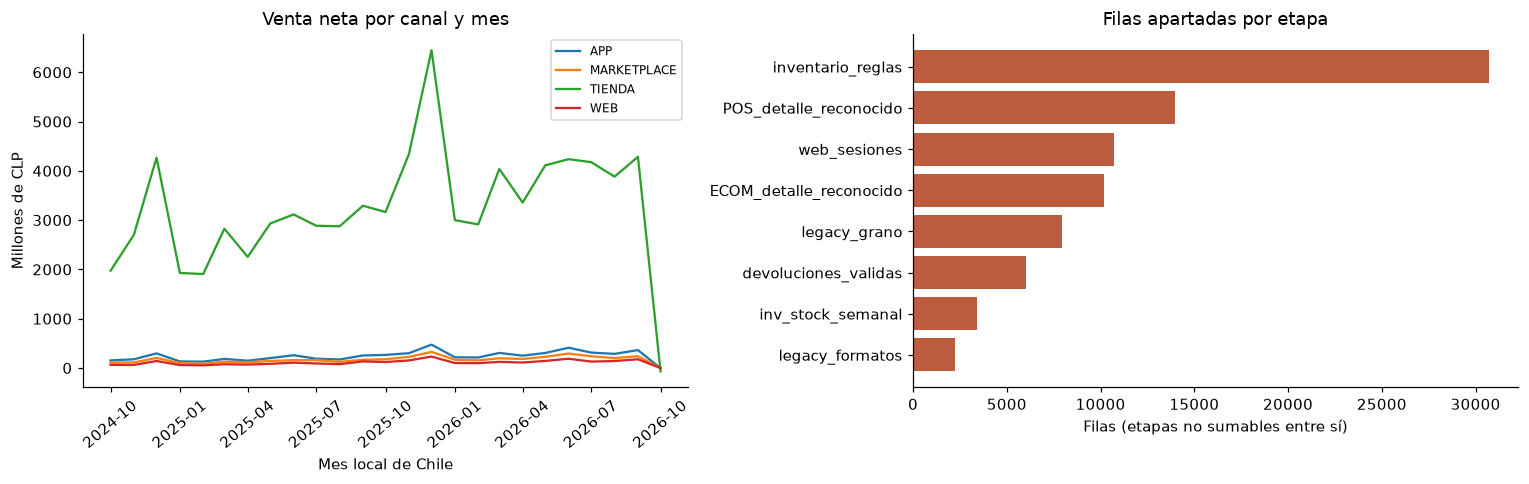

,tabla_destino,medida,regla,fuente,fila_bronze,hash_bronze,fila_cabecera,hash_cabecera
0,dw.fact_ventas,monto_neto,Prorrateo entero del neto reconocido de cabecera,pos_ventas_detalle,0,de88e446d9bf3dfe19e81bd0dae583cf896f910440a6b7...,0,6bcac06e89a517e422814ae92beebc71961b5e85657709...


El manifiesto de la ejecución identifica el archivo Bronze por hash. `_src_row` es su posición de fila en el orden de extracción; las claves naturales permiten relacionar eventos. Los datos personales permanecen en las capas locales restringidas y no se muestran en las evidencias.

In [19]:
# Visualización integrada: series y calidad, con unidades y periodo explícitos.
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
plot=monthly.assign(periodo=pd.to_datetime(dict(year=monthly.anio,month=monthly.mes,day=1)))
for canal,group in plot.groupby('canal'):
    axes[0].plot(group.periodo,group.venta_neta/1_000_000,label=canal)
axes[0].set(title='Venta neta por canal y mes',ylabel='Millones de CLP',xlabel='Mes local de Chile')
axes[0].legend(fontsize=8); axes[0].tick_params(axis='x',rotation=40)
problem=quality_df.loc[quality_df.rechazadas.gt(0)].nlargest(8,'rechazadas')
axes[1].barh(problem.etapa,problem.rechazadas,color='#bb5c3d')
axes[1].set(title='Filas apartadas por etapa',xlabel='Filas (etapas no sumables entre sí)')
axes[1].invert_yaxis();fig.tight_layout()
from io import BytesIO
from IPython.display import Image
chart_buffer=BytesIO();fig.savefig(chart_buffer,format='png',bbox_inches='tight')
fig.savefig(DATA/'gold'/'resumen.png',bbox_inches='tight')
display(Image(data=chart_buffer.getvalue()));plt.close(fig)

# Linaje completo de una medida sin exponer identidad personal.
sample=facts['fact_ventas'].iloc[0]
source_name='pos_ventas_detalle' if sample.fuente=='ventas_POS' else 'ecom_pedidos_detalle'
source_row=raw[source_name].loc[raw[source_name]._src_row.eq(sample._src_row)].iloc[0]
assert source_row._batch==sample._batch
lineage=pd.DataFrame([{'tabla_destino':'dw.fact_ventas','medida':'monto_neto',
    'regla':'Prorrateo entero del neto reconocido de cabecera','fuente':source_name,
    'fila_bronze':int(sample._src_row),'hash_bronze':sample._batch,
    'fila_cabecera':int(sample.cabecera_row),'hash_cabecera':sample.cabecera_batch}])
display(lineage)
display(Markdown('El manifiesto de la ejecución identifica el archivo Bronze por hash. `_src_row` es su posición de fila en el orden de extracción; las claves naturales permiten relacionar eventos. Los datos personales permanecen en las capas locales restringidas y no se muestran en las evidencias.'))

**Interpretación de los gráficos.** El periodo transaccional de referencia termina el 30/09/2026. Los meses posteriores pueden contener solamente devoluciones de ventas anteriores; no deben compararse como meses completos de venta. Las filas apartadas incluyen estados fuera del contrato de reconocimiento (por ejemplo, anulaciones), además de problemas de calidad. Las etapas tienen granos distintos y sus rechazos no se suman como si fueran registros únicos de toda la empresa.

In [20]:
# Diccionario semántico: se genera una fila por columna del modelo.
descriptions={
'monto_neto':('Venta de mercadería sin IVA antes de devoluciones, pesos CLP','venta; ingreso','SUM','No volver a descontar descuento ni IVA.'),
'monto_con_iva':('Mercadería con IVA después del descuento de línea, CLP','importe bruto','SUM','No incluye despacho web.'),
'monto_neto_devuelto':('Importe aprobado a restar de venta, sin IVA, CLP','devolución; reembolso','SUM','Restar una sola vez, según fecha de devolución.'),
'cantidad':('Unidades del evento','unidades; volumen','SUM','Interpretar según la tabla: venta o devolución.'),
'stock_sistema':('Unidades registradas en el corte de inventario','existencias; stock','SUM por corte','Nunca sumar fechas de corte.'),
'stock_fisico':('Unidades contadas; nulo significa no informado','conteo físico','SUM por corte','No reemplazar nulos por cero.'),
'stock_minimo':('Umbral mínimo por producto y sucursal','mínimo','No sumar entre fechas','Comparar con stock del mismo corte.'),
'punto_reposicion':('Umbral operativo para solicitar reposición','reposición','No sumar entre fechas','No confundir con stock mínimo.'),
'unidades_en_transito':('Unidades pendientes de llegada al corte','en tránsito','SUM por corte','No duplicar con órdenes.'),
'diferencia_stock':('Conteo físico menos stock de sistema','diferencia de inventario','SUM por corte','Nulo si no existe conteo.'),
'riesgo_reposicion':('Stock de sistema menor o igual al mínimo','riesgo; bajo mínimo','SUM banderas','Es una alerta, no prueba de quiebre efectivo.'),
'sin_conteo':('No se informó conteo físico','incompleto','SUM banderas','No equivale a stock cero.'),
'conteo_antiguo':('Conteo ausente o mayor a 30 días','desactualizado','SUM banderas','Evaluado respecto del corte.'),
'monto_atribuido':('Importe atribuido por plataforma de marketing, CLP','atribución','SUM','No sumar a ventas ni interpretar como causalidad.'),
'presupuesto_clp':('Presupuesto de campaña en CLP','inversión','Una vez por campaña','No sumarlo después de unir todos sus envíos.'),
'sin_consentimiento':('Envío a registro sin consentimiento vigente informado','consentimiento','SUM banderas','La fuente no tiene historia de consentimiento.'),
'embudo_inconsistente':('Interacción posterior en envío no entregado','embudo inválido','SUM banderas','Excluir de tasas condicionadas a entrega.'),
'entregado':('Envío entregado según plataforma','entrega','SUM banderas','Denominador de conversión reportada.'),
'abierto':('Apertura reportada del envío','apertura','SUM banderas','No es cliente único.'),
'click':('Clic reportado del envío','clic','SUM banderas','No equivale a venta.'),
'convertido':('Conversión reportada del envío','conversión','SUM banderas','Validar entregado; no implica causalidad.'),
'paginas_vistas':('Páginas vistas en la sesión','vistas','SUM','Una sesión por fila.'),
'duracion_seg':('Duración de sesión en segundos','duración','SUM o AVG','Expresar unidades.'),
'agrego_carrito':('La sesión agregó un producto al carrito','carrito','SUM banderas','No es cantidad de productos.'),
'inicio_checkout':('La sesión inició checkout','checkout','SUM banderas','No sumar a sesiones.'),
'compro':('Compra reportada por analítica web','compra web','SUM banderas','No reemplaza los pedidos entregados.'),
'cantidad_solicitada':('Unidades solicitadas en la orden','pedido reposición','SUM','Grano orden.'),
'cantidad_recibida':('Unidades recibidas acumuladas de la orden','recepción','SUM','Snapshot acumulado; no sumar versiones de la orden.'),
'es_actual':('Versión dimensional vigente','actual','No aplica','Para historia unir por clave del hecho, no filtrar actual.'),
'valido_desde':('Inicio inclusivo de vigencia','desde','No aplica','Intervalo [desde,hasta).'),
'valido_hasta':('Fin exclusivo de vigencia','hasta','No aplica','2100 representa fin abierto en el laboratorio.'),
'historia_observada':('Versión creada desde un cambio observado','historia','No aplica','False identifica línea base sin historia reconstruida.'),
'zona_anterior':('Zona previa retenida por SCD3','zona previa','No aplica','Conserva solo un cambio, no historia completa.'),
'_src_row':('Posición de la fila en su instantánea Bronze','linaje','No aplica','Resolver junto con _batch.'),
'_batch':('SHA256 de la instantánea fuente','lote','No aplica','Consultar manifiesto; no es fecha de negocio.'),
'cabecera_row':('Fila de cabecera en Bronze','linaje cabecera','No aplica','Explica el neto distribuido.'),
'cabecera_batch':('SHA256 de instantánea de cabecera','lote cabecera','No aplica','Resolver con manifiesto.'),
'cliente_nk':('Identificador seudonimizado de entidad resuelta','persona','COUNT DISTINCT','No contar versiones SCD como personas.'),
'documento_nk':('Identificador de documento prefijado por sistema','ticket; boleta; pedido','COUNT DISTINCT','No contar líneas para ticket promedio.'),
'region':('Región del rol de la dimensión','territorio','Agrupar','Distinguir región del cliente y de la sucursal.'),
'comuna':('Comuna del rol de la dimensión','localidad','Agrupar','No confundir residencia con lugar de venta.'),
'categoria':('Categoría homologada de producto','familia; rubro','Agrupar','Usar versión histórica enlazada al hecho.'),
'linea':('Línea de negocio','línea','Agrupar','WEB_SIN_HOMOLOGAR conserva incertidumbre.'),
'segmento':('Segmento CRM observado','tipo de cliente','Agrupar','SCD2; no inferir historia anterior.'),
'acepta_marketing':('Consentimiento vigente observado','consentimiento actual','No aplica','No reconstruye consentimiento histórico.'),
}
dictionary=[]
for table,frame in all_frames.items():
    for col in frame:
        if col in descriptions: desc,syn,agg,note=descriptions[col]
        elif col.endswith('_key'):
            desc='Clave sustituta de '+col.removesuffix('_key').replace('_',' ');syn='identificador';agg='No aplica';note='Unir con la dimensión correspondiente; 0 es desconocido/no aplicable.'
        elif col.endswith('_nk'):
            desc='Clave natural del evento o entidad '+col.removesuffix('_nk');syn='identificador de origen';agg='No aplica';note='Respetar el grano declarado.'
        else:
            desc={'fecha':'Fecha de calendario','anio':'Año calendario','mes':'Mes calendario 1–12','dia':'Día del mes','trimestre':'Trimestre calendario 1–4','semana_iso':'Semana ISO','anio_iso':'Año de la semana ISO','producto':'Descripción de producto','marca':'Marca comercial','subcategoria':'Subcategoría de producto','sucursal':'Nombre de sucursal','pais':'País del rol geográfico','zona':'Zona comercial actual','canal':'Canal de venta','codigo_campania':'Código homologado de campaña','nombre_campania':'Nombre de campaña','tipo_campania':'Tipo de campaña','fecha_inicio':'Inicio de campaña','fecha_fin':'Fin de campaña','calidad_campania':'Validez de periodo y presupuesto','dispositivo':'Dispositivo de la sesión','fuente_trafico':'Origen del tráfico web','estado':'Estado actual de la orden','fuente':'Sistema original de venta'}[col]
            syn=col.replace('_',' ');agg='Agrupar / filtrar';note='Atributo descriptivo; no sumar.'
        dictionary.append({'tabla':table,'columna':col,'tipo':str(frame[col].dtype),'descripcion':desc,'sinonimos':syn,'agregacion':agg,'regla_NLQ':note})
dictionary=pd.DataFrame(dictionary)
dictionary.to_parquet(DATA/'gold'/'diccionario_semantico.parquet',index=False)
display(Markdown('### Diccionario completo del modelo'))
from IPython.display import HTML
display(HTML('<details><summary>Ver todas las columnas y sus reglas semánticas</summary>'+dictionary.to_html(index=False,escape=True)+'</details>'))
display(Markdown('''### IA generativa: uso responsable
Ejemplo: **«¿Cuál fue la venta neta mensual por canal?»** se resuelve con la consulta
`monthly`: consulta el mart Comercial, cuyo agregado incorpora ventas y devoluciones por mes local.
**«¿Cuántos clientes activos hay?»** usa `COUNT DISTINCT cliente_nk`, no cuenta versiones SCD.
Estas consultas fueron escritas y verificadas; no se afirma haber conectado un modelo generativo.
Una futura integración NLQ debe usar vistas de solo lectura, límites de filas, permisos mínimos,
validación humana de SQL y este diccionario. No enviar RUT, correos ni credenciales a un modelo.
'''))

### Diccionario completo del modelo

tabla,columna,tipo,descripcion,sinonimos,agregacion,regla_NLQ
dim_producto,producto_key,int64,Clave sustituta de producto,identificador,No aplica,Unir con la dimensión correspondiente; 0 es desconocido/no aplicable.
dim_producto,producto_nk,str,Clave natural del evento o entidad producto,identificador de origen,No aplica,Respetar el grano declarado.
dim_producto,producto,str,Descripción de producto,producto,Agrupar / filtrar,Atributo descriptivo; no sumar.
dim_producto,linea,str,Línea de negocio,línea,Agrupar,WEB_SIN_HOMOLOGAR conserva incertidumbre.
dim_producto,categoria,str,Categoría homologada de producto,familia; rubro,Agrupar,Usar versión histórica enlazada al hecho.
dim_producto,subcategoria,str,Subcategoría de producto,subcategoria,Agrupar / filtrar,Atributo descriptivo; no sumar.
dim_producto,marca,str,Marca comercial,marca,Agrupar / filtrar,Atributo descriptivo; no sumar.
dim_producto,valido_desde,datetime64[us],Inicio inclusivo de vigencia,desde,No aplica,"Intervalo [desde,hasta)."
dim_producto,valido_hasta,datetime64[us],Fin exclusivo de vigencia,hasta,No aplica,2100 representa fin abierto en el laboratorio.
dim_producto,es_actual,bool,Versión dimensional vigente,actual,No aplica,"Para historia unir por clave del hecho, no filtrar actual."


### IA generativa: uso responsable
Ejemplo: **«¿Cuál fue la venta neta mensual por canal?»** se resuelve con la consulta
`monthly`: consulta el mart Comercial, cuyo agregado incorpora ventas y devoluciones por mes local.
**«¿Cuántos clientes activos hay?»** usa `COUNT DISTINCT cliente_nk`, no cuenta versiones SCD.
Estas consultas fueron escritas y verificadas; no se afirma haber conectado un modelo generativo.
Una futura integración NLQ debe usar vistas de solo lectura, límites de filas, permisos mínimos,
validación humana de SQL y este diccionario. No enviar RUT, correos ni credenciales a un modelo.


In [21]:
# Capa semántica del producto final: grano y reglas de agregación de los cuatro data marts.
mart_fields={
 'venta_sin_devoluciones_clp':('Venta reconocida sin IVA antes de devoluciones, en CLP','SUM','No volver a descontar IVA ni descuentos.'),
 'devoluciones_clp':('Reembolsos aprobados y trazables, sin IVA, CLP','SUM','Se restan una sola vez de la venta.'),
 'venta_neta_clp':('Venta reconocida menos devoluciones, CLP','SUM','Puede ser negativa en meses con solo devoluciones.'),
 'unidades_vendidas':('Unidades vendidas reconocidas','SUM','No contiene unidades devueltas.'),
 'unidades_devueltas':('Unidades devueltas aprobadas','SUM','Restar si se requiere volumen neto.'),
 'documentos':('Documentos distintos reconocidos en el periodo, sucursal y canal','SUM en este grano','Un documento pertenece a una sola fecha, sucursal y canal; ver prueba de conciliación.'),
 'envios':('Envíos registrados de la campaña','SUM','No representa clientes distintos.'),
 'entregados':('Envíos entregados de la campaña','SUM','Denominador de conversión reportada.'),
 'abiertos':('Envíos con apertura reportada','SUM','No equivale a clientes únicos.'),
 'clicks':('Envíos con clic reportado','SUM','No equivale a ventas.'),
 'conversiones_entregadas':('Envíos entregados con conversión reportada','SUM','No demuestra causalidad; excluir conversiones de envíos no entregados.'),
 'sin_consentimiento':('Envíos sin consentimiento vigente observado','SUM','La fuente no ofrece historia del consentimiento.'),
 'sesiones':('Sesiones web asociadas a la campaña por UTM','SUM','No se unen sesiones a cada línea de venta.'),
 'con_carrito':('Sesiones que agregaron al carrito','SUM','Indicador reportado por analítica web.'),
 'con_checkout':('Sesiones que iniciaron checkout','SUM','No es cantidad de pedidos.'),
 'compra_reportada':('Sesiones con compra reportada','SUM','No sustituye pedidos entregados del mart Comercial.'),
 'documentos_asociados':('Documentos reconocidos asociados a una campaña o al miembro 0','SUM','No presupone exposición causal a la campaña.'),
 'venta_reconocida_clp':('Venta reconocida asociada al cupón de la campaña, sin IVA','SUM','Campaña 0 agrupa documentos sin atribución.'),
 'venta_neta_asociada_clp':('Venta asociada menos sus devoluciones trazables, CLP','SUM','La atribución sigue el documento original; no es un efecto causal.'),
}
mart_fields.update({
 'cliente_nk':('Identidad resuelta y seudonimizada, estable entre versiones SCD','COUNT DISTINCT','Una fila por identidad y mes. No sumar clientes únicos entre meses; se excluye la clave desconocida.'),
 'cliente_key_corte':('Versión SCD válida al final del día de corte mensual','No aplica','FK a dim_cliente; 0 si no hay versión observada al corte. No utilizar siempre la versión actual.'),
 'fecha_corte_key':('Fecha explícita de evaluación mensual','Agrupar / filtrar','Fin de mes; el último periodo se corta en fecha_fin, cobertura fiable de compras del dataset.'),
 'sin_version_al_corte':('No hay atributos SCD observados para esa identidad al corte','SUM por corte','No elimina la identidad ni reasigna sus importes; describe incertidumbre de atributos.'),
 'compras':('Documentos de compra distintos del cliente en el mes','SUM','Contar documentos, no líneas; cero en meses sin compra.'),
 'devoluciones':('Registros aprobados de devolución del cliente en el mes','SUM','No son compras ni necesariamente documentos completos.'),
 'unidades_compradas':('Unidades reconocidas de compras del mes','SUM','Mantener separadas de las unidades devueltas.'),
 'primera_compra_mes_key':('Primera compra observada en ese mes','MIN con control de nulos','Nulo si el mes no tiene compras; no representa adquisición real del cliente.'),
 'ultima_compra_mes_key':('Última compra observada en ese mes','MAX','Nulo en meses sin compra.'),
 'ultima_compra_hasta_corte_key':('Última compra observada hasta el corte','MAX por identidad','Permite calcular recencia aunque no haya compra en el mes actual.'),
 'canal_principal_mes_key':('Canal con más documentos de compra del mes','No aplica','Desempate por importe y luego clave menor; 0 si no hay compras. Describe conducta observada.'),
 'compras_acumuladas':('Documentos de compra observados desde el inicio de historia hasta el corte','SUM entre clientes de un mismo corte','No sumar distintos cortes del mismo cliente.'),
 'venta_neta_acumulada_clp':('Venta neta observada acumulada al corte, CLP','SUM entre clientes de un mismo corte','No es valor de vida predicho ni margen; no sumar snapshots temporales.'),
 'frecuencia_12m':('Compras en hasta 12 meses calendario terminados en el mes del corte','SUM entre clientes de un mismo corte','Incluye meses sin compra; no sumar ventanas superpuestas.'),
 'monetario_12m_clp':('Venta neta en hasta 12 meses calendario al corte, CLP','SUM entre clientes de un mismo corte','RFM monetario observado; incluye devoluciones y puede ser negativo.'),
 'meses_observados_12m':('Meses disponibles desde primera actividad dentro de la ventana','No aplica','Entre 1 y 12; distingue ventanas incompletas y no demuestra fecha real de adquisición.'),
 'recencia_dias':('Días del corte a la última compra observada','AVG / distribución por corte','Nulo sin compras observadas; no usar la fecha del sistema.'),
 'activo_6m':('Última compra dentro de los seis meses calendario previos al corte, inclusive','SUM por corte','El corte debe coincidir al comparar indicadores; no es el estado ACTIVO del CRM.'),
})

mart_rows=[]
for table,frame in mart_frames.items():
    for col in frame:
        if col in mart_fields: desc,agg,note=mart_fields[col]
        elif col in descriptions:
            desc,_,agg,note=descriptions[col]
        elif col.endswith('_key'):
            desc='Clave compartida de '+col.removesuffix('_key');agg='No aplica'
            note='FK a dimensión conformada; no reemplazar la clave histórica por la versión actual.'
        else:
            desc={'anio':'Año calendario del movimiento','mes':'Mes local de Chile del movimiento'}[col]
            agg='Agrupar';note='Interpretar conjuntamente año y mes.'
        mart_rows.append({'tabla':table,'columna':col,'tipo':str(frame[col].dtype),
            'descripcion':desc,'sinonimos':col.replace('_',' '),'agregacion':agg,'regla_NLQ':note})
for table,col,desc,formula,note in [
 ('dm_clientes.v_clientes_mensuales','ticket_promedio_mes_clp','Venta antes de devoluciones por compra del mes',
  'SUM(venta_sin_devoluciones_clp)/SUM(compras)','Nulo si no hay compras; no promediar promedios.'),
 ('dm_clientes.v_clientes_mensuales','es_recurrente_observado','Al menos dos documentos de compra observados hasta el corte',
  'SUM por corte','Comparar una sola fecha por identidad; la historia disponible puede ser parcial.'),
 ('dm_comercial.v_kpis_ventas','ticket_promedio_clp','Venta antes de devoluciones por documento',
  'SUM(venta_sin_devoluciones_clp)/SUM(documentos)','No promediar tickets de grupos; nulo si no hay documentos.'),
 ('dm_marketing.v_kpis_campanias','tasa_conversion_reportada','Proporción de envíos entregados con conversión',
  'SUM(conversiones_entregadas)/SUM(entregados)','No promediar tasas; no implica causalidad.'),
 ('dm_marketing.v_kpis_campanias','retorno_atribuido','Monto de plataforma respecto del presupuesto',
  'monto_atribuido/presupuesto_clp','Presupuesto una vez por campaña válida; no es ROI de beneficio.')]:
    mart_rows.append({'tabla':table,'columna':col,'tipo':'ratio derivado','descripcion':desc,
        'sinonimos':col.replace('_',' '),'agregacion':formula,'regla_NLQ':note})
mart_rows.append({'tabla':'dm_clientes.v_cobertura_identidad','columna':'dentro_cobertura_compras',
    'tipo':'bandera 0/1','descripcion':'Evento dentro del periodo de compras cubierto por fecha_fin',
    'sinonimos':'cobertura temporal','agregacion':'Agrupar / filtrar',
    'regla_NLQ':'Filtrar 1 para conciliar con clientes_mensuales; 0 conserva reembolsos posteriores, sin inferir inactividad.'})
mart_dictionary=pd.DataFrame(mart_rows)
mart_dictionary.to_parquet(DATA/'gold'/'datamarts'/'diccionario_semantico.parquet',index=False)
dictionary=pd.concat([dictionary,mart_dictionary],ignore_index=True)
dictionary.to_parquet(DATA/'gold'/'diccionario_semantico.parquet',index=False)
display(Markdown('### Diccionario semántico de los data marts'))
display(HTML('<details><summary>Ver columnas y reglas de los productos finales</summary>'+
             mart_dictionary.to_html(index=False,escape=True)+'</details>'))

### Diccionario semántico de los data marts

tabla,columna,tipo,descripcion,sinonimos,agregacion,regla_NLQ
dm_comercial.ventas_mensuales,anio,int64,Año calendario del movimiento,anio,Agrupar,Interpretar conjuntamente año y mes.
dm_comercial.ventas_mensuales,mes,int64,Mes local de Chile del movimiento,mes,Agrupar,Interpretar conjuntamente año y mes.
dm_comercial.ventas_mensuales,sucursal_key,int64,Clave compartida de sucursal,sucursal key,No aplica,FK a dimensión conformada; no reemplazar la clave histórica por la versión actual.
dm_comercial.ventas_mensuales,canal_key,int64,Clave compartida de canal,canal key,No aplica,FK a dimensión conformada; no reemplazar la clave histórica por la versión actual.
dm_comercial.ventas_mensuales,venta_sin_devoluciones_clp,int64,"Venta reconocida sin IVA antes de devoluciones, en CLP",venta sin devoluciones clp,SUM,No volver a descontar IVA ni descuentos.
dm_comercial.ventas_mensuales,devoluciones_clp,int64,"Reembolsos aprobados y trazables, sin IVA, CLP",devoluciones clp,SUM,Se restan una sola vez de la venta.
dm_comercial.ventas_mensuales,venta_neta_clp,int64,"Venta reconocida menos devoluciones, CLP",venta neta clp,SUM,Puede ser negativa en meses con solo devoluciones.
dm_comercial.ventas_mensuales,unidades_vendidas,int64,Unidades vendidas reconocidas,unidades vendidas,SUM,No contiene unidades devueltas.
dm_comercial.ventas_mensuales,unidades_devueltas,int64,Unidades devueltas aprobadas,unidades devueltas,SUM,Restar si se requiere volumen neto.
dm_comercial.ventas_mensuales,documentos,int64,"Documentos distintos reconocidos en el periodo, sucursal y canal",documentos,SUM en este grano,"Un documento pertenece a una sola fecha, sucursal y canal; ver prueba de conciliación."


In [22]:
# Pruebas de datos y errores: se comprueban propiedades, no solo que el código termine.
checks=ingestion_checks.copy()
assert legacy_date(datetime(2023,1,13))==pd.Timestamp('2023-01-13')
assert legacy_date('2023-01-13 00:00:00')==pd.Timestamp('2023-01-13')
assert legacy_date('44999')==pd.Timestamp('1899-12-30')+pd.Timedelta(days=44999)
assert pd.isna(legacy_date('01/02/2023'))
assert pd.isna(legacy_date('2023-99-01 00:00:00'))
checks.append({'prueba':'Excel: fecha nativa, ISO y serial válidos; texto ambiguo en cuarentena','resultado':'OK'})
def passed(name): checks.append({'prueba':name,'resultado':'OK'})
validate_destination(facts);passed('Grano, PK, FK y medidas no negativas')
assert int(kpi.venta_antes_devoluciones.iloc[0])==int(sales.monto_neto.sum());passed('Cuadratura monetaria Pandas vs SQL Server')
assert int(kpi.venta_neta.iloc[0])==int(monthly.venta_neta.sum());passed('Venta neta vs agregación mensual')
assert quality_df.leidas.eq(quality_df.aceptadas+quality_df.rechazadas+quality_df.duplicadas).all();passed('Balance de filas por etapa')
mini=pd.DataFrame({'doc':['A']*3,'peso':[1,1,1],'neto':[10]*3})
assert list(allocate_integer(mini,'doc','peso','neto'))==[4,3,3];passed('Prorrateo entero con resto')
broken={n:f.head(1).copy() for n,f in facts.items()}
broken['fact_ventas'].loc[:,'fecha_key']=99999999
try:
    validate_destination(broken)
except ValueError: passed('Quality gate detiene FK inválida antes de publicar')
else: raise AssertionError('Se aceptó una clave inválida')
probe='probe_'+uuid.uuid4().hex[:20]
try:
    with DW.begin() as conn:
        conn.execute(text("INSERT INTO ctl.ejecuciones(run_id,estado) VALUES(:id,'TEST')"),{'id':probe})
        raise RuntimeError('Falla controlada para verificar rollback')
except RuntimeError: pass
assert query('SELECT COUNT(*) n FROM ctl.ejecuciones WHERE run_id=:id',{'id':probe}).iloc[0,0]==0
passed('Rollback real en SQL Server ante una excepción')

# Comparar una segunda publicación completa: conteos, importes y claves permanecen iguales.
def destination_signature():
    result={}
    names=['dw.'+name for name in facts]+[s+'.'+v['tabla'] for s,v in MARTS.items()]
    for name in names:
        value=query(f'SELECT COUNT_BIG(*) n,CHECKSUM_AGG(BINARY_CHECKSUM(*)) checksum FROM {name}').iloc[0].to_dict()
        result[name]=value
    return result
before=destination_signature()
publish(RUN_ID[:24]+'_repeat')
after=destination_signature()
assert before==after
passed('Segunda publicación real: mismos hechos y cuatro data marts, sin duplicados')
display(Markdown('El checksum de SQL Server es un control complementario, no una prueba criptográfica: se combina con PK, FK, conteos y conciliación monetaria.'))
for name,nk,sk,t2,t1,t3 in [
    ('dim_cliente','cliente_nk','cliente_key',['comuna','region','segmento'],['acepta_marketing'],[]),
    ('dim_producto','producto_nk','producto_key',['linea','categoria','subcategoria'],['producto','marca'],[]),
    ('dim_sucursal','sucursal_nk','sucursal_key',[],['sucursal','comuna','region','pais'],['zona'])]:
    inc={'dim_cliente':client_master,'dim_producto':product_master,'dim_sucursal':store_master}[name]
    repeated=scd_merge(inc,dimensions[name],nk,sk,t2,t1,t3)
    assert len(repeated)==len(dimensions[name])
    validate_scd(repeated,nk,sk)
passed('Reejecución de SCD sin crear nuevas versiones')
display(pd.DataFrame(checks))

# Pruebas de los data marts: integridad, conciliación y publicación atómica.
assert len(MARTS)==4 and len(mart_catalog)==4
passed('Cuatro data marts físicos publicados en esquemas de SQL Server')
mart_sources={
 'dm_comercial.ventas_mensuales': ['anio','mes','sucursal_key','canal_key'],
 'dm_operaciones.inventario_actual':['fecha_key','producto_key','sucursal_key'],
 'dm_marketing.campanias_resumen':['campania_key'],
 'dm_clientes.clientes_mensuales':['cliente_nk','anio','mes']}
for name,keys in mart_sources.items():
    assert not mart_frames[name].duplicated(keys).any()
    assert not mart_frames[name][keys].isna().any().any()
passed('Grano y claves únicas en las cuatro tablas de data mart')
assert int(query('SELECT SUM(documentos) n FROM dm_comercial.ventas_mensuales').iloc[0,0])==sales.documento_nk.nunique()
assert int(query('SELECT SUM(venta_neta_clp) n FROM dm_comercial.ventas_mensuales').iloc[0,0])==int(kpi.venta_neta.iloc[0])
passed('Comercial concilia documentos distintos y venta neta con el DWH')
ops=mart_frames['dm_operaciones.inventario_actual']
latest_stock=facts['fact_inventario'].loc[facts['fact_inventario'].fecha_key.eq(facts['fact_inventario'].fecha_key.max())]
assert len(ops)==len(latest_stock) and ops.fecha_key.nunique()==1
assert int(ops.stock_sistema.sum())==int(latest_stock.stock_sistema.sum())
assert int(ops.riesgo_reposicion.sum())==int(latest_stock.riesgo_reposicion.sum())
passed('Operaciones conserva únicamente el último corte común y sus existencias')
mk=mart_frames['dm_marketing.campanias_resumen']
assert int(mk.envios.sum())==len(facts['fact_marketing'])
assert int(mk.sesiones.sum())==len(facts['fact_web'])
assert int(mk.documentos_asociados.sum())==sales.documento_nk.nunique()
assert int(mk.venta_neta_asociada_clp.sum())==int(kpi.venta_neta.iloc[0])
assert mk.conversiones_entregadas.le(mk.entregados).all()
passed('Marketing integra agregados sin multiplicar envíos, sesiones o ingresos')
objects=query('''SELECT s.name esquema,o.name objeto,RTRIM(o.type) tipo
    FROM sys.objects o JOIN sys.schemas s ON o.schema_id=s.schema_id
    WHERE s.name IN ('dm_comercial','dm_operaciones','dm_marketing','dm_clientes') AND o.type IN ('U','V')''')
assert objects.query("tipo == 'U'").groupby('esquema').size().to_dict()=={s:1 for s in MARTS}
assert query('''SELECT COUNT_BIG(*) n FROM sys.foreign_keys
    WHERE parent_object_id IN (OBJECT_ID('dm_comercial.ventas_mensuales'),
    OBJECT_ID('dm_operaciones.inventario_actual'),OBJECT_ID('dm_marketing.campanias_resumen'),OBJECT_ID('dm_clientes.clientes_mensuales'))''').iloc[0,0]==12
passed('Tablas persistentes, vistas y doce FK a dimensiones conformadas verificadas')
before_mart_rollback=destination_signature()
try:
    with DW.begin() as conn:
        clear_datamarts(conn)
        raise RuntimeError('Fallo controlado de refresco de data marts')
except RuntimeError as exc:
    if str(exc)!='Fallo controlado de refresco de data marts': raise
assert destination_signature()==before_mart_rollback
passed('Una falla controlada restaura los cuatro data marts mediante rollback')
display(pd.DataFrame(checks))
# Clientes: conciliación de la población identificada, cobertura y snapshots completos.
cm=mart_frames['dm_clientes.clientes_mensuales']
assert cm.cliente_nk.ne('DESCONOCIDO').all()
assert not cm.duplicated(['cliente_nk','anio','mes']).any()
with DW.connect() as conn: validate_customer_mart(conn)
assert int(cm.compras.sum())==int(query('SELECT COUNT_BIG(DISTINCT documento_nk) n FROM dw.fact_ventas WHERE cliente_key<>0 AND fecha_key<=:cut',{'cut':CUSTOMER_CUTOFF_KEY}).iloc[0,0])
assert int(cm.venta_sin_devoluciones_clp.sum())==int(query('SELECT SUM(monto_neto) n FROM dw.fact_ventas WHERE cliente_key<>0 AND fecha_key<=:cut',{'cut':CUSTOMER_CUTOFF_KEY}).iloc[0,0])
passed('Clientes: una identidad por mes, documentos distintos y ventas identificadas conciliadas')
coverage=query('''SELECT SUM(venta_sin_devoluciones_clp) ventas,SUM(devoluciones_clp) devoluciones,
    SUM(venta_neta_clp) neto FROM dm_clientes.v_cobertura_identidad''').iloc[0]
assert int(coverage.ventas)==int(kpi.venta_antes_devoluciones.iloc[0])
assert int(coverage.devoluciones)==int(kpi.devoluciones_netas.iloc[0])
assert int(coverage.neto)==int(kpi.venta_neta.iloc[0])
covered=query('SELECT SUM(venta_neta_clp) n FROM dm_clientes.v_cobertura_identidad WHERE identificado=1 AND dentro_cobertura_compras=1').iloc[0,0]
assert int(covered)==int(cm.venta_neta_clp.sum())
passed('Clientes: cobertura identificada y anónima concilia con la venta total sin inventar personas')
continuity=query('''SELECT COUNT_BIG(*) n FROM (
    SELECT cliente_nk,COUNT_BIG(*) observados,
        DATEDIFF(month,MIN(DATEFROMPARTS(anio,mes,1)),MAX(DATEFROMPARTS(anio,mes,1)))+1 esperados
    FROM dm_clientes.clientes_mensuales GROUP BY cliente_nk) x WHERE observados<>esperados''')
assert int(continuity.iloc[0,0])==0
assert cm.compras.eq(0).any()
assert int(cm.fecha_corte_key.max())==CUSTOMER_CUTOFF_KEY
assert len(cm.loc[cm.fecha_corte_key.eq(CUSTOMER_CUTOFF_KEY)])==cm.cliente_nk.nunique()
passed('Clientes: meses sin compra incluidos y ventanas calendario sin huecos')
bad_windows=query('''WITH calculado AS (
    SELECT *,SUM(compras) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS BETWEEN 11 PRECEDING AND CURRENT ROW) f,
    SUM(venta_neta_clp) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS BETWEEN 11 PRECEDING AND CURRENT ROW) m,
    MAX(ultima_compra_mes_key) OVER(PARTITION BY cliente_nk ORDER BY anio,mes ROWS UNBOUNDED PRECEDING) u
    FROM dm_clientes.clientes_mensuales)
    SELECT COUNT_BIG(*) n FROM calculado c LEFT JOIN dw.dim_fecha d ON c.fecha_corte_key=d.fecha_key
    LEFT JOIN dw.dim_fecha u ON c.ultima_compra_hasta_corte_key=u.fecha_key
    WHERE frecuencia_12m<>f OR monetario_12m_clp<>m OR COALESCE(c.ultima_compra_hasta_corte_key,0)<>COALESCE(c.u,0)
       OR COALESCE(recencia_dias,-1)<>COALESCE(DATEDIFF(day,u.fecha,d.fecha),-1)''')
assert int(bad_windows.iloc[0,0])==0
assert cm.recencia_dias.dropna().ge(0).all()
passed('Clientes: frecuencia, monetario y recencia verificados al corte explícito')
assert len(customer_period)==1
assert int(customer_period.activos_6m.iloc[0])==int(active.clientes_activos.iloc[0])
passed('Clientes: indicador activo de seis meses coincide para la misma fecha de negocio')
with DW.begin() as conn:
    fixture_result=check_customer_fixture(conn)
display(Markdown('### Caso controlado de Clientes: dos versiones SCD, un mes sin compra y devolución posterior'))
display(fixture_result)
passed('Clientes: SQL de Clientes validado con dos SCD, meses vacíos y reembolsos dentro/fuera de cobertura')
display(pd.DataFrame(checks))
manifest['validation']={'checks_passed':len(checks),'repeat_run_id':RUN_ID[:24]+'_repeat','datamarts_checked':len(MARTS)}
(DATA/'control'/f'{RUN_ID}.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

El checksum de SQL Server es un control complementario, no una prueba criptográfica: se combina con PK, FK, conteos y conciliación monetaria.

,prueba,resultado
0,"Tres adaptadores reales: 14 fuentes SQL, un CS...",OK
1,Archivos originales intactos y copias Bronze c...,OK
2,Archivo ausente detiene la ingestión sin fallb...,OK
3,Contrato detecta una columna obligatoria ausen...,OK
4,"Excel: fecha nativa, ISO y serial válidos; tex...",OK
5,"Grano, PK, FK y medidas no negativas",OK
6,Cuadratura monetaria Pandas vs SQL Server,OK
7,Venta neta vs agregación mensual,OK
8,Balance de filas por etapa,OK
9,Prorrateo entero con resto,OK


,prueba,resultado
0,"Tres adaptadores reales: 14 fuentes SQL, un CS...",OK
1,Archivos originales intactos y copias Bronze c...,OK
2,Archivo ausente detiene la ingestión sin fallb...,OK
3,Contrato detecta una columna obligatoria ausen...,OK
4,"Excel: fecha nativa, ISO y serial válidos; tex...",OK
5,"Grano, PK, FK y medidas no negativas",OK
6,Cuadratura monetaria Pandas vs SQL Server,OK
7,Venta neta vs agregación mensual,OK
8,Balance de filas por etapa,OK
9,Prorrateo entero con resto,OK


### Caso controlado de Clientes: dos versiones SCD, un mes sin compra y devolución posterior

,anio,mes,compras,venta_neta_clp,cliente_key_corte,compras_acumuladas,frecuencia_12m,recencia_dias
0,2026,5,2,350,102,2,2,11
1,2026,6,0,0,102,2,2,41
2,2026,7,1,40,102,3,3,30
3,2026,8,0,-25,102,3,3,35


,prueba,resultado
0,"Tres adaptadores reales: 14 fuentes SQL, un CS...",OK
1,Archivos originales intactos y copias Bronze c...,OK
2,Archivo ausente detiene la ingestión sin fallb...,OK
3,Contrato detecta una columna obligatoria ausen...,OK
4,"Excel: fecha nativa, ISO y serial válidos; tex...",OK
5,"Grano, PK, FK y medidas no negativas",OK
6,Cuadratura monetaria Pandas vs SQL Server,OK
7,Venta neta vs agregación mensual,OK
8,Balance de filas por etapa,OK
9,Prorrateo entero con resto,OK


10905

In [23]:
# Optimización medida: formatos y selección de columnas; los tiempos no prometen aceleración.
measure=facts['fact_ventas'][['fecha_key','producto_key','cantidad','monto_neto']]
csv_path=DATA/'gold'/'comparacion_ventas.csv';pq_path=DATA/'gold'/'comparacion_ventas.parquet'
measure.to_csv(csv_path,index=False);measure.to_parquet(pq_path,index=False)
times=[]
for fmt,path,read in [('CSV',csv_path,lambda:pd.read_csv(csv_path,usecols=['monto_neto'])),
                      ('Parquet',pq_path,lambda:pd.read_parquet(pq_path,columns=['monto_neto']))]:
    durations=[]
    for _ in range(3):
        start=time.perf_counter(); loaded=read(); durations.append(time.perf_counter()-start)
    assert int(loaded.monto_neto.sum())==int(measure.monto_neto.sum())
    times.append({'formato':fmt,'bytes':path.stat().st_size,'lectura_mediana_seg':float(np.median(durations))})
display(pd.DataFrame(times))

# Plan de ejecución real: la inspección no ejecuta la consulta ni altera índices.
odbc=DW.raw_connection()
try:
    cursor=odbc.cursor();cursor.execute('SET SHOWPLAN_XML ON')
    cursor.execute('SELECT SUM(monto_neto) FROM dw.fact_ventas WHERE fecha_key BETWEEN 20260901 AND 20260930')
    plan_xml=cursor.fetchone()[0]
    cursor.execute('SET SHOWPLAN_XML OFF'); cursor.close()
finally: odbc.close()
(DATA/'control'/'plan_consulta.xml').write_text(plan_xml,encoding='utf-8')
print('Plan SQL Server capturado. Usa operador Index Seek:', 'Index Seek' in plan_xml)
# El benchmark compara venta antes de devoluciones: excluir grupos sin documentos de venta.
# Los meses de solo devolución permanecen en el mart para los indicadores netos.
timings=[]
queries={
 'Hecho detallado':'''SELECT d.anio,d.mes,f.canal_key,SUM(f.monto_neto) importe
 FROM dw.fact_ventas f JOIN dw.dim_fecha d ON f.fecha_key=d.fecha_key GROUP BY d.anio,d.mes,f.canal_key''',
 'Data mart Comercial':'''SELECT anio,mes,canal_key,SUM(venta_sin_devoluciones_clp) importe FROM dm_comercial.ventas_mensuales WHERE documentos>0 GROUP BY anio,mes,canal_key'''}
reference=None
for label,sql in queries.items():
    durations=[]
    for _ in range(3):
        start=time.perf_counter(); result=query(sql);durations.append(time.perf_counter()-start)
    result=result.sort_values(['anio','mes','canal_key']).reset_index(drop=True)
    if reference is None: reference=result
    else: pd.testing.assert_frame_equal(reference,result,check_dtype=False)
    timings.append({'consulta':label,'mediana_seg':float(np.median(durations)),'filas':len(result)})
display(pd.DataFrame(timings))
display(Markdown('''Los tiempos corresponden al equipo local y tres lecturas, con posible caché.
Los índices aceleran filtros a cambio de espacio y costo de escritura. El agregado mensual
reduce filas consultadas y se refresca tras la publicación. El particionamiento implementado
es de **archivos Parquet**; no se afirma particionar tablas de SQL Server.
Delta Lake y ADLS son alternativas de evolución, no componentes ejecutados de esta solución.
Parquet por sí solo no aporta transacciones ACID ni time travel: este trabajo es DWH + capas de archivos.
'''))

,formato,bytes,lectura_mediana_seg
0,CSV,14295827,0.071087
1,Parquet,2172193,0.008972


Plan SQL Server capturado. Usa operador Index Seek: False


,consulta,mediana_seg,filas
0,Hecho detallado,0.062532,96
1,Data mart Comercial,0.005874,96


Los tiempos corresponden al equipo local y tres lecturas, con posible caché.
Los índices aceleran filtros a cambio de espacio y costo de escritura. El agregado mensual
reduce filas consultadas y se refresca tras la publicación. El particionamiento implementado
es de **archivos Parquet**; no se afirma particionar tablas de SQL Server.
Delta Lake y ADLS son alternativas de evolución, no componentes ejecutados de esta solución.
Parquet por sí solo no aporta transacciones ACID ni time travel: este trabajo es DWH + capas de archivos.


In [24]:
# Evidencia y conclusiones calculadas a partir de la ejecución verificada.
unknowns=pd.DataFrame([{'dimension':c,'lineas_sin_resolver':int(facts['fact_ventas'][c].eq(0).sum()),
                       'porcentaje':round(100*facts['fact_ventas'][c].eq(0).mean(),2)}
                      for c in ['producto_key','sucursal_key','cliente_key','campania_key']])
display(unknowns)
display(Markdown('Campaña 0 también significa ausencia de campaña; no todo miembro 0 constituye un error. Cliente 0 puede representar compra anónima.'))
display(controls['definiciones_kpi_por_area'])
display(Markdown('### Reportes manuales: cobertura independiente'))
legacy_summary=legacy.assign(anio=legacy.fecha_limpia.dt.year).groupby('anio').agg(filas=('fecha_limpia','size'),importe_reportado=('monto_limpio','sum')).reset_index()
display(legacy_summary)
display(Markdown('Los importes legacy conservan su definición original; no se declaran venta neta sin IVA. Las fechas ambiguas quedan en cuarentena. Su conciliación financiera exige confirmar el criterio y periodo de cada archivo; no se incorporan al hecho transaccional.'))

summary=f'''### Conclusiones de la ejecución
- Se extrajeron **{int(inventory.filas.sum()):,}** registros de 16 conjuntos: 14 por PostgreSQL,
  campañas desde CSV y reportes manuales desde Excel. La instantánea SQL es de solo lectura;
  los archivos de entrada se conservaron por contenido con SHA256.
- El CSV alimentó `dim_campania`; el XLSX pasó por tipado, validaciones y conciliación.
  El Excel exportado contiene fechas ya tipadas: se respeta esa representación y no se afirma
  reconstruir el texto ambiguo que pudo existir antes de la exportación.
- Se publicaron **{len(facts['fact_ventas']):,} líneas de venta** y cinco hechos complementarios en SQL Server.
- El pipeline culminó en **4 data marts dependientes**: Comercial, Operaciones, Marketing-Digital y Clientes,
  con tablas resumen persistentes, vistas de detalle y dimensiones conformadas compartidas.
  Sus conteos figuran en el catálogo y en `ctl.datamart_publicaciones`.
- Clientes publica series mensuales por identidad, meses sin compras, atributos SCD al corte,
  medidas RFM observadas y cobertura financiera de operaciones anónimas por separado.
- La venta reconocida antes de devoluciones fue **{int(kpi.venta_antes_devoluciones.iloc[0]):,} CLP**;
  las devoluciones netas aceptadas fueron **{int(kpi.devoluciones_netas.iloc[0]):,} CLP**.
  La venta neta resultante es **{int(kpi.venta_neta.iloc[0]):,} CLP**, bajo el contrato documentado.
- Se verificaron **{len(checks)} controles**, incluida una segunda publicación real de hechos y marts
  sin duplicados, conciliación contra el DWH y rollback controlado de las tablas finales.
- La calidad mejora al homologar, separar conflictos y conservar rechazos. No significa que
  todos los datos originales sean correctos: persisten identidades no resueltas y supuestos financieros.

### Límites y siguientes pasos
La historia SCD comienza con observaciones del pipeline: la fuente no entrega cambios históricos.
Los estados actuales de pedidos no permiten reconstruir toda su evolución; se excluyen DEVUELTO
del reconocimiento para evitar doble descuento. Confirmar con Finanzas si se requiere reconocer
la venta original y su reversa, así como la base tributaria de los reembolsos.
No hay autenticación de usuarios analíticos implementada en este notebook: la conexión del laboratorio
usa Windows; en producción se separarían cuentas de lectura, carga y consumo.
El log no imprime datos personales, pero Bronze/Silver requieren permisos de carpeta y retención.
No se publicaron datos ni código en GitHub. El historial Git local documenta el desarrollo real.
'''
display(Markdown(summary))
history=subprocess.run(['git','log','--format=%h %s','-12'],capture_output=True,text=True,encoding='utf-8',errors='replace',check=True).stdout
print('Historial local al ejecutar el notebook:\n'+history)
LOG.info('Fin run=%s pruebas=%d',RUN_ID,len(checks))
PG.dispose();DW.dispose()

,dimension,lineas_sin_resolver,porcentaje
0,producto_key,0,0.00
1,sucursal_key,10499,1.68
2,cliente_key,272079,43.44
3,campania_key,549301,87.71


Campaña 0 también significa ausencia de campaña; no todo miembro 0 constituye un error. Cliente 0 puede representar compra anónima.

,kpi,area,definicion_actual,fuente_que_usa,observacion
0,Venta neta del mes,Comercial,Suma de monto_total de boletas y facturas del ...,pos_ventas_cabecera,No incluye e-commerce; incluye boletas duplica...
1,Venta neta del mes,Finanzas,Suma de monto_neto (sin IVA) de documentos EMI...,"pos_ventas_cabecera, ecom_pedidos, devoluciones",Usa fecha local de Chile
2,Venta neta del mes,Marketing,Total pagado de pedidos web (cualquier estado ...,"ecom_pedidos, pos_ventas_cabecera",Corta el mes con fecha_pedido_utc (desfase de ...
3,Cliente activo,Marketing,Cliente con apertura o clic de campaña en los ...,mkt_envios_campania,"Cuenta registros CRM, no personas (duplicados)"
4,Cliente activo,Comercial,RUT con al menos una compra en tienda en los ú...,pos_ventas_cabecera,RUT escrito en distintos formatos
5,Cliente activo,CRM,estado = ACTIVO en crm_clientes,crm_clientes,No se actualiza con la actividad real
6,Ticket promedio,Comercial,Suma monto_total / cantidad de boletas (incluy...,pos_ventas_cabecera,NaN
7,Ticket promedio,Finanzas,"Suma monto_neto / documentos válidos, sin fact...",pos_ventas_cabecera,NaN
8,Rotación de productos,Operaciones,Unidades vendidas en 4 semanas / stock promedi...,"pos_ventas_detalle, inv_stock_semanal",Usa stock_sistema
9,Rotación de productos,Comercial,Semanas de cobertura = stock_fisico actual / v...,"pos_ventas_detalle, inv_stock_semanal",NaN


### Reportes manuales: cobertura independiente

,anio,filas,importe_reportado
0,2023,30621,26515965085.0
1,2024,25438,20153825761.0


Los importes legacy conservan su definición original; no se declaran venta neta sin IVA. Las fechas ambiguas quedan en cuarentena. Su conciliación financiera exige confirmar el criterio y periodo de cada archivo; no se incorporan al hecho transaccional.

### Conclusiones de la ejecución
- Se extrajeron **3,438,326** registros de 16 conjuntos: 14 por PostgreSQL,
  campañas desde CSV y reportes manuales desde Excel. La instantánea SQL es de solo lectura;
  los archivos de entrada se conservaron por contenido con SHA256.
- El CSV alimentó `dim_campania`; el XLSX pasó por tipado, validaciones y conciliación.
  El Excel exportado contiene fechas ya tipadas: se respeta esa representación y no se afirma
  reconstruir el texto ambiguo que pudo existir antes de la exportación.
- Se publicaron **626,285 líneas de venta** y cinco hechos complementarios en SQL Server.
- El pipeline culminó en **4 data marts dependientes**: Comercial, Operaciones, Marketing-Digital y Clientes,
  con tablas resumen persistentes, vistas de detalle y dimensiones conformadas compartidas.
  Sus conteos figuran en el catálogo y en `ctl.datamart_publicaciones`.
- Clientes publica series mensuales por identidad, meses sin compras, atributos SCD al corte,
  medidas RFM observadas y cobertura financiera de operaciones anónimas por separado.
- La venta reconocida antes de devoluciones fue **96,631,960,338 CLP**;
  las devoluciones netas aceptadas fueron **2,821,196,960 CLP**.
  La venta neta resultante es **93,810,763,378 CLP**, bajo el contrato documentado.
- Se verificaron **27 controles**, incluida una segunda publicación real de hechos y marts
  sin duplicados, conciliación contra el DWH y rollback controlado de las tablas finales.
- La calidad mejora al homologar, separar conflictos y conservar rechazos. No significa que
  todos los datos originales sean correctos: persisten identidades no resueltas y supuestos financieros.

### Límites y siguientes pasos
La historia SCD comienza con observaciones del pipeline: la fuente no entrega cambios históricos.
Los estados actuales de pedidos no permiten reconstruir toda su evolución; se excluyen DEVUELTO
del reconocimiento para evitar doble descuento. Confirmar con Finanzas si se requiere reconocer
la venta original y su reversa, así como la base tributaria de los reembolsos.
No hay autenticación de usuarios analíticos implementada en este notebook: la conexión del laboratorio
usa Windows; en producción se separarían cuentas de lectura, carga y consumo.
El log no imprime datos personales, pero Bronze/Silver requieren permisos de carpeta y retención.
No se publicaron datos ni código en GitHub. El historial Git local documenta el desarrollo real.


Historial local al ejecutar el notebook:
a3cae79 fix: alinea snapshots de clientes con cobertura fiable de compras
9200a91 feat: incorpora dm_clientes con series mensuales y medidas RFM
c1a81b0 test: valida tres data marts y publica evidencias ejecutadas
383af31 fix: compara ventas del mart sin incluir grupos de solo devolucion
e140e4d feat: culmina pipeline con tres data marts dependientes
565a258 test: registra ejecucion verificada de las tres fuentes de datos
eab149a feat: incorpora ingestion PostgreSQL CSV y Excel con trazabilidad
f28a2ce docs: conserva ajustes del estudiante en matriz de bus y exclusiones
0728668 docs: entrega notebook ejecutado con evidencias verificadas
e486599 test: verifica publicacion repetida y completa documentacion EP3
570e44f feat: incorpora indicadores y capa semantica con pruebas
bf5b7b8 feat: construye hechos y carga transaccional en SQL Server



## 8. Decisiones de arquitectura y evaluación final

### Justificación de la carga completa
La fuente no ofrece un registro confiable de modificaciones por evento: `_fecha_carga` no es
necesariamente una fecha de actualización de negocio. Filtrar únicamente por esa columna podría
omitir anulaciones y correcciones. Por eso se implementa **recarga completa controlada**, con
historia dimensional persistente, PK/FK, bloqueo de publicación y transacción.
Una evolución incremental requeriría CDC o un contrato de actualización, manejo de eventos tardíos
y una marca de agua que avance solo después de una publicación exitosa.

### Cuatro data marts como resultado del pipeline
Se elige arquitectura de marts **dependientes**: el DWH integra y gobierna las definiciones,
y los esquemas Comercial, Operaciones, Marketing-Digital y Clientes ofrecen consumo por área.
Cada esquema contiene una tabla resumen materializada por el pipeline y vistas de hechos,
dimensiones y KPIs. No se crean seis bases separadas ni se considera cada hecho como un mart.
Las FK conectan las tablas resumen a las dimensiones conformadas del DWH.
El mart Clientes agrega por identidad natural estable y conserva una serie mensual para recencia y RFM; las versiones SCD se consultan al corte. El refresco de los cuatro marts es la última transformación dentro de `publish()`: se valida
y confirma junto con el DWH. La segunda publicación compara también sus conteos y contenido.
Los archivos Gold y el catálogo son exportaciones verificables de los productos finales.

### Ingestión de múltiples fuentes
La preparación del laboratorio exportó dos conjuntos desde la base de simulación. En ejecución,
el pipeline utiliza tres lectores reales (`read_sql`, `read_csv`, `read_excel`) y no realiza esa
exportación. El contrato define las columnas del conjunto lógico, con independencia del formato.
La columna `tipo_fuente` del inventario y los hashes/rutas del manifiesto prueban la procedencia física.
Conservar los alias lógicos permite reutilizar Silver, el modelo dimensional y los indicadores.
Cambiar de lector no convierte los archivos exportados en fuentes empresariales independientes;
demuestra la capacidad de ingestión heterogénea solicitada para el entorno simulado.

La transformación se realiza en Pandas; SQL Server almacena el modelo y calcula agregados SQL.
La extracción previa de crudos no convierte todo el proceso en ELT. SSIS/ADF podrían orquestar
las mismas responsabilidades, pero no se afirma haberlos utilizado.

### Mejoras respecto de los notebooks del curso
| Material base | Mejora implementada |
|---|---|
| Diseño dimensional 2.1.4 | Constelación de hechos con grano explícito, dimensiones compartidas, PK/FK y SCD 1/2/3 probados |
| Pipeline 2.2.3 | Lectura real de PostgreSQL, CSV y Excel; contrato compartido, resolución conservadora, cuarentena, logging y transacciones |
| Pipeline 2.2.3 | Deduplicación por claves de negocio, no por fecha+SKU+sucursal; prorrateo exacto y devoluciones trazables |
| Parquet 2.4.4 | Capas persistidas, particiones de archivos, lectura selectiva y medición sobre datos del caso |
| Guías de robustez | Manifiesto por corrida, linaje de cabecera/detalle, pruebas de rollback y segunda publicación |

### Matriz de cumplimiento verificable
| Criterio de pauta | Evidencia en este notebook |
|---|---|
| Modelo (20%) | Sección 1, Bus Matrix, diagrama editable, grano, atributos y diccionario completo |
| SCD (20%) | Sección 4, merge de dimensiones, intervalos sin solapamiento, prueba del límite temporal y reejecución |
| ETL (20%) | Secciones 2–5, extracción PostgreSQL/CSV/Excel, contratos, reglas, cuarentena, logging y conciliación |
| Almacenamiento (20%) | Sección 6, DWH y 4 data marts, Bronze/Silver/Gold, PK/FK, catálogo y refresco atómico |
| Documentación (20%) | Portada, decisiones, salidas ejecutadas, pruebas, conclusiones, referencias e historial Git |

Esta matriz indica dónde revisar la evidencia; no sustituye la calificación del docente.
El formato de entrega final debe respetar lo que el docente indique. El notebook integra
el informe y el desarrollo; `modelo.drawio` se conserva como apoyo editable.

## 9. Bibliografía y referencias del material proporcionado

1. Duoc UC. **EP3_Instrucciones y Pauta_Encargo_Estudiante**. IDY1102. Indicadores y rúbrica de esta entrega.
2. **Caso de Negocio: DataRetail 360**. Problemática, necesidades y preguntas analíticas.
3. **dataretail360_estructura.sql**. Diccionario técnico inicial; complementado con inspección de PostgreSQL y de las columnas de los archivos exportados.
   **campanias.csv** y **reportes_ventas.xlsx**, provistos por el estudiante en `data/raw`: fuentes físicas del lector CSV y Excel, respectivamente.
4. **2.1.1 PPT Modelado Dimensional y Capa Semántica IA**, **2.1.2 Guía Dimensiones Espaciales**, **2.1.3 Bus Matrix** y **2.1.5 Diccionario de Datos para IA**.
5. **2.1.4 Notebook Diseño Dimensional Práctico**. Base de diseño estrella y SCD2.
6. **2.2.1 PPT ETL/ELT con Python y SSIS**, **2.2.2 Guía SQL Server + SSMS**, **2.2.3 Notebook Pipeline Pandas**.
7. **2.3.1 Pipelines Robustos**, **2.3.2 Guía Git y GitHub**, **2.3.3 Plantilla README**, **2.3.4 Checklist Code Review**.
8. **2.4.1 Data Lake, Lakehouse y Arquitectura Medallion**, **2.4.2 Guía ADLS**, **2.4.4 Notebook Parquet y Delta Lake con Python**.
9. **2.5.1 Integración y Optimización del DWH** y **2.5.2 Guía Índices, Particionamiento y Vistas Materializadas**.

Los materiales contienen algunas menciones a EP2; la pauta EP3 suministrada rige este trabajo.
Las implementaciones se adaptaron al esquema y datos inspeccionados, sin copiar automáticamente
las simplificaciones de los ejemplos ni presentar alternativas conceptuales como ejecutadas.